# 1. Importlar

Bu bölümde veri analizi, görselleştirme ve makine öğrenmesi süreçlerinde kullanılacak temel Python kütüphaneleri projeye dahil edilir.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

import warnings
warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Tüm sütun ve satırları görüntüleme
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 1000)

# 2. Veriyi Yükleme

Bu bölümde veri seti okunur ve DataFrame içerisine aktarılır.

In [2]:
df = pd.read_csv("incident_event_log.csv")

# 3. Veriyi Tanıma

Bu aşamada veri setinin genel yapısı incelenerek analiz öncesi ilk değerlendirme yapılır.

In [3]:
df.shape

(119998, 36)

## 3.1 İlk 5 satır

Veri setinin ilk kayıtları incelenerek sütunlar ve örnek veriler gözlemlenir.

In [4]:
df.head()

,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,sys_created_by,sys_created_at,sys_updated_by,sys_updated_at,contact_type,location,category,subcategory,u_symptom,cmdb_ci,impact,urgency,priority,assignment_group,assigned_to,knowledge,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
0,INC0000045,New,True,0,0,0,True,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 21,29/2/2016 01:23,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
1,INC0000045,Resolved,True,0,0,2,True,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 642,29/2/2016 08:53,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
2,INC0000045,Resolved,True,0,0,3,True,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 804,29/2/2016 11:29,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
3,INC0000045,Closed,False,0,0,4,True,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 908,5/3/2016 12:00,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
4,INC0000047,New,True,0,0,0,True,Caller 2403,Opened by 397,29/2/2016 04:40,Created by 171,29/2/2016 04:57,Updated by 746,29/2/2016 04:57,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,?,2 - Medium,2 - Medium,3 - Moderate,Group 70,Resolver 89,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 81,1/3/2016 09:52,6/3/2016 10:00


Veri setinin ilk beş kaydı incelendiğinde incident yönetim sürecine ait operasyonel bilgilerin yer aldığı görülmektedir. Veri setinde olay numarası, incident durumu, öncelik, kategori, atanan ekip, kullanıcı ve zaman bilgileri gibi analiz için önemli değişkenler bulunmaktadır. İlk inceleme sonucunda veri yapısının düzenli olduğu ve sütunların proje kapsamında yapılacak analizleri destekleyecek nitelikte olduğu görülmektedir.

## 3.2 Son 5 satır

Veri setinin son kayıtları incelenir.

In [5]:
df.tail()

,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,sys_created_by,sys_created_at,sys_updated_by,sys_updated_at,contact_type,location,category,subcategory,u_symptom,cmdb_ci,impact,urgency,priority,assignment_group,assigned_to,knowledge,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
119993,INC0029231,Resolved,True,0,0,8,True,Caller 2321,Opened by 17,13/5/2016 11:46,?,?,Updated by 44,13/5/2016 12:15,Phone,Location 111,Category 32,Subcategory 9,?,?,2 - Medium,2 - Medium,3 - Moderate,Group 70,Resolver 13,False,True,Do Not Notify,?,?,?,?,code 7,Resolved by 11,13/5/2016 12:15,18/5/2016 13:07
119994,INC0029231,Closed,False,0,0,9,True,Caller 2321,Opened by 17,13/5/2016 11:46,?,?,Updated by 908,18/5/2016 13:07,Phone,Location 111,Category 32,Subcategory 9,?,?,2 - Medium,2 - Medium,3 - Moderate,Group 70,Resolver 13,False,True,Do Not Notify,?,?,?,?,code 7,Resolved by 11,13/5/2016 12:15,18/5/2016 13:07
119995,INC0029232,Resolved,True,0,0,0,True,Caller 382,Opened by 108,13/5/2016 11:48,?,?,Updated by 908,13/5/2016 11:48,Phone,Location 143,Category 53,Subcategory 174,?,?,2 - Medium,2 - Medium,3 - Moderate,Group 70,Resolver 56,False,False,Do Not Notify,?,?,?,?,code 6,Resolved by 52,?,18/5/2016 12:07
119996,INC0029232,Closed,False,0,0,1,True,Caller 382,Opened by 108,13/5/2016 11:48,?,?,Updated by 908,18/5/2016 12:07,Phone,Location 143,Category 53,Subcategory 174,?,?,2 - Medium,2 - Medium,3 - Moderate,Group 70,Resolver 56,False,False,Do Not Notify,?,?,?,?,code 6,Resolved by 52,?,18/5/2016 12:07
119997,INC0029233,New,True,0,0,0,True,Caller 3033,Opened by 17,13/5/2016 11:49,?,?,Updated by 908,13/5/2016 11:49,Phone,Location 97,Category 61,Subcategory 36,Symptom 491,?,2 - Medium,2 - Medium,3 - Moderate,Group 73,?,False,False,Do Not Notify,?,?,?,?,code 6,Resolved by 180,17/5/2016 16:46,22/5/2016 17:07


Veri setinin son kayıtları incelendiğinde sütun yapısının veri setinin tamamında tutarlı olduğu görülmektedir. Veri okuma işlemi başarılı bir şekilde gerçekleştirilmiş olup analiz sürecine geçmeden önce herhangi bir yapısal bozulma tespit edilmemiştir.

## 3.3 Veri boyutu

Veri setinin kaç satır ve kaç sütundan oluştuğu öğrenilir.

In [6]:
print("Veri Seti Boyutu:", df.shape)

Veri Seti Boyutu: (119998, 36)


Veri seti toplam 119.998 gözlem ve 36 değişkenden oluşmaktadır. Bu büyüklükte bir veri seti operasyonel performans analizi ve makine öğrenmesi uygulamaları için yeterli veri sağlamaktadır. Gözlem sayısının fazla olması, analiz sonuçlarının daha güvenilir ve genellenebilir olmasına katkı sağlayacaktır.

## 3.4 Veri tipleri

Her sütunun veri tipi ve eksik değer bilgisi incelenir.

## 3.5 Sayısal değişken özeti

Sayısal sütunların temel istatistikleri incelenir.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
reassignment_count,119998.0,1.151236,1.782823,0.0,0.0,1.0,2.0,27.0
reopen_count,119998.0,0.021025,0.196173,0.0,0.0,0.0,0.0,8.0
sys_mod_count,119998.0,5.199312,7.804628,0.0,1.0,3.0,7.0,129.0


Sayısal değişkenlere ait temel istatistikler incelenerek minimum, maksimum, ortalama ve çeyrek değerler değerlendirilmiştir. Bu istatistikler sayesinde değişkenlerin genel dağılımı hakkında ön bilgi edinilmiş ve olası aykırı değerlerin varlığına ilişkin ilk değerlendirme yapılmıştır. Özellikle yeniden atama sayısı (reassignment_count) ve yeniden açılma sayısı (reopen_count) gibi operasyonel göstergeler ilerleyen analizlerde daha ayrıntılı incelenecektir.

## 3.6 Kategorik değişken özeti

Kategorik değişkenlerin genel özellikleri incelenir.

In [8]:
df.describe(include="object").T

,count,unique,top,freq
number,119998,20769,INC0019396,58
incident_state,119998,9,Active,33582
caller_id,119998,4829,Caller 1904,1421
opened_by,119998,157,Opened by 17,33079
opened_at,119998,16349,14/4/2016 20:42,58
sys_created_by,119998,150,?,42354
sys_created_at,119998,9980,?,42354
sys_updated_by,119998,714,Updated by 908,29625
sys_updated_at,119998,41969,24/3/2016 18:40,420
contact_type,119998,2,Phone,119879


Kategorik değişkenler incelendiğinde incident durumu, öncelik, kategori, atanan ekip, iletişim türü ve kullanıcı bilgileri gibi operasyonel süreçleri temsil eden birçok değişken bulunduğu görülmektedir. Bu değişkenler daha sonraki aşamalarda ekip performansı, SLA başarısı ve süreç analizlerinde temel özellikler olarak kullanılacaktır.

## 3.7 Sütun isimleri

Veri setindeki tüm sütun isimleri görüntülenir.

In [9]:
print(df.columns.tolist())

['number', 'incident_state', 'active', 'reassignment_count', 'reopen_count', 'sys_mod_count', 'made_sla', 'caller_id', 'opened_by', 'opened_at', 'sys_created_by', 'sys_created_at', 'sys_updated_by', 'sys_updated_at', 'contact_type', 'location', 'category', 'subcategory', 'u_symptom', 'cmdb_ci', 'impact', 'urgency', 'priority', 'assignment_group', 'assigned_to', 'knowledge', 'u_priority_confirmation', 'notify', 'problem_id', 'rfc', 'vendor', 'caused_by', 'closed_code', 'resolved_by', 'resolved_at', 'closed_at']


Veri setindeki sütunlar incelendiğinde incident yaşam döngüsünü takip etmeye imkân veren çok sayıda bilgi alanı bulunduğu görülmektedir. Açılış, çözülme ve kapanış tarihleri ile birlikte öncelik, etki seviyesi, atanan ekip ve kategori bilgileri operasyonel performans analizinde kullanılacak temel değişkenleri oluşturmaktadır.

## 3.8 Benzersiz değer sayıları

Her sütunda kaç farklı değer bulunduğu incelenir.

In [10]:
df.nunique().sort_values(ascending=False)

sys_updated_at             41969
number                     20769
opened_at                  16349
resolved_at                15333
sys_created_at              9980
caller_id                   4829
closed_at                   2013
sys_updated_by               714
u_symptom                    500
subcategory                  221
problem_id                   216
assigned_to                  209
location                     203
resolved_by                  191
rfc                          163
opened_by                    157
sys_created_by               150
sys_mod_count                115
assignment_group              73
cmdb_ci                       49
category                      45
reassignment_count            28
closed_code                   17
incident_state                 9
reopen_count                   9
vendor                         5
priority                       4
caused_by                      3
urgency                        3
impact                         3
notify    

Her sütundaki benzersiz değer sayıları incelendiğinde bazı değişkenlerin çok yüksek kardinaliteye sahip olduğu görülmektedir. Özellikle number, opened_at ve sys_updated_at gibi değişkenler neredeyse her kayıt için farklı değer içerirken, priority, incident_state ve made_sla gibi değişkenler sınırlı sayıda kategoriye sahiptir. Bu durum, yüksek kardinaliteli değişkenlerin makine öğrenmesi öncesinde uygun şekilde dönüştürülmesi gerektiğini göstermektedir.

# 4. Veri temizleme

Bu aşamada veri analizine başlamadan önce veri kalitesi kontrol edilir.

## 4.1 Eksik değer analizi

Her sütundaki eksik değer sayısı ve yüzdesi hesaplanır.

In [11]:
missing = pd.DataFrame({
    "Eksik Değer Sayısı": df.isnull().sum(),
    "Eksik Değer Yüzdesi (%)": round(df.isnull().mean()*100,2)
})

missing = missing[missing["Eksik Değer Sayısı"]>0]
missing.sort_values("Eksik Değer Sayısı", ascending=False)

,Eksik Değer Sayısı,Eksik Değer Yüzdesi (%)


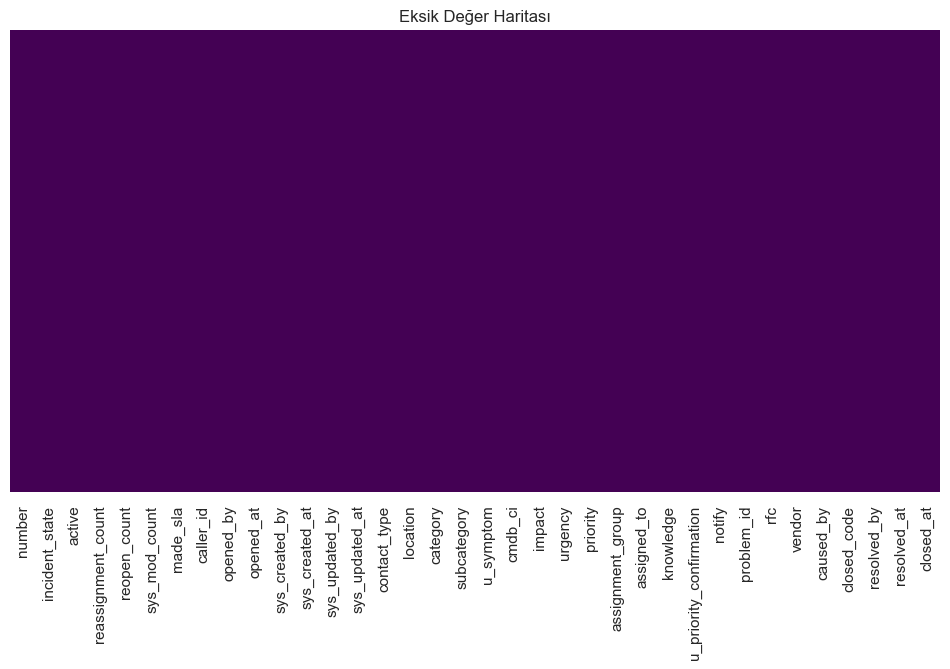

In [12]:
plt.figure(figsize=(12,6))

sns.heatmap(df.isnull(),
            cbar=False,
            yticklabels=False,
            cmap="viridis")

plt.title("Eksik Değer Haritası")
plt.show()

Yapılan inceleme sonucunda veri setinde eksik değer bulunmadığı görülmektedir. Bu nedenle eksik verilerin doldurulması veya silinmesi gibi ek veri temizleme işlemlerine ihtiyaç duyulmamaktadır. Eksik değer bulunmaması, veri setinin analiz için hazır durumda olduğunu göstermektedir.

## 4.2 Yinelenen kayıtlar

Tekrarlanan kayıtlar kontrol edilir.

In [13]:
duplicate_count = df.duplicated().sum()

print("Yinelenen kayıt sayısı:", duplicate_count)

Yinelenen kayıt sayısı: 0


Veri setinde yinelenen kayıt bulunmamaktadır. Bu durum, aynı gözlemin birden fazla kez yer almadığını ve analiz sonuçlarının tekrar eden kayıtlar nedeniyle yanlılık oluşturmayacağını göstermektedir. Veri kalitesi açısından bu olumlu bir bulgudur.

## 4.3 Veri tiplerinin düzenlenmesi

Tarih sütunları datetime formatına dönüştürülür.

In [14]:
date_columns = [
    "opened_at",
    "sys_created_at",
    "sys_updated_at",
    "resolved_at",
    "closed_at"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119998 entries, 0 to 119997
Data columns (total 36 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   number                   119998 non-null  object        
 1   incident_state           119998 non-null  object        
 2   active                   119998 non-null  bool          
 3   reassignment_count       119998 non-null  int64         
 4   reopen_count             119998 non-null  int64         
 5   sys_mod_count            119998 non-null  int64         
 6   made_sla                 119998 non-null  bool          
 7   caller_id                119998 non-null  object        
 8   opened_by                119998 non-null  object        
 9   opened_at                119998 non-null  datetime64[ns]
 10  sys_created_by           119998 non-null  object        
 11  sys_created_at           77644 non-null   datetime64[ns]
 12  sys_updated_by  

Veri tipleri incelendikten sonra tarih bilgisi içeren sütunlar datetime veri tipine dönüştürülmüştür. Böylece açılış, çözülme ve kapanış tarihleri arasında zaman farkları hesaplanabilecek ve işlem süreleri, bekleme süreleri ile yoğun saat analizleri gibi zaman tabanlı çalışmalar doğru şekilde gerçekleştirilebilecektir. Veri tiplerinin uygun formata dönüştürülmesi, hem veri analizi hem de makine öğrenmesi sürecinde oluşabilecek hataların önüne geçmektedir. Dönüştürme işlemi sonrasında veri tipleri başarıyla güncellenmiştir.

## 4.4 Hatalı değer kontrolü

Sayısal değişkenlerde aykırı değerler incelenir.

In [16]:
numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
reassignment_count,119998.0,1.151236,1.782823,0.0,0.0,1.0,2.0,27.0
reopen_count,119998.0,0.021025,0.196173,0.0,0.0,0.0,0.0,8.0
sys_mod_count,119998.0,5.199312,7.804628,0.0,1.0,3.0,7.0,129.0


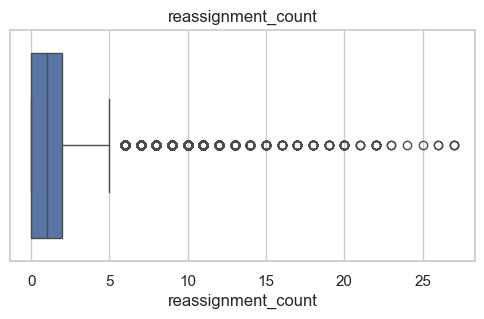

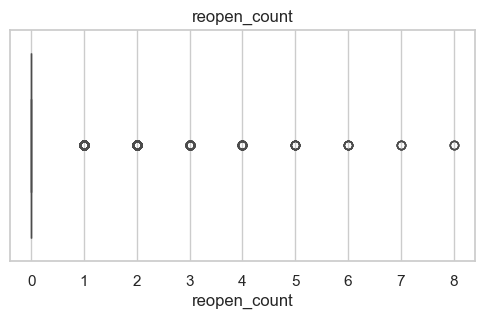

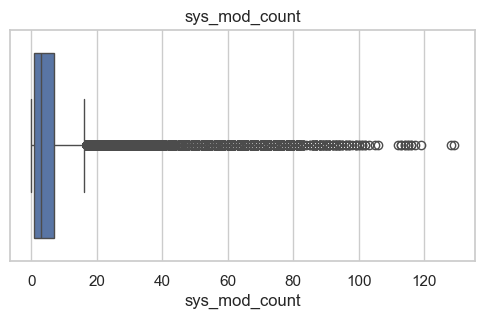

In [17]:
for col in numeric_columns:

    plt.figure(figsize=(6,3))

    sns.boxplot(x=df[col])

    plt.title(col)

    plt.show()

Sayısal değişkenler üzerinde yapılan incelemede bazı değişkenlerde aykırı değerlerin bulunduğu gözlemlenmiştir. Bu aykırı değerler, operasyonel süreçlerde normalden uzun süren veya olağan dışı incident kayıtlarını temsil edebileceğinden doğrudan veri hatası olarak değerlendirilmemiştir. Bu nedenle aykırı değerler silinmek yerine analiz sürecinde dikkate alınacak ve operasyonel performansın değerlendirilmesinde kullanılacaktır.

# 5. Keşifsel veri analizi (EDA)

Bu aşamada veri setindeki değişkenlerin dağılımları ve birbirleriyle ilişkileri incelenir.

## 5.1 Kategorik değişken analizi

Bu aşamada veri setindeki değişkenlerin dağılımları ve birbirleriyle ilişkileri incelenir.

In [18]:
categorical_columns = df.select_dtypes(include="object").columns

categorical_columns

Index(['number', 'incident_state', 'caller_id', 'opened_by', 'sys_created_by', 'sys_updated_by', 'contact_type', 'location', 'category', 'subcategory', 'u_symptom', 'cmdb_ci', 'impact', 'urgency', 'priority', 'assignment_group', 'assigned_to', 'notify', 'problem_id', 'rfc', 'vendor', 'caused_by', 'closed_code', 'resolved_by'], dtype='object')

In [19]:
for col in categorical_columns:

    print("="*60)
    print(col)
    print(df[col].value_counts().head(15))

number
number
INC0019396    58
INC0005927    46
INC0020718    45
INC0011206    44
INC0007349    43
INC0025734    43
INC0012815    40
INC0020849    38
INC0003419    38
INC0015902    37
INC0002129    36
INC0019739    35
INC0010322    34
INC0003256    33
INC0007229    33
Name: count, dtype: int64
incident_state
incident_state
Active                33582
New                   30229
Resolved              21500
Closed                20825
Awaiting User Info    12884
Awaiting Vendor         557
Awaiting Problem        400
Awaiting Evidence        19
-100                      2
Name: count, dtype: int64
caller_id
caller_id
Caller 1904    1421
Caller 290      727
Caller 4514     706
Caller 1441     259
Caller 3763     228
Caller 93       225
Caller 4414     224
Caller 2471     204
Caller 298      204
Caller 3479     201
Caller 90       195
Caller 3160     188
Caller 5093     187
Caller 156      186
Caller 4808     186
Name: count, dtype: int64
opened_by
opened_by
Opened by  17     33079
Opened 

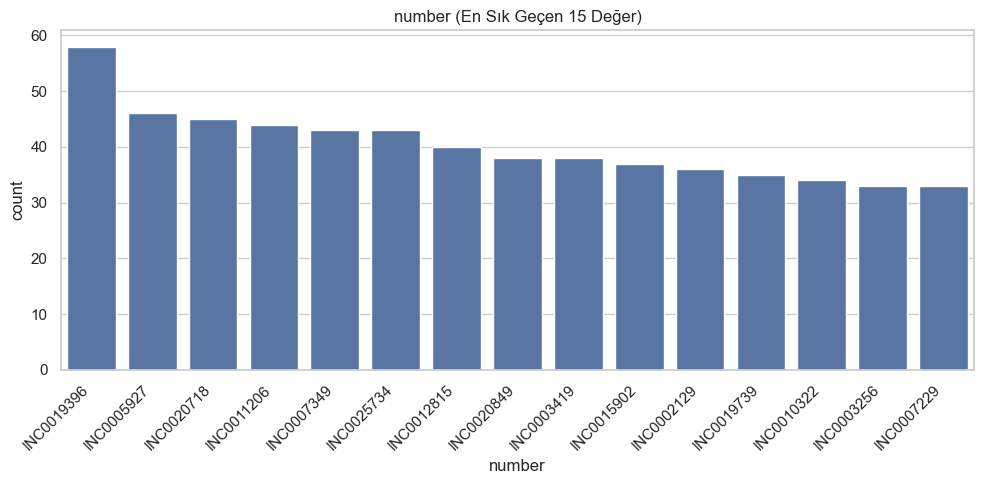

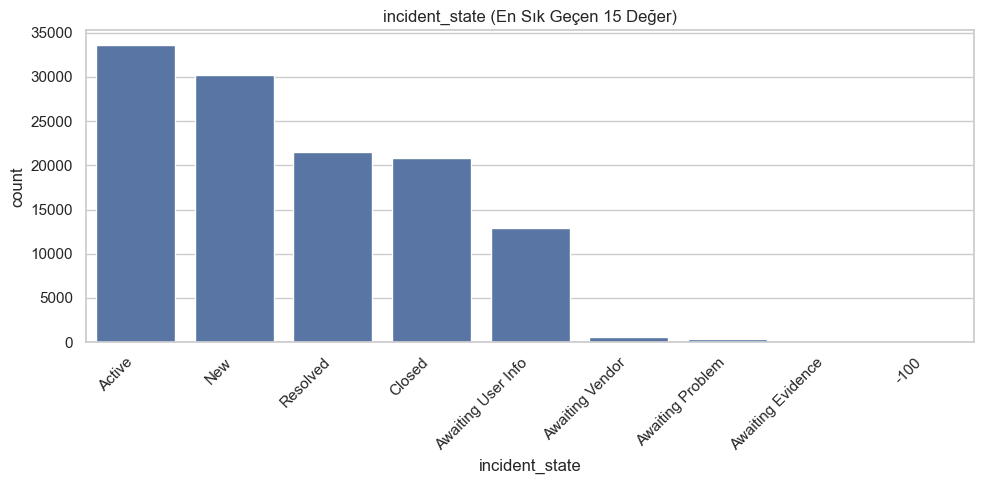

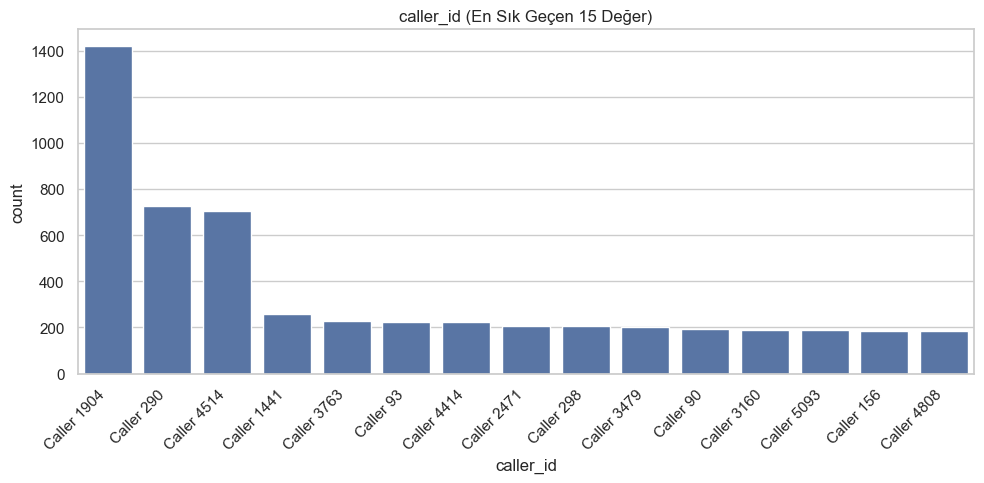

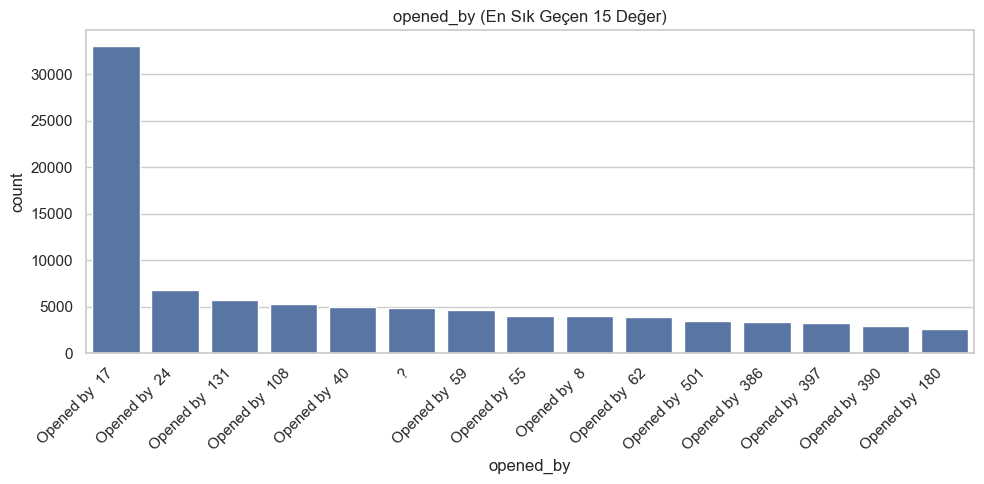

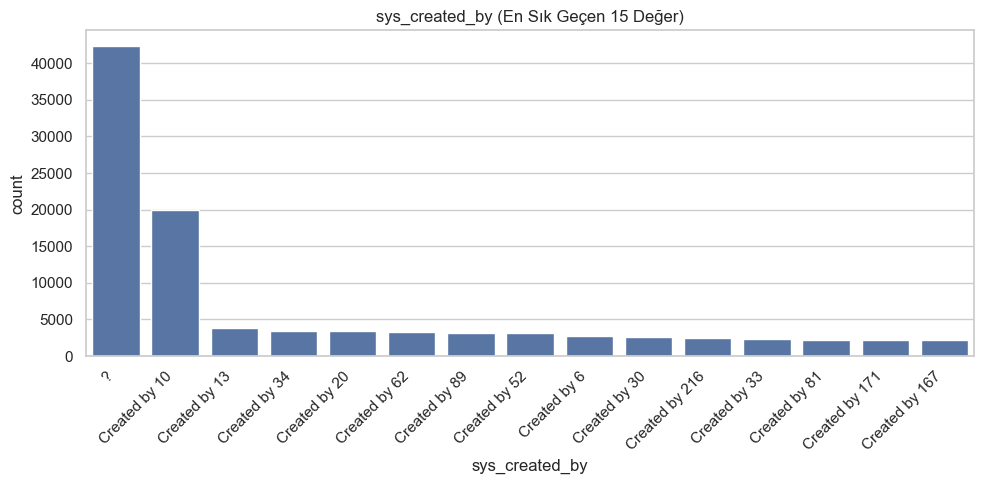

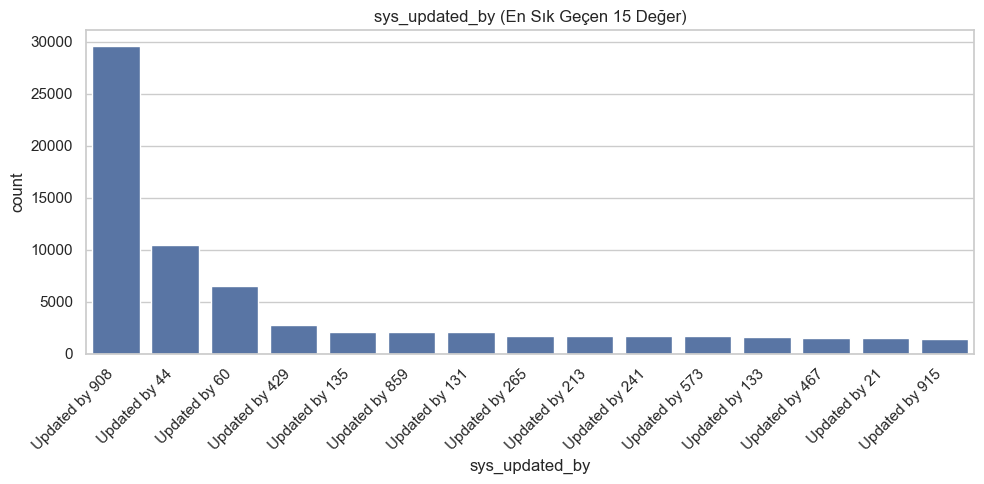

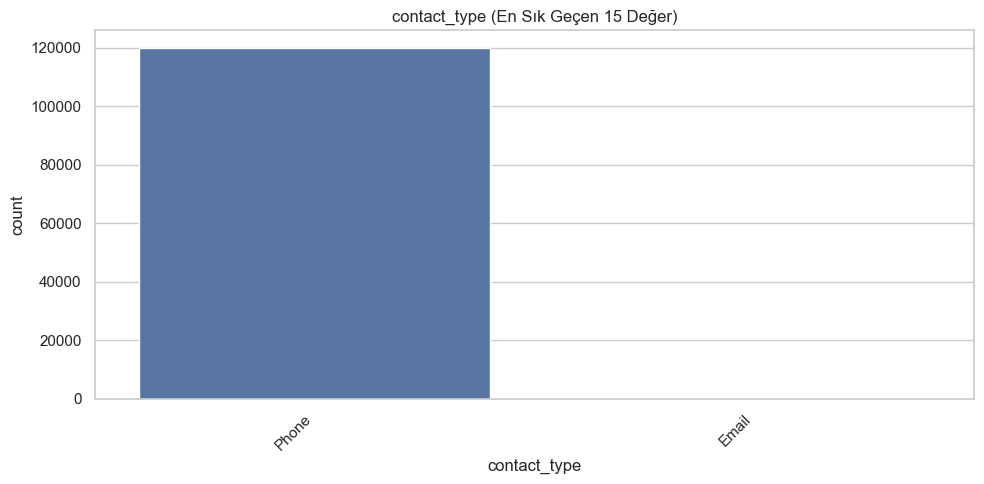

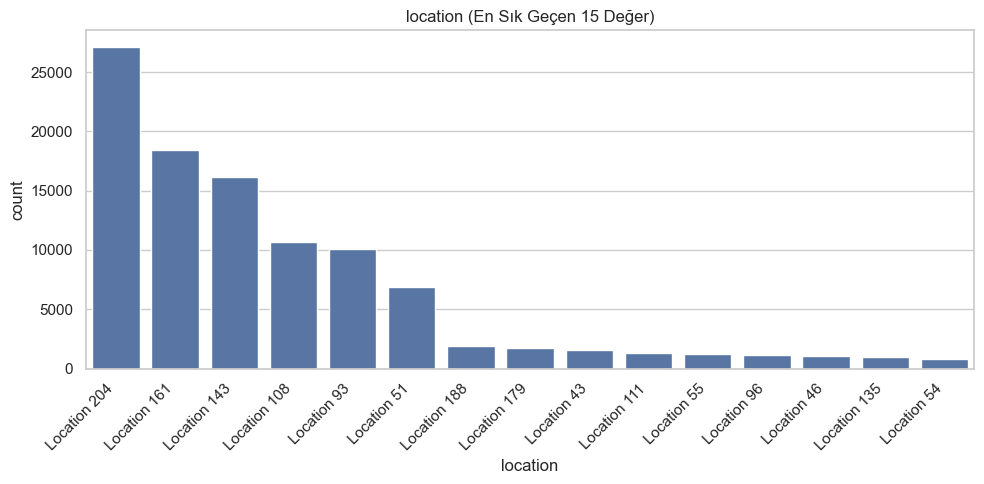

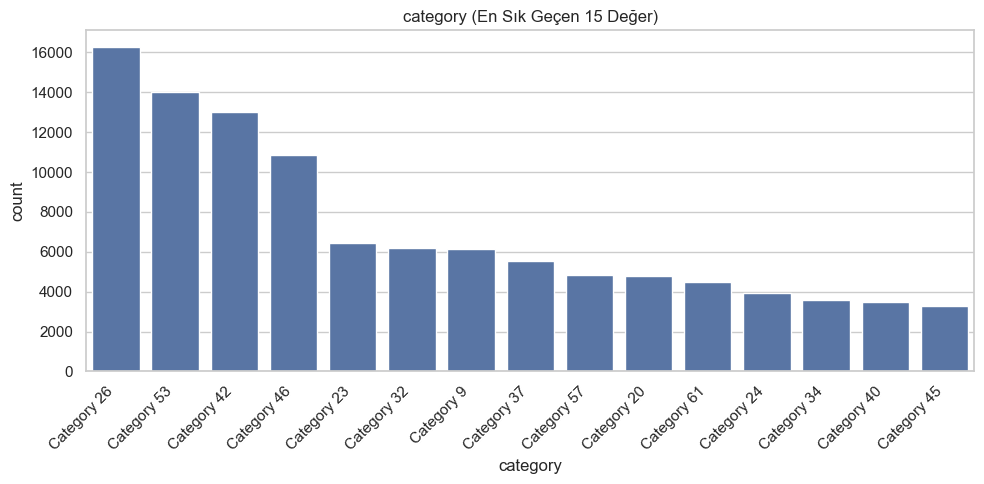

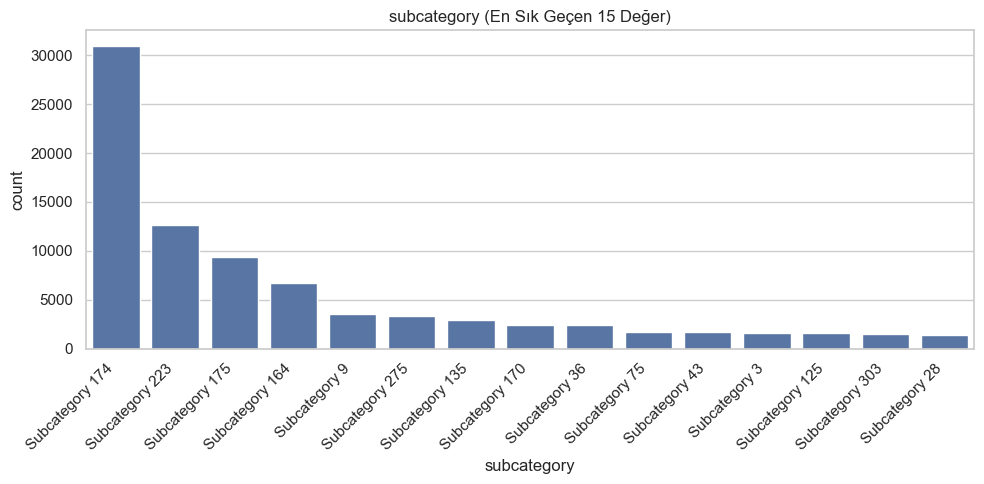

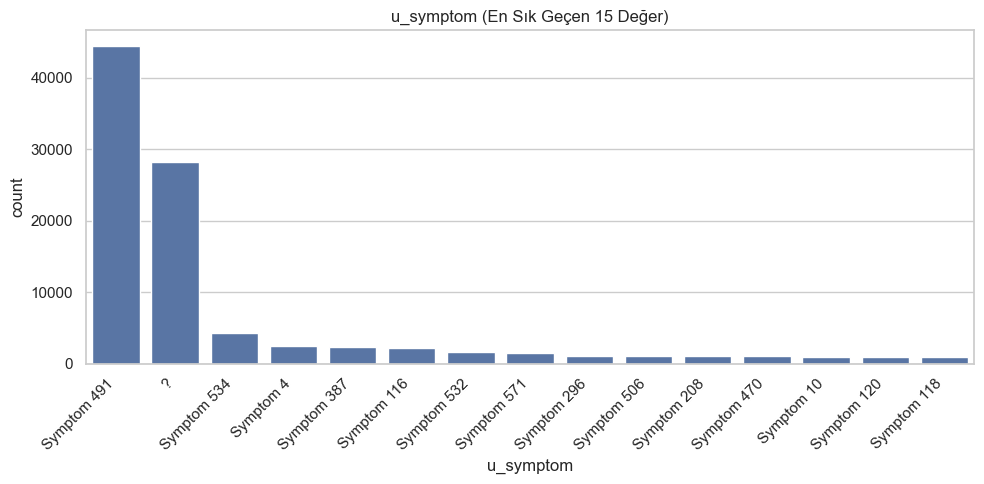

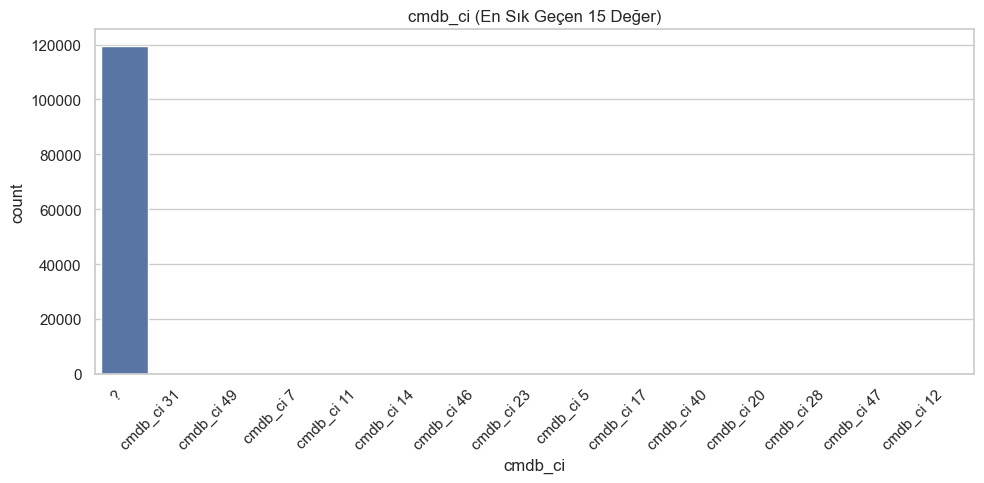

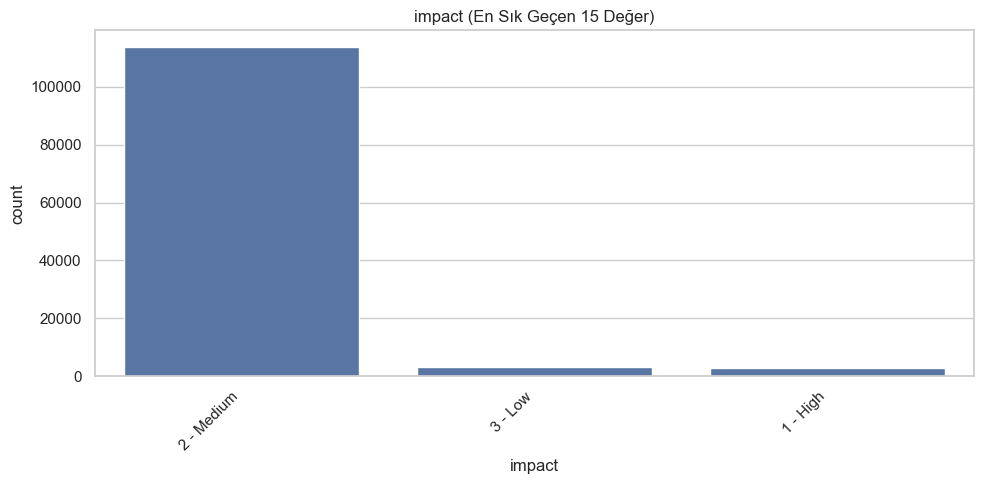

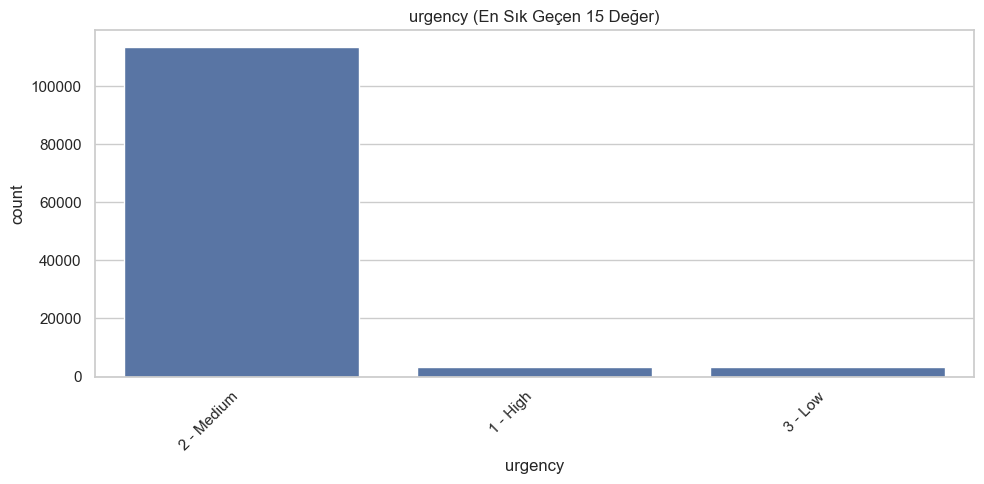

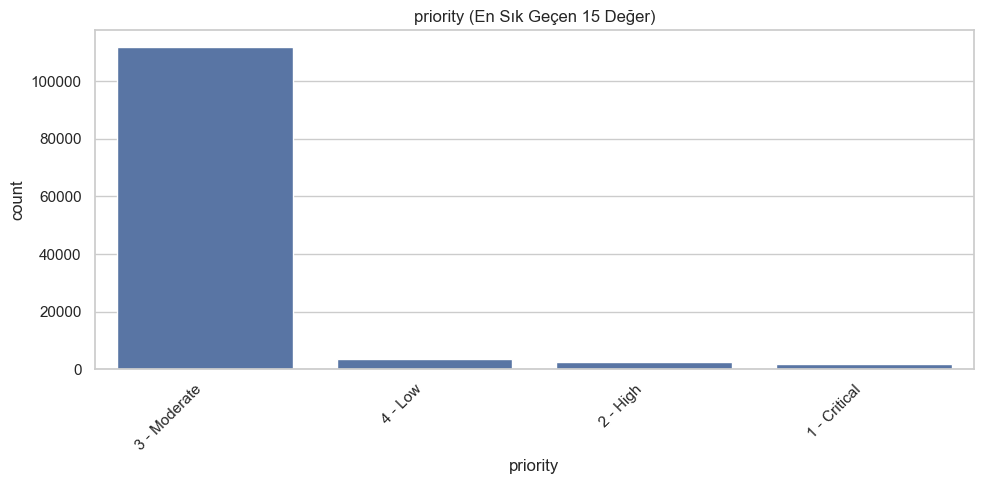

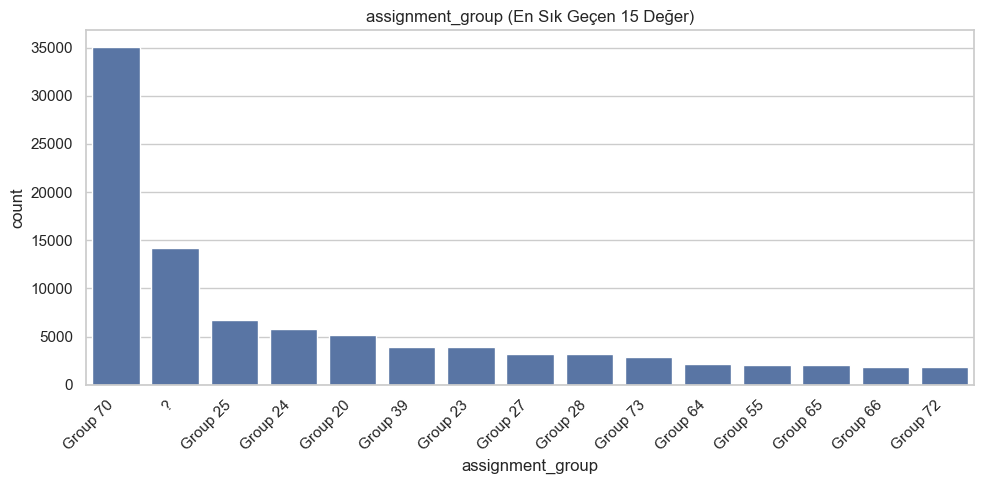

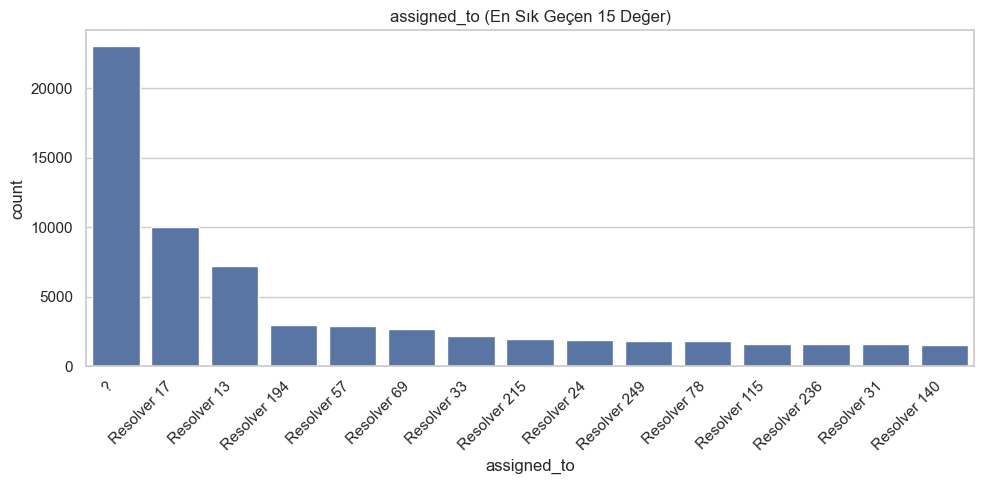

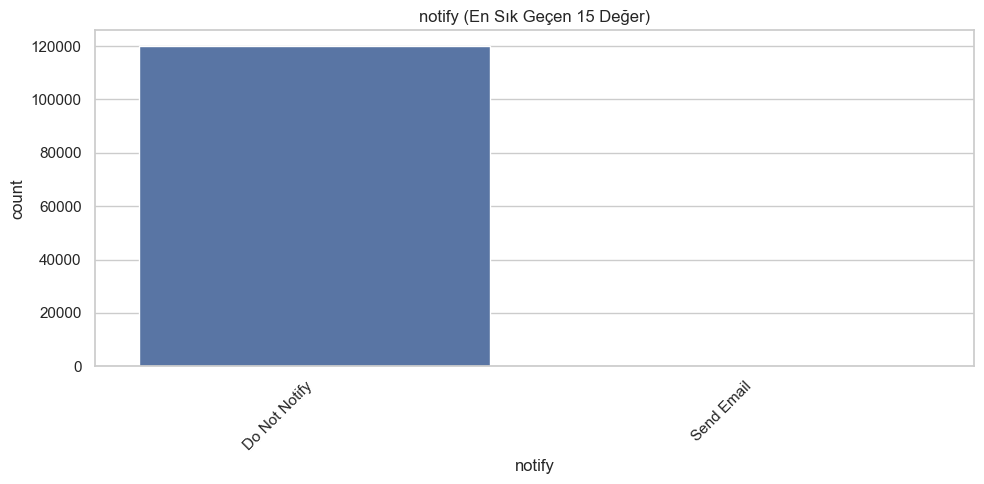

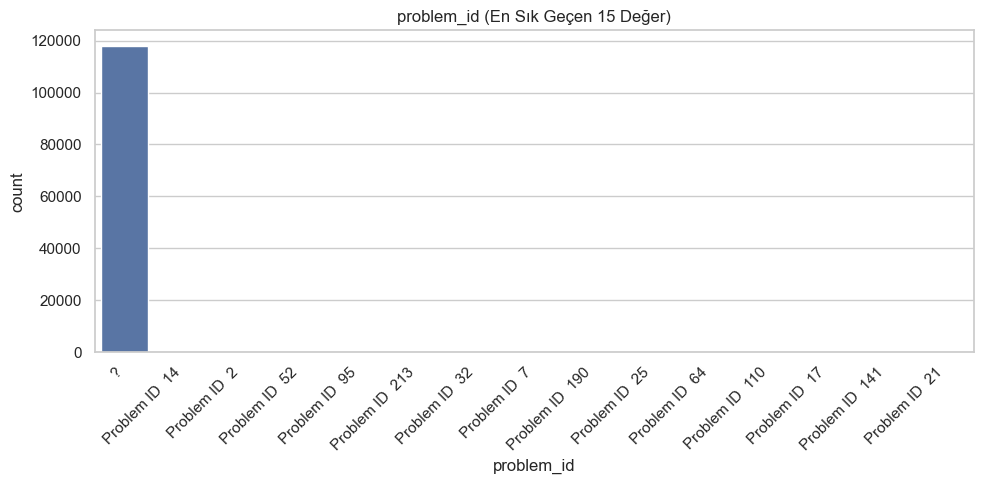

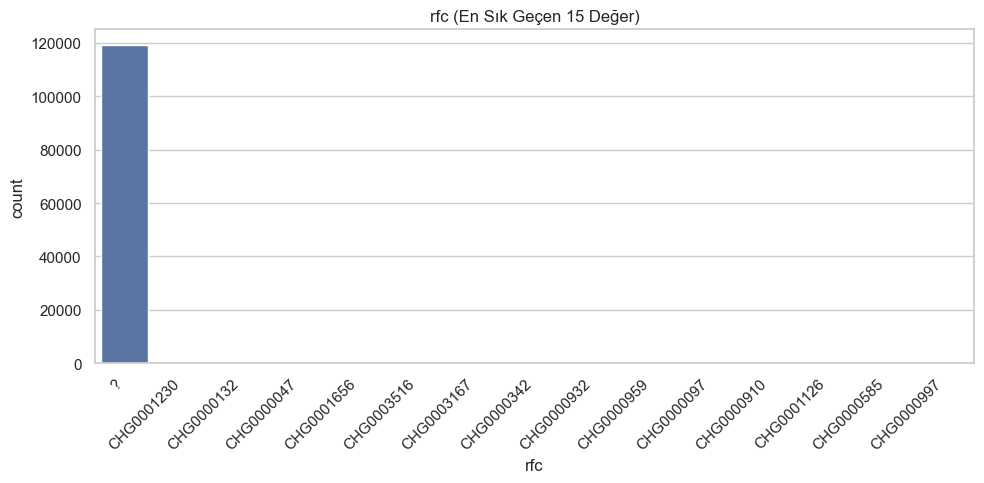

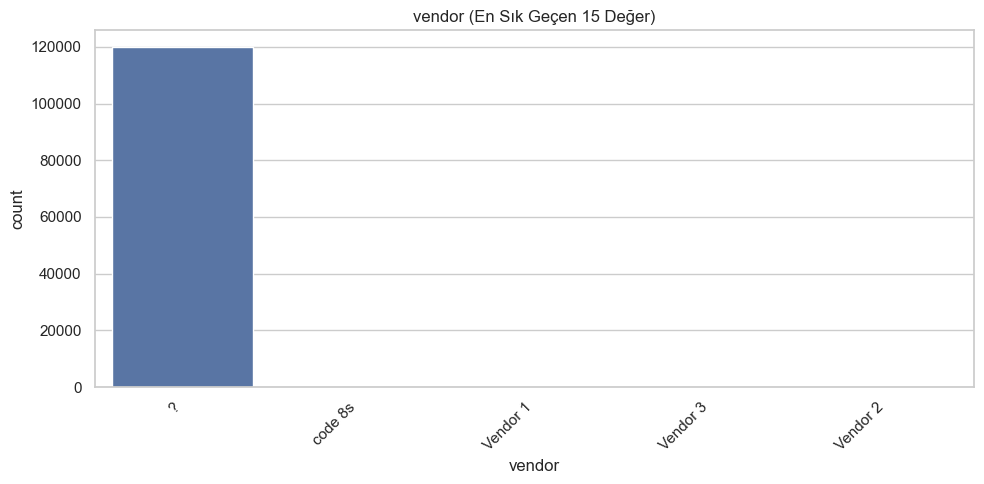

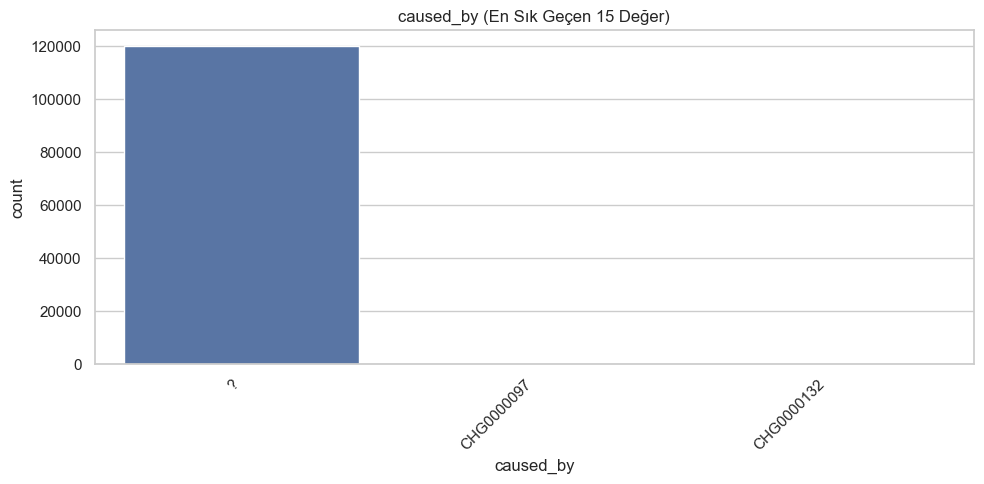

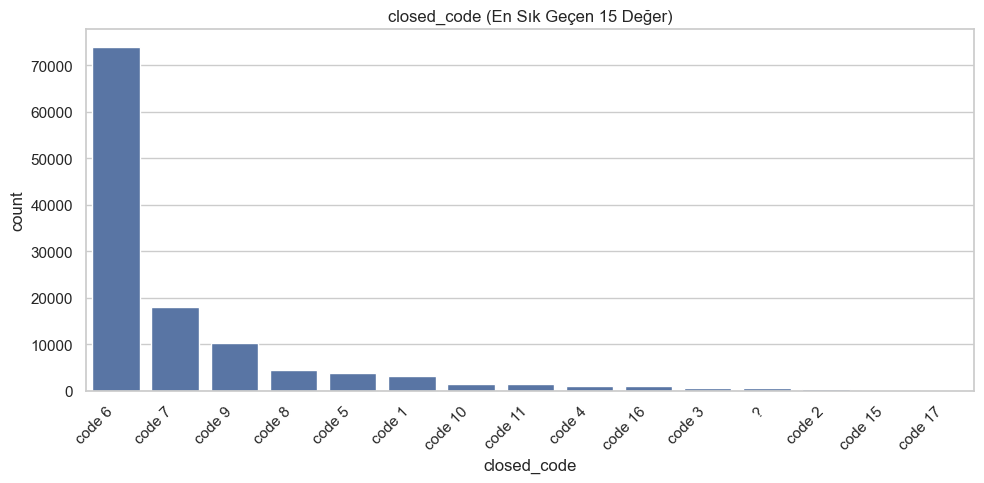

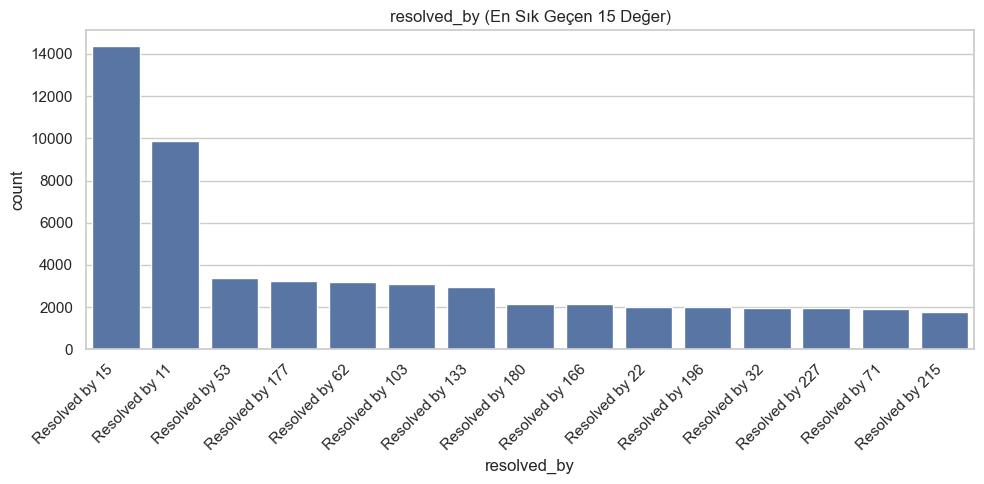

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in categorical_columns:
    # Sadece en popüler ilk 15 kategoriyi seçiyoruz
    top_categories = df[col].value_counts().head(15).index
    
    # Eğer sütun tamamen boşsa veya veri yoksa atla
    if len(top_categories) == 0:
        continue
        
    plt.figure(figsize=(10, 5))
    
    # Sadece seçtiğimiz ilk 15 kategoriyi içeren satırları filtreleyip çiziyoruz
    sns.countplot(
        data=df[df[col].isin(top_categories)],
        x=col,
        order=top_categories
    )
    
    plt.xticks(rotation=45, ha='right') # ha='right' yazıları daha düzgün hizalar
    plt.title(f"{col} (En Sık Geçen 15 Değer)")
    plt.tight_layout()
    plt.show()

Kategorik değişkenlerin frekans dağılımları incelendiğinde bazı kategorilerin diğerlerine göre oldukça baskın olduğu görülmektedir. Özellikle incident_state, priority, impact ve urgency değişkenlerinde belirli sınıfların veri setinin büyük kısmını oluşturduğu dikkat çekmektedir. Ayrıca bazı sütunlarda "?" değerlerinin bulunduğu görülmektedir. Bu değerler eksik veya bilinmeyen bilgileri temsil ediyor olabileceğinden özellik mühendisliği aşamasında ayrıca değerlendirilmelidir. Kategorik değişkenlerin dağılımı, ekip performansı, SLA analizi ve süreç değerlendirmelerinde önemli rol oynayacaktır.

## 5.2 Sayısal değişken analizi

Sayısal değişkenlerin dağılımları incelenir.

In [21]:
numeric_columns = df.select_dtypes(include=np.number).columns

In [22]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
reassignment_count,119998.0,1.151236,1.782823,0.0,0.0,1.0,2.0,27.0
reopen_count,119998.0,0.021025,0.196173,0.0,0.0,0.0,0.0,8.0
sys_mod_count,119998.0,5.199312,7.804628,0.0,1.0,3.0,7.0,129.0


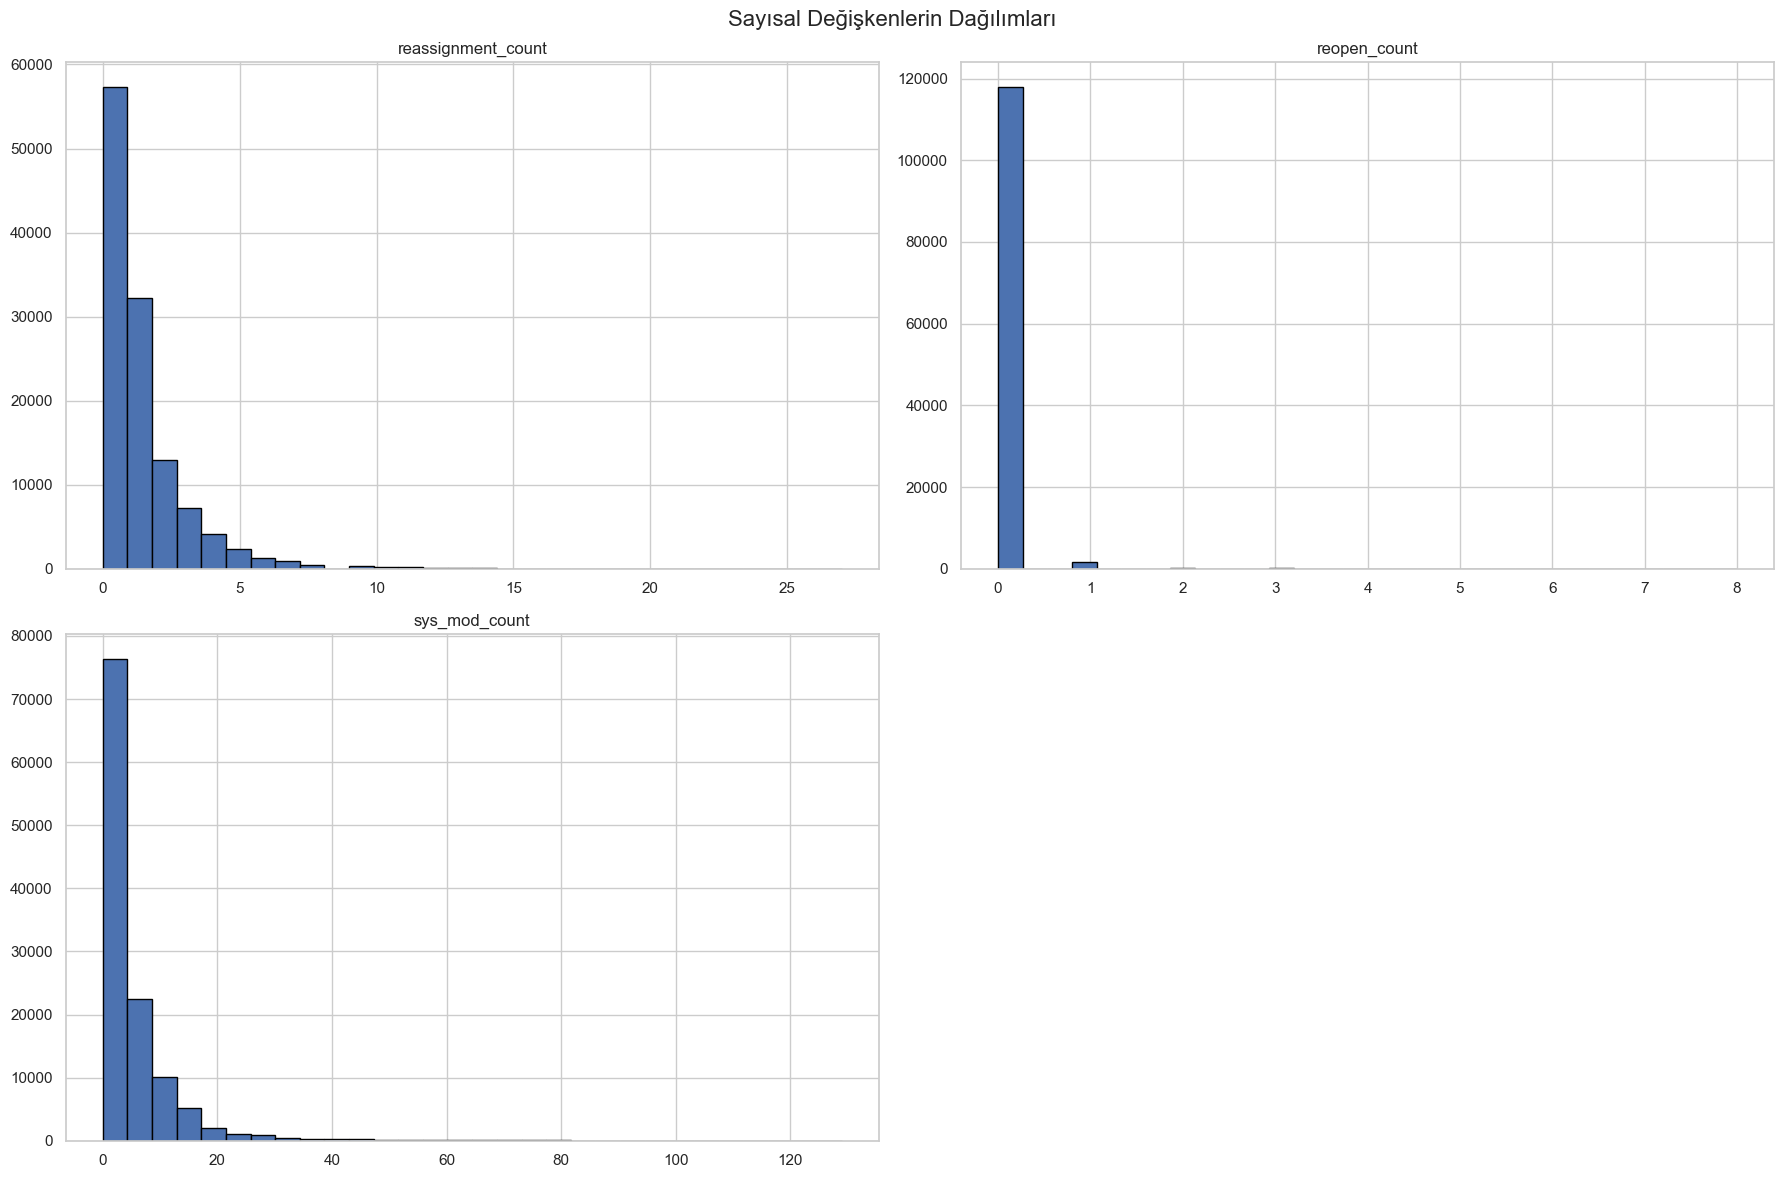

In [23]:
df[numeric_columns].hist(
    figsize=(18,12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Sayısal Değişkenlerin Dağılımları", fontsize=16)

plt.tight_layout()

plt.show()

Sayısal değişkenlerin dağılımları incelendiğinde değişkenlerin büyük çoğunluğunun normal dağılım göstermediği görülmektedir. Özellikle reassignment_count, reopen_count ve sys_mod_count değişkenlerinde kayıtların büyük kısmı düşük değerlerde yoğunlaşırken, az sayıda gözlem yüksek değerlere sahiptir. Bu durum dağılımın sağa çarpık (right-skewed) olduğunu göstermektedir.

Histogramlar incelendiğinde operasyonel süreçlerin büyük bölümünde yeniden atama ve yeniden açılma işlemlerinin sınırlı sayıda gerçekleştiği, ancak bazı incident kayıtlarında bu sayıların oldukça yüksek olduğu görülmektedir. Bu kayıtlar operasyonel açıdan daha karmaşık süreçleri veya çözümü uzun süren olayları temsil ediyor olabilir.

Boxplot grafiklerinde bazı sayısal değişkenlerde aykırı değerlerin bulunduğu gözlemlenmektedir. Özellikle yeniden atama sayısı ve sistem güncelleme sayısı gibi değişkenlerde normal dağılımın dışında kalan gözlemler dikkat çekmektedir.

Bu aykırı değerler veri giriş hatası olarak değerlendirilmemelidir. Incident yönetim sistemlerinde bazı kayıtların diğerlerine göre çok daha fazla işlem görmesi doğal bir durumdur. Bu nedenle aykırı değerlerin silinmesi yerine operasyonel süreçleri temsil eden önemli kayıtlar olarak değerlendirilmesi daha uygun olacaktır.

Genel olarak sayısal değişkenlerin dağılımı, veri setinde standart operasyonların yanında daha karmaşık ve uzun süren incident süreçlerinin de bulunduğunu göstermektedir.

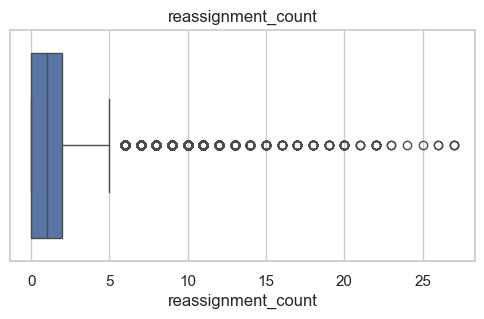

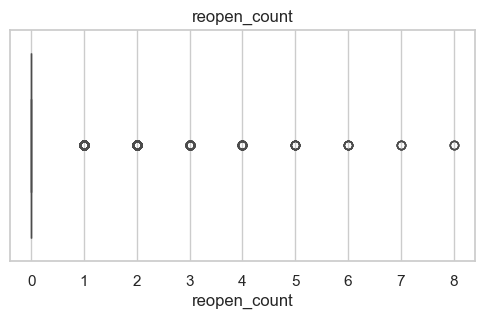

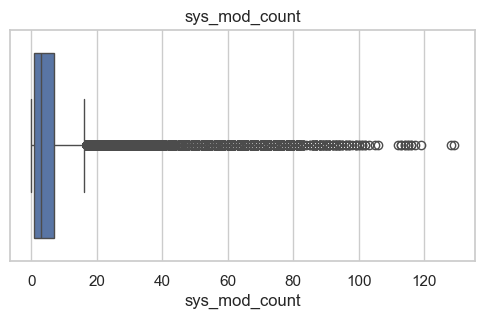

In [24]:
for col in numeric_columns:

    plt.figure(figsize=(6,3))

    sns.boxplot(x=df[col])

    plt.title(col)

    plt.show()

## 5.3 Korelasyon analizi

Sayısal değişkenler arasındaki doğrusal ilişkiler korelasyon matrisi ile incelenir.

In [25]:
correlation = df[numeric_columns].corr()

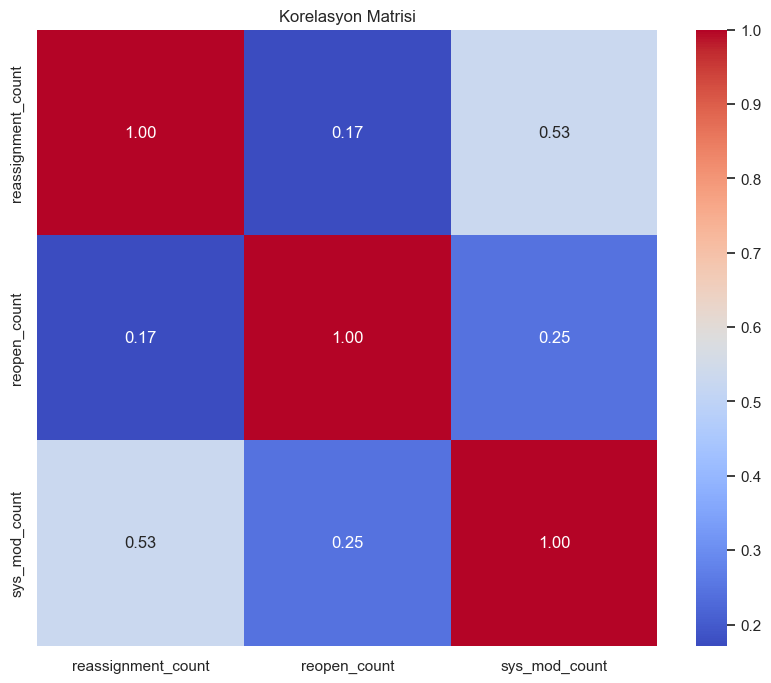

In [26]:
plt.figure(figsize=(10,8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Korelasyon Matrisi")

plt.show()

Sayısal değişkenler arasındaki doğrusal ilişkiler korelasyon matrisi kullanılarak incelenmiştir. Korelasyon matrisi incelendiğinde değişkenlerin büyük bölümünde düşük veya orta seviyede korelasyon bulunduğu görülmektedir. Bu durum, değişkenlerin birbirini tamamen tekrar etmediğini ve her birinin operasyonel süreç hakkında farklı bilgiler taşıdığını göstermektedir.

Bazı değişken çiftleri arasında pozitif korelasyon bulunması, ilgili değişkenlerin birlikte artma eğiliminde olduğunu göstermektedir. Bununla birlikte çok yüksek korelasyon değerlerinin bulunmaması, çoklu doğrusal bağlantı (multicollinearity) riskinin düşük olduğunu düşündürmektedir.

Makine öğrenmesi açısından değerlendirildiğinde sayısal değişkenlerin büyük kısmının modelde birlikte kullanılabilecek nitelikte olduğu söylenebilir. Ancak model oluşturulmadan önce özellik mühendisliği aşamasında değişkenlerin katkısı yeniden değerlendirilecek ve gerekli görülmesi halinde özellik seçimi uygulanacaktır.

# 6. Özellik Mühendisliği (Feature Engineering)

Bu bölümde, mevcut değişkenlerden yeni özellikler türetilerek veri seti zenginleştirilecektir. Oluşturulan yeni özellikler hem operasyonel performans analizinde hem de makine öğrenmesi modellerinde kullanılacaktır. Böylece veri setinin temsil gücü artırılarak daha anlamlı analizler ve daha başarılı tahmin modelleri oluşturulması hedeflenmektedir.

## 6.1 Tarih sütunlarının kontrolü

Yeni özellikler oluşturmadan önce tarih sütunlarının datetime veri tipinde olduğu kontrol edilir.

In [27]:
date_columns = [
    "opened_at",
    "sys_created_at",
    "sys_updated_at",
    "resolved_at",
    "closed_at"
]

df[date_columns].dtypes

opened_at         datetime64[ns]
sys_created_at    datetime64[ns]
sys_updated_at    datetime64[ns]
resolved_at       datetime64[ns]
closed_at         datetime64[ns]
dtype: object

Veri tipleri incelendiğinde analizde kullanılacak tüm tarih sütunlarının datetime64[ns] veri tipinde olduğu görülmektedir. Bu durum, tarih sütunlarının başarıyla dönüştürüldüğünü ve zaman tabanlı hesaplamaların güvenilir şekilde gerçekleştirilebileceğini göstermektedir. Özellikle işlem sürelerinin hesaplanması, yoğun saat analizleri ve yeni zaman özelliklerinin oluşturulması için veri seti uygun hale getirilmiştir.

## 6.2 İşlem süresinin hesaplanması (resolution time)

Incident'ın açıldığı zaman ile çözüldüğü zaman arasındaki süre hesaplanarak işlem süresi (resolution_time) oluşturulur. Bu değişken operasyonel performans analizinin en önemli değişkenlerinden biridir ve aynı zamanda makine öğrenmesi modelinde hedef değişken (target) olarak kullanılabilir.

In [28]:
df["resolution_time"] = (
    df["resolved_at"] - df["opened_at"]
).dt.total_seconds() / 3600

In [29]:
df[["opened_at",
    "resolved_at",
    "resolution_time"]].head()

,opened_at,resolved_at,resolution_time
0,2016-02-29 01:16:00,2016-02-29 11:29:00,10.216667
1,2016-02-29 01:16:00,2016-02-29 11:29:00,10.216667
2,2016-02-29 01:16:00,2016-02-29 11:29:00,10.216667
3,2016-02-29 01:16:00,2016-02-29 11:29:00,10.216667
4,2016-02-29 04:40:00,2016-03-01 09:52:00,29.200000


In [30]:
df["resolution_time"].describe()

count    117137.000000
mean        280.228157
std         666.212752
min           0.000000
25%           5.666667
50%          82.933333
75%         273.366667
max        8070.166667
Name: resolution_time, dtype: float64

resolution_time değişkeni, incident kayıtlarının açılış ve çözülme zamanları arasındaki süreyi saat cinsinden göstermektedir. Hesaplanan özet istatistiklere göre ortalama çözüm süresi yaklaşık 280 saat iken medyan değer yaklaşık 83 saattir. Ortalama değerin medyandan yüksek olması, bazı incident kayıtlarının oldukça uzun sürede çözüldüğünü ve dağılımın sağa çarpık olduğunu göstermektedir. Ayrıca maksimum çözüm süresinin yaklaşık 8070 saat olması, veri setinde oldukça uzun süren istisnai kayıtların bulunduğunu göstermektedir. Bu değişken, işlem süreleri analizi ve süre tahmini modellerinde temel özellik olarak kullanılacaktır.

## 6.3 Açılış saati (opened hour)

Incident kayıtlarının açıldığı saat bilgisi çıkarılarak opened_hour değişkeni oluşturulur. Bu değişken, özellikle yoğun saatlerin belirlenmesi ve makine öğrenmesi modelinde zaman bilgisinin kullanılabilmesi açısından önemlidir.

In [31]:
df["opened_hour"] = df["opened_at"].dt.hour

In [32]:
df[["opened_at", "opened_hour"]].head()

,opened_at,opened_hour
0,2016-02-29 01:16:00,1
1,2016-02-29 01:16:00,1
2,2016-02-29 01:16:00,1
3,2016-02-29 01:16:00,1
4,2016-02-29 04:40:00,4


Incident kayıtlarından açılış saati bilgisi başarıyla elde edilmiştir. Bu özellik sayesinde kayıtların günün hangi saatlerinde yoğunlaştığı analiz edilebilecek ve operasyonel yükün saat bazında dağılımı incelenebilecektir. Ayrıca opened_hour değişkeni, yoğun saat analizi ve makine öğrenmesi modellerinde zaman bilgisini temsil eden önemli bir özellik olarak kullanılacaktır.

## 6.4 Haftanın günü (opened weekday)

Incident'ın haftanın hangi gününde açıldığını belirlemek amacıyla opened_weekday değişkeni oluşturulur. Bu değişken yoğun gün analizlerinde ve operasyonel performans değerlendirmelerinde kullanılacaktır.

In [33]:
df["opened_weekday"] = df["opened_at"].dt.day_name()

In [34]:
df[["opened_at", "opened_weekday"]].head()

,opened_at,opened_weekday
0,2016-02-29 01:16:00,Monday
1,2016-02-29 01:16:00,Monday
2,2016-02-29 01:16:00,Monday
3,2016-02-29 01:16:00,Monday
4,2016-02-29 04:40:00,Monday


Incident kayıtlarının haftanın hangi gününde açıldığı belirlenerek opened_weekday değişkeni oluşturulmuştur. Bu değişken sayesinde hafta içi ve hafta sonu yoğunlukları karşılaştırılabilecek, belirli günlerde oluşan operasyonel yük analiz edilebilecektir. Ayrıca ekip planlaması ve kaynak yönetimi açısından haftalık iş dağılımının değerlendirilmesine katkı sağlayacaktır.

## 6.5 Açılış ayı (opened month)

Incident kayıtlarının açıldığı ay bilgisi çıkarılarak aylık yoğunluk analizlerinde kullanılacak opened_month değişkeni oluşturulur.

In [35]:
df["opened_month"] = df["opened_at"].dt.month_name()

In [36]:
df[["opened_at", "opened_month"]].head()

,opened_at,opened_month
0,2016-02-29 01:16:00,February
1,2016-02-29 01:16:00,February
2,2016-02-29 01:16:00,February
3,2016-02-29 01:16:00,February
4,2016-02-29 04:40:00,February


opened_month değişkeni oluşturularak incident kayıtlarının aylara göre dağılımının incelenebilmesi sağlanmıştır. Bu özellik sayesinde belirli dönemlerde yaşanan yoğunluk artışları veya azalışları analiz edilebilecek, operasyonel süreçlerde dönemsel eğilimler belirlenebilecektir. Aylık dağılım bilgisi, yönetimsel planlamalar ve kaynak tahsisi açısından da faydalı olacaktır.

## 6.6 Haftasonu bilgisi (is weekend)

Incident'ın hafta sonunda açılıp açılmadığını gösteren is_weekend değişkeni oluşturulur. Böylece hafta içi ve hafta sonu operasyon performansı karşılaştırılabilir.

In [37]:
df["is_weekend"] = df["opened_at"].dt.weekday >= 5

In [38]:
df[["opened_at", "is_weekend"]].head()

,opened_at,is_weekend
0,2016-02-29 01:16:00,False
1,2016-02-29 01:16:00,False
2,2016-02-29 01:16:00,False
3,2016-02-29 01:16:00,False
4,2016-02-29 04:40:00,False


is_weekend değişkeni ile incident kayıtlarının hafta sonu veya hafta içi açıldığı bilgisi elde edilmiştir. Bu özellik sayesinde hafta sonu performansı, işlem süreleri ve ekip yoğunluğu ayrı olarak değerlendirilebilecektir. Ayrıca hafta içi ve hafta sonu operasyonları arasındaki farklılıkların analiz edilmesine olanak sağlamaktadır.

## 6.7 Mesai saati bilgisi (is business hours)

Incident kayıtlarının mesai saatleri içerisinde açılıp açılmadığını belirlemek amacıyla is_business_hours değişkeni oluşturulur. Bu değişken mesai içi ve mesai dışı performans analizlerinde kullanılacaktır.

Burada mesai saatini 09:00–18:00 olarak kabul ediyoruz.

In [39]:
df["is_business_hours"] = df["opened_hour"].between(9, 18)

In [40]:
df[[
    "opened_at",
    "opened_hour",
    "is_business_hours"
]].head()

,opened_at,opened_hour,is_business_hours
0,2016-02-29 01:16:00,1,False
1,2016-02-29 01:16:00,1,False
2,2016-02-29 01:16:00,1,False
3,2016-02-29 01:16:00,1,False
4,2016-02-29 04:40:00,4,False


Incident kayıtlarının mesai saatleri içerisinde açılıp açılmadığını gösteren is_business_hours değişkeni oluşturulmuştur. Bu değişken sayesinde mesai saatleri içinde ve dışında oluşan incident kayıtları karşılaştırılabilecek, çalışma saatlerinin operasyonel performans üzerindeki etkisi değerlendirilebilecektir. Ayrıca vardiya planlaması ve kaynak kullanımının analiz edilmesinde önemli bir gösterge olacaktır.

## 6.8 Açılış günü (opened day)

Incident kayıtlarının ayın kaçıncı gününde açıldığını belirlemek amacıyla opened_day değişkeni oluşturulur.

In [41]:
df["opened_day"] = df["opened_at"].dt.day

In [42]:
df[["opened_at", "opened_day"]].head()

,opened_at,opened_day
0,2016-02-29 01:16:00,29
1,2016-02-29 01:16:00,29
2,2016-02-29 01:16:00,29
3,2016-02-29 01:16:00,29
4,2016-02-29 04:40:00,29


opened_day değişkeni oluşturularak incident kayıtlarının ayın hangi gününde açıldığı belirlenmiştir. Bu özellik sayesinde ay içerisindeki yoğunluk değişimleri analiz edilebilecek ve belirli günlerde oluşabilecek operasyonel artışlar tespit edilebilecektir. Bu bilgi özellikle aylık iş yükü planlamasında kullanılabilecek zaman tabanlı bir özelliktir.

## 6.9 Açılış çeyreği (opened quarter)

Yıl içerisindeki çeyrek dönem bilgisini elde etmek amacıyla opened_quarter değişkeni oluşturulur.

In [43]:
df["opened_quarter"] = df["opened_at"].dt.quarter

In [44]:
df[["opened_at", "opened_quarter"]].head()

,opened_at,opened_quarter
0,2016-02-29 01:16:00,1
1,2016-02-29 01:16:00,1
2,2016-02-29 01:16:00,1
3,2016-02-29 01:16:00,1
4,2016-02-29 04:40:00,1


opened_quarter değişkeni ile incident kayıtlarının yılın hangi çeyrek döneminde gerçekleştiği belirlenmiştir. Bu özellik, uzun dönemli performans analizlerinde ve dönemsel eğilimlerin incelenmesinde kullanılacaktır. Özellikle yönetim raporlarında çeyrek bazlı değerlendirmeler yapılmasına katkı sağlayacaktır.

## 6.10 Çalışma vardiyasi (work shift)

Incident kayıtları açılış saatine göre vardiyalara ayrılır. Bu özellik özellikle yoğun saatler ve ekip performansı analizlerinde kullanılacaktır.

In [45]:
def work_shift(hour):
    if 0 <= hour < 8:
        return "Night"
    elif 8 <= hour < 16:
        return "Day"
    else:
        return "Evening"

df["work_shift"] = df["opened_hour"].apply(work_shift)

In [46]:
df[["opened_hour", "work_shift"]].head()

,opened_hour,work_shift
0,1,Night
1,1,Night
2,1,Night
3,1,Night
4,4,Night


work_shift değişkeni oluşturularak incident kayıtları açılış saatlerine göre vardiyalara ayrılmıştır. Böylece gece, gündüz ve akşam vardiyalarındaki iş yükü karşılaştırılabilecek, hangi vardiyada daha fazla incident oluştuğu analiz edilebilecektir. Bu özellik ekip planlaması ve vardiya performansının değerlendirilmesinde kullanılacaktır.

## 6.11 Priority score

Eğer priority sütununda metin değerleri varsa (örneğin Low, Medium, High, Critical) bunları sayısal hale çevirebiliriz.

In [47]:
df["priority"].value_counts()

priority
3 - Moderate    112115
4 - Low           3549
2 - High          2499
1 - Critical      1835
Name: count, dtype: int64

In [48]:
priority_map = {
    "1 - Critical": 4,
    "2 - High": 3,
    "3 - Moderate": 2,
    "4 - Low": 1
}

df["priority_score"] = df["priority"].map(priority_map)

In [49]:
df[["priority", "priority_score"]].head()

,priority,priority_score
0,3 - Moderate,2
1,3 - Moderate,2
2,3 - Moderate,2
3,3 - Moderate,2
4,3 - Moderate,2


priority değişkeni sayısal forma dönüştürülerek priority_score değişkeni oluşturulmuştur. Veri seti incelendiğinde incident kayıtlarının büyük çoğunluğunun "3 - Moderate" öncelik seviyesinde olduğu görülmektedir. Sayısal dönüşüm sayesinde öncelik bilgisi makine öğrenmesi modellerinde doğrudan kullanılabilecek hale getirilmiş ve öncelik seviyelerinin işlem süreleri üzerindeki etkisi analiz edilebilir duruma gelmiştir.

## 6.12 Impact score

In [50]:
df["impact"].value_counts()

impact
2 - Medium    113691
3 - Low         3418
1 - High        2889
Name: count, dtype: int64

In [51]:
impact_map = {
    "1 - High": 3,
    "2 - Medium": 2,
    "3 - Low": 1
}

df["impact_score"] = df["impact"].map(impact_map)

In [52]:
df[["impact", "impact_score"]].head()

,impact,impact_score
0,2 - Medium,2
1,2 - Medium,2
2,2 - Medium,2
3,2 - Medium,2
4,2 - Medium,2


impact değişkeni sayısal forma dönüştürülerek impact_score değişkeni oluşturulmuştur. Veri setinde kayıtların büyük kısmının "2 - Medium" etki seviyesinde olduğu görülmektedir. Bu dönüşüm sayesinde incident kayıtlarının etki düzeyi sayısal olarak temsil edilmekte ve operasyonel analizler ile makine öğrenmesi modellerinde kullanılabilmektedir.

## 6.13 Urgency score

In [53]:
df["urgency"].value_counts()

urgency
2 - Medium    113550
1 - High        3303
3 - Low         3145
Name: count, dtype: int64

In [54]:
df["priority"].value_counts()

df["impact"].value_counts()

df["urgency"].value_counts()

urgency
2 - Medium    113550
1 - High        3303
3 - Low         3145
Name: count, dtype: int64

urgency değişkeni metin formatında tutulmaktadır. Makine öğrenmesi modellerinde kullanılabilmesi amacıyla sayısal bir değişkene dönüştürülmüştür. Sayısal değerler aciliğin önem derecesini temsil etmektedir.

In [55]:
urgency_map = {
    "1 - High": 3,
    "2 - Medium": 2,
    "3 - Low": 1
}

df["urgency_score"] = df["urgency"].map(urgency_map)

In [56]:
df[["urgency", "urgency_score"]].head()

,urgency,urgency_score
0,2 - Medium,2
1,2 - Medium,2
2,2 - Medium,2
3,2 - Medium,2
4,2 - Medium,2


urgency değişkeni sayısal forma dönüştürülerek urgency_score değişkeni oluşturulmuştur. İnceleme sonucunda incident kayıtlarının büyük bölümünün "2 - Medium" aciliyet seviyesinde olduğu görülmektedir. Sayısallaştırma işlemi sayesinde aciliyet seviyesi işlem süreleri, SLA başarısı ve makine öğrenmesi modelleri ile birlikte analiz edilebilecek duruma getirilmiştir.

## 6.14 Oluşturulan yeni özelliklerin kontrolü

Özellik mühendisliği sonucunda oluşturulan yeni değişkenler birlikte incelenerek başarıyla oluşturuldukları doğrulanır.

In [57]:
new_features = [
    "resolution_time",
    "opened_hour",
    "opened_weekday",
    "opened_month",
    "opened_day",
    "opened_quarter",
    "is_weekend",
    "is_business_hours",
    "work_shift",
    "priority_score",
    "impact_score",
    "urgency_score"
]

df[new_features].head()

,resolution_time,opened_hour,opened_weekday,opened_month,opened_day,opened_quarter,is_weekend,is_business_hours,work_shift,priority_score,impact_score,urgency_score
0,10.216667,1,Monday,February,29,1,False,False,Night,2,2,2
1,10.216667,1,Monday,February,29,1,False,False,Night,2,2,2
2,10.216667,1,Monday,February,29,1,False,False,Night,2,2,2
3,10.216667,1,Monday,February,29,1,False,False,Night,2,2,2
4,29.200000,4,Monday,February,29,1,False,False,Night,2,2,2


Özellik mühendisliği sonucunda oluşturulan tüm yeni değişkenler birlikte incelenmiş ve başarıyla veri setine eklendiği doğrulanmıştır. Oluşturulan özellikler zaman bilgisi, işlem süresi, çalışma düzeni ve operasyonel öncelik gibi farklı boyutları temsil etmektedir. Böylece veri seti hem operasyonel performans analizleri hem de makine öğrenmesi modelleri için daha zengin ve açıklayıcı bir yapıya kavuşturulmuştur.

# 7. Operasyonel performans analizi

## 7.1 Resolution time analysis (İşlem süresi analizi)

Bu bölümde incident kayıtlarının çözülme süreleri incelenerek operasyonel performans değerlendirilecektir. Daha önce oluşturulan resolution_time (İşlem Süresi) değişkeni kullanılarak temel istatistikler hesaplanacak, dağılımlar görselleştirilecek ve işlem sürelerinin öncelik (Priority), etki düzeyi (Impact), aciliyet (Urgency), ekip (Assignment Group) ve kategori (Category) gibi değişkenlere göre nasıl değiştiği analiz edilecektir.

### 7.1.1 Resolution time statistics (İşlem süresi istatistikleri)

İlk olarak resolution_time (İşlem Süresi) değişkeninin temel istatistikleri incelenir. Böylece incident kayıtlarının ortalama ne kadar sürede çözüldüğü, en kısa ve en uzun çözüm süreleri ile dağılımın genel yapısı hakkında bilgi edinilir.

In [58]:
# Resolution Time (İşlem Süresi) istatistikleri

resolution_stats = df["resolution_time"].describe()

print(resolution_stats)

count    117137.000000
mean        280.228157
std         666.212752
min           0.000000
25%           5.666667
50%          82.933333
75%         273.366667
max        8070.166667
Name: resolution_time, dtype: float64


**Ortalama, Medyan ve Standart Sapma**

Temel istatistiklerin daha okunabilir şekilde incelenebilmesi amacıyla ortalama (Mean), medyan (Median) ve standart sapma (Standard Deviation) ayrı olarak hesaplanmaktadır.

In [59]:
print(f"Ortalama İşlem Süresi : {df['resolution_time'].mean():.2f} saat")
print(f"Medyan İşlem Süresi   : {df['resolution_time'].median():.2f} saat")
print(f"Standart Sapma        : {df['resolution_time'].std():.2f} saat")
print(f"Minimum Süre          : {df['resolution_time'].min():.2f} saat")
print(f"Maksimum Süre         : {df['resolution_time'].max():.2f} saat")

Ortalama İşlem Süresi : 280.23 saat
Medyan İşlem Süresi   : 82.93 saat
Standart Sapma        : 666.21 saat
Minimum Süre          : 0.00 saat
Maksimum Süre         : 8070.17 saat


resolution_time değişkeninin temel istatistikleri incelendiğinde toplam 117.137 incident kaydının işlem süresine sahip olduğu görülmektedir. Ortalama işlem süresi yaklaşık 280,23 saat iken medyan değer 82,93 saat olarak hesaplanmıştır. Ortalama değerin medyandan oldukça yüksek olması, veri setinde uzun sürede çözülen incident kayıtlarının bulunduğunu ve dağılımın sağa çarpık olduğunu göstermektedir. Ayrıca maksimum işlem süresinin 8070,17 saat olması, bazı kayıtların olağan dışı uzun sürelerde çözüldüğünü göstermektedir. Standart sapmanın yüksek olması ise işlem sürelerinde önemli ölçüde değişkenlik bulunduğunu ortaya koymaktadır.

### 7.1.2 Resolution time distribution (İşlem süresi dağılımı)

Histogram grafiği kullanılarak işlem sürelerinin hangi değer aralıklarında yoğunlaştığı incelenmektedir. Bu grafik sayesinde dağılımın normal olup olmadığı ve uzun süren incident kayıtlarının bulunup bulunmadığı değerlendirilebilir.

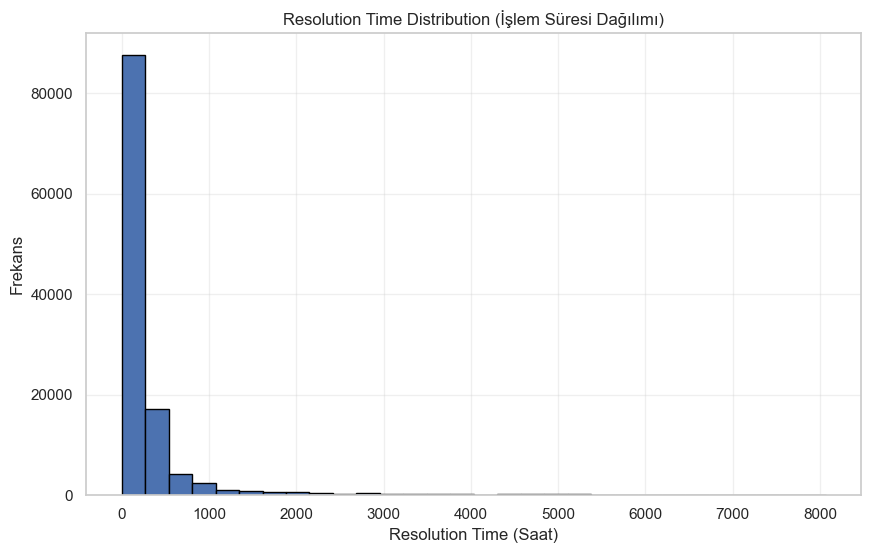

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.hist(
    df["resolution_time"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.title("Resolution Time Distribution (İşlem Süresi Dağılımı)")
plt.xlabel("Resolution Time (Saat)")
plt.ylabel("Frekans")

plt.grid(alpha=0.3)

plt.show()

Histogram grafiği incelendiğinde incident kayıtlarının büyük bölümünün düşük işlem sürelerinde yoğunlaştığı görülmektedir. İşlem süresi arttıkça kayıt sayısı belirgin şekilde azalmaktadır. Dağılım normal dağılım göstermemekte, sağ tarafa doğru uzun bir kuyruk oluşturmaktadır. Bu durum veri setinde az sayıda fakat oldukça uzun sürede çözülen incident kayıtlarının bulunduğunu göstermektedir.

### 7.1.3 Resolution time boxplot (İşlem süresi kutu grafiği)

Boxplot (Kutu Grafiği) kullanılarak işlem sürelerinin dağılımı ve aykırı değerler (Outliers) incelenmektedir. Bu analiz sayesinde olağan dışı uzun süren incident kayıtları tespit edilebilir.

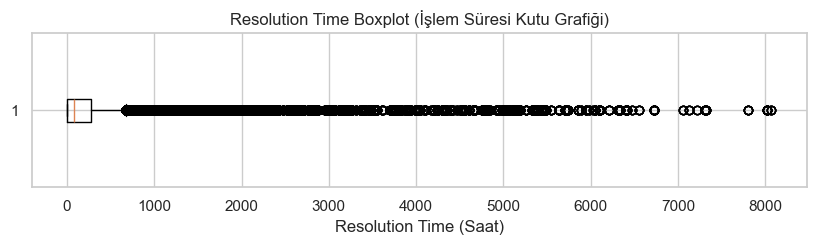

In [61]:
plt.figure(figsize=(10,2))

plt.boxplot(
    df["resolution_time"].dropna(),
    vert=False
)

plt.title("Resolution Time Boxplot (İşlem Süresi Kutu Grafiği)")
plt.xlabel("Resolution Time (Saat)")

plt.show()

Boxplot grafiği işlem sürelerinde çok sayıda aykırı değer (Outlier) bulunduğunu göstermektedir. Kayıtların büyük bölümü kısa sürelerde çözülmesine rağmen bazı incident kayıtlarının çözüm süresi oldukça yüksektir. Bu aykırı değerler ortalama işlem süresini yükseltmekte olup operasyonel süreçlerde gecikmeye neden olan kayıtların ayrıca incelenmesi gerektiğini göstermektedir.

### 7.1.4 Resolution time by priority (Önceliğine göre işlem süresi)

Bu analizde incident kayıtlarının Priority (Öncelik) seviyelerine göre ortalama işlem süreleri incelenmektedir. Böylece kritik öneme sahip kayıtların gerçekten daha kısa sürede çözülüp çözülmediği ve öncelik seviyesinin çözüm süresi üzerindeki etkisi değerlendirilebilir.

In [62]:
priority_resolution = (
    df.groupby("priority")["resolution_time"]
      .mean()
      .sort_values(ascending=False)
)

priority_resolution

priority
4 - Low         452.696037
3 - Moderate    277.420249
1 - Critical    251.946948
2 - High        191.445572
Name: resolution_time, dtype: float64

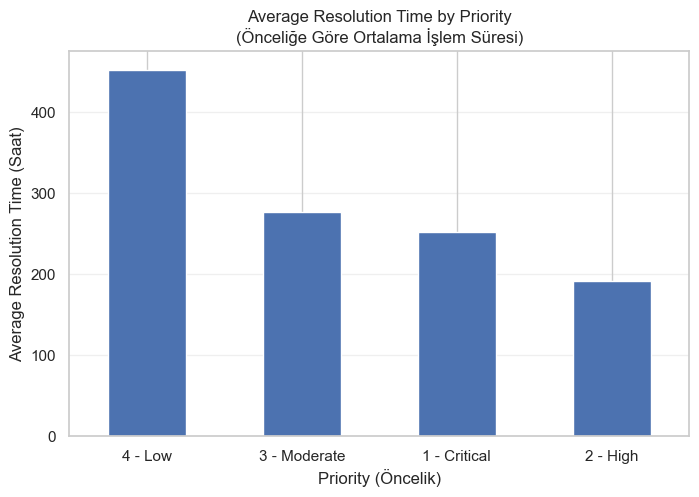

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

priority_resolution.plot(kind="bar")

plt.title("Average Resolution Time by Priority\n(Önceliğe Göre Ortalama İşlem Süresi)")
plt.xlabel("Priority (Öncelik)")
plt.ylabel("Average Resolution Time (Saat)")
plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.show()

Öncelik seviyelerine göre ortalama işlem süreleri incelendiğinde en uzun çözüm süresinin "4 - Low" öncelikli incident kayıtlarında (452,70 saat) olduğu görülmektedir. Buna karşılık "2 - High" öncelikli kayıtlar ortalama 191,45 saat ile en kısa çözüm süresine sahiptir. Bu sonuç, yüksek öncelikli incident kayıtlarına daha hızlı müdahale edildiğini ve düşük öncelikli kayıtların ise daha uzun süre bekleyebildiğini göstermektedir.

### 7.1.5 Resolution time by ımpact (Etki düzeyine göre işlem süresi)

Bu bölümde Impact (Etki Düzeyi) ile işlem süresi arasındaki ilişki incelenmektedir. Etki düzeyi yüksek incident kayıtlarının çözüm sürelerinin diğer seviyelere göre farklılık gösterip göstermediği analiz edilmektedir.

In [64]:
impact_resolution = (
    df.groupby("impact")["resolution_time"]
      .mean()
      .sort_values(ascending=False)
)

impact_resolution

impact
3 - Low       432.665421
2 - Medium    277.214007
1 - High      225.194918
Name: resolution_time, dtype: float64

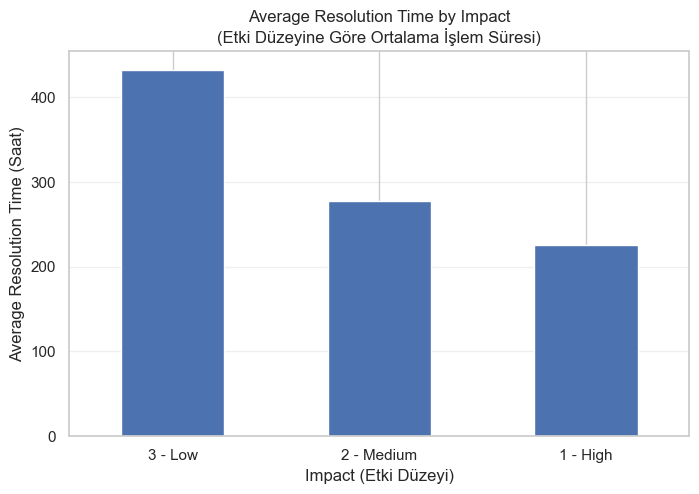

In [65]:
plt.figure(figsize=(8,5))

impact_resolution.plot(kind="bar")

plt.title("Average Resolution Time by Impact\n(Etki Düzeyine Göre Ortalama İşlem Süresi)")
plt.xlabel("Impact (Etki Düzeyi)")
plt.ylabel("Average Resolution Time (Saat)")
plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.show()

Etki düzeyine göre yapılan analizde "3 - Low" etki seviyesine sahip incident kayıtlarının ortalama işlem süresinin (432,67 saat) en yüksek olduğu görülmektedir. Buna karşılık "1 - High" etki seviyesindeki kayıtların ortalama çözüm süresi 225,19 saat olarak hesaplanmıştır. Bu durum, operasyon üzerinde yüksek etkiye sahip incident kayıtlarının öncelikli olarak ele alındığını ve daha kısa sürede çözüldüğünü göstermektedir.

### 7.1.6 Resolution time by urgency (Aciliyet düzeyine göre işlem süresi)

Bu analizde Urgency (Aciliyet) seviyelerine göre ortalama işlem süreleri karşılaştırılmaktadır. Böylece yüksek aciliyetli incident kayıtlarının daha hızlı çözülüp çözülmediği değerlendirilmektedir.

In [66]:
urgency_resolution = (
    df.groupby("urgency")["resolution_time"]
      .mean()
      .sort_values(ascending=False)
)

urgency_resolution

urgency
3 - Low       431.709815
2 - Medium    277.670505
1 - High      230.098325
Name: resolution_time, dtype: float64

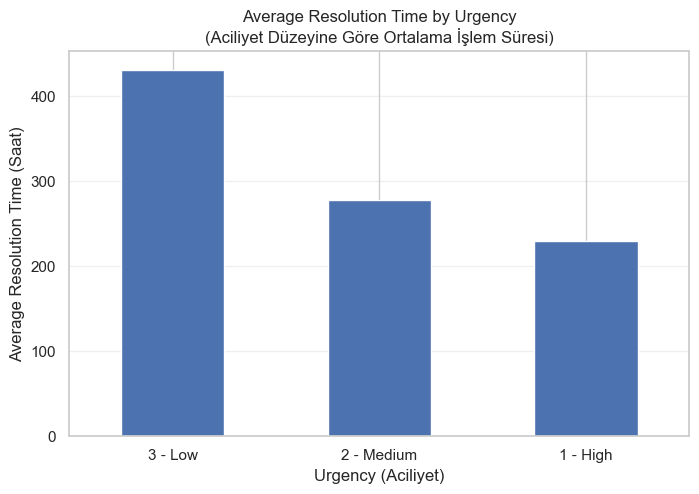

In [67]:
plt.figure(figsize=(8,5))

urgency_resolution.plot(kind="bar")

plt.title("Average Resolution Time by Urgency\n(Aciliyet Düzeyine Göre Ortalama İşlem Süresi)")
plt.xlabel("Urgency (Aciliyet)")
plt.ylabel("Average Resolution Time (Saat)")
plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.show()

Aciliyet seviyelerine göre ortalama işlem süreleri incelendiğinde "3 - Low" aciliyet seviyesindeki incident kayıtlarının en uzun sürede çözüldüğü (431,71 saat) görülmektedir. Buna karşılık "1 - High" aciliyet seviyesine sahip kayıtların ortalama çözüm süresi 230,10 saat ile daha düşüktür. Bu sonuç, yüksek aciliyetli incident kayıtlarının öncelikli olarak ele alındığını ve daha hızlı çözüldüğünü göstermektedir.

### 7.1.7 Resolution time by assignment group (Atama grubun göre işlem süresi)

Bu bölümde incident kayıtlarının atandığı ekiplerin (Assignment Group) ortalama işlem süreleri karşılaştırılmaktadır. Böylece en hızlı ve en yavaş çözüm gerçekleştiren ekipler belirlenebilir.

In [68]:
assignment_resolution = (
    df.groupby("assignment_group")["resolution_time"]
      .mean()
      .sort_values(ascending=False)
)

assignment_resolution.head(10)

assignment_group
Group 9     2730.363504
Group 35    2612.654393
Group 63    2472.456098
Group 67    2155.943989
Group 4     1872.683333
Group 61    1601.491542
Group 15    1481.569236
Group 2     1440.223889
Group 31    1083.942982
Group 3     1021.579131
Name: resolution_time, dtype: float64

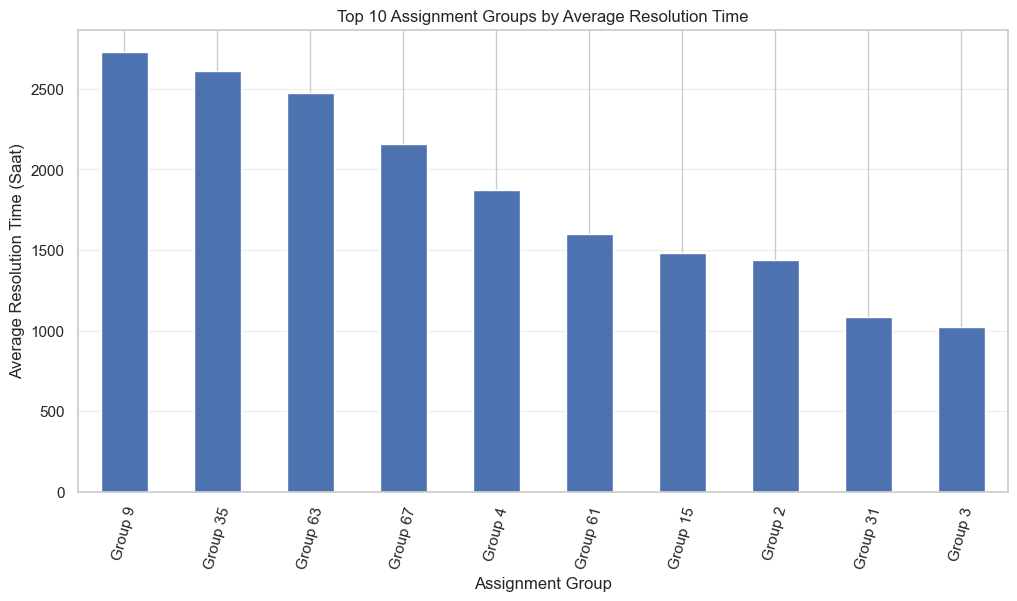

In [69]:
plt.figure(figsize=(12,6))

assignment_resolution.head(10).plot(kind="bar")

plt.title("Top 10 Assignment Groups by Average Resolution Time")
plt.xlabel("Assignment Group")
plt.ylabel("Average Resolution Time (Saat)")

plt.xticks(rotation=75)

plt.grid(axis="y", alpha=0.3)

plt.show()

Atama gruplarına göre ortalama işlem süreleri karşılaştırıldığında ekipler arasında önemli farklılıklar olduğu görülmektedir. Özellikle Group 9, Group 35 ve Group 63 en yüksek ortalama işlem sürelerine sahip ekipler olarak dikkat çekmektedir. Bu durum bazı ekiplerde iş yükü, kaynak yetersizliği veya süreç yönetimi gibi nedenlerden kaynaklanabilecek darboğazların bulunduğunu düşündürmektedir. Operasyonel performansın artırılması için bu ekiplerin daha ayrıntılı incelenmesi faydalı olacaktır.

### 7.1.8 Resolution time by category (Kategoriye göre işlem süresi)

Incident kategorilerine göre ortalama işlem süreleri analiz edilerek hangi kategorilerde çözüm süreçlerinin daha uzun sürdüğü belirlenmektedir.

In [70]:
category_resolution = (
    df.groupby("category")["resolution_time"]
      .mean()
      .sort_values(ascending=False)
)

category_resolution

category
Category 29    2340.208333
Category 34    1712.764254
Category 55     798.149168
Category 56     673.103333
Category 45     593.705593
?               578.014323
Category 22     539.257131
Category 25     512.075000
Category 49     434.216667
Category 24     423.075345
Category 46     415.587158
Category 19     387.306758
Category 7      331.458547
Category 62     324.293333
Category 47     322.310667
Category 4      283.423333
Category 9      255.906053
Category 61     253.651148
Category 37     251.019050
Category 38     243.979956
Category 57     229.832824
Category 23     228.070663
Category 17     223.198315
Category 40     215.566740
Category 44     193.423720
Category 41     188.675000
Category 31     188.168889
Category 43     188.034049
Category 53     185.667600
Category 42     179.329980
Category 8      171.401106
Category 30     171.243333
Category 28     168.365906
Category 54     165.674510
Category 26     149.757834
Category 32     132.842719
Category 63     127

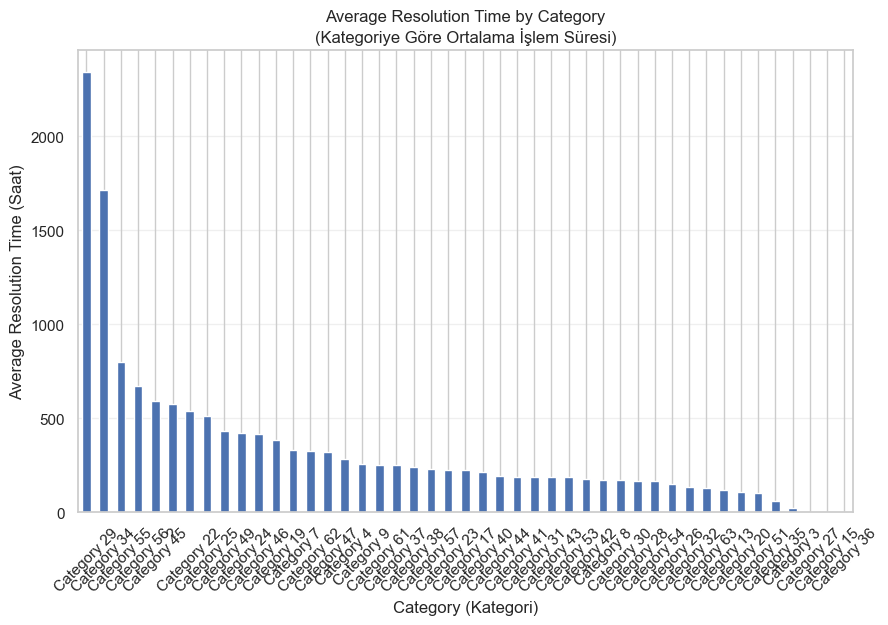

In [71]:
plt.figure(figsize=(10,6))

category_resolution.plot(kind="bar")

plt.title("Average Resolution Time by Category\n(Kategoriye Göre Ortalama İşlem Süresi)")
plt.xlabel("Category (Kategori)")
plt.ylabel("Average Resolution Time (Saat)")

plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)

plt.show()

Kategori bazında yapılan analizde incident çözüm sürelerinin kategorilere göre önemli farklılık gösterdiği görülmektedir. Özellikle Category 29 ve Category 34 en yüksek ortalama işlem sürelerine sahip kategoriler olarak öne çıkmaktadır. Buna karşılık bazı kategorilerde çözüm sürelerinin oldukça düşük olduğu görülmektedir. Ayrıca Category 36 için işlem süresi bulunmaması nedeniyle ortalama değer hesaplanamamıştır. Bu sonuçlar, belirli incident türlerinde süreçlerin daha karmaşık olduğunu ve iyileştirme çalışmalarının öncelikle bu kategorilere odaklanması gerektiğini göstermektedir.

### 7.1.9 Top 10 longest resolution times (En uzun işlem süresine sahip ilk 10 incident)

Bu bölümde çözümü en uzun süren ilk 10 incident kaydı listelenmektedir. Amaç, olağan dışı uzun süren kayıtları belirlemek ve ilerleyen aşamalarda darboğaz analizinde değerlendirmektir.

In [72]:
top10_resolution = (
    df[[
        "number",
        "category",
        "priority",
        "assignment_group",
        "assigned_to",
        "resolution_time"
    ]]
    .sort_values(by="resolution_time", ascending=False)
    .head(10)
)
    
top10_resolution

,number,category,priority,assignment_group,assigned_to,resolution_time
7812,INC0001839,Category 45,3 - Moderate,Group 31,Resolver 207,8070.166667
7816,INC0001839,Category 45,3 - Moderate,Group 31,Resolver 207,8070.166667
7815,INC0001839,Category 45,3 - Moderate,Group 31,Resolver 207,8070.166667
7814,INC0001839,Category 45,3 - Moderate,Group 31,Resolver 207,8070.166667
7813,INC0001839,Category 45,3 - Moderate,Group 31,Resolver 207,8070.166667
5615,INC0001349,Category 45,3 - Moderate,Group 67,Resolver 223,8020.266667
5625,INC0001349,Category 45,4 - Low,Group 67,Resolver 223,8020.266667
5624,INC0001349,Category 45,4 - Low,Group 67,Resolver 223,8020.266667
5623,INC0001349,Category 45,4 - Low,Group 67,Resolver 223,8020.266667
5622,INC0001349,Category 45,4 - Low,Group 67,Resolver 223,8020.266667


En uzun sürede çözülen incident kayıtları incelendiğinde ilk sıralarda yer alan kayıtların işlem sürelerinin 8000 saatin üzerinde olduğu görülmektedir. Ayrıca listede aynı incident numarasına ait birden fazla kayıt bulunması, veri setinin olay günlüğü (event log) yapısında olduğunu ve aynı incident için birden fazla işlem kaydının tutulduğunu göstermektedir. Bu nedenle darboğaz analizi yapılırken yalnızca olay kayıtları değil, incident bazında da değerlendirme yapılması faydalı olacaktır.

## 7.2 Waiting time analysis (Bekleme süresi analizi)

Bu bölümde incident kayıtlarının oluşturulması ile ilk işlem arasında geçen bekleme süresi analiz edilecektir. Bekleme süresi, operasyonel performansın değerlendirilmesinde önemli bir göstergedir. Bu nedenle öncelikle veri setinin bekleme süresi analizine uygun olup olmadığı kontrol edilmektedir.

## 7.2.1 Date Columns (Tarih sütunlarının incelenmesi)

Bekleme süresinin hesaplanabilmesi için veri setindeki tarih sütunları incelenmektedir.

In [73]:
# Veri setindeki tarih sütunlarını listeleme

datetime_columns = df.select_dtypes(include="datetime64[ns]").columns

print("Tarih sütunları:\n")

for col in datetime_columns:
    print(col)

Tarih sütunları:

opened_at
sys_created_at
sys_updated_at
resolved_at
closed_at


### 7.2.2 Waiting Time Requirements (Bekleme Süresi İçin Gerekli Sütunların Kontrolü)

Bekleme süresini hesaplayabilmek için gerekli olan tarih sütunlarının veri setinde bulunup bulunmadığı kontrol edilmektedir.

In [74]:
required_columns = [
    "opened_at",
    "assigned_at",
    "first_response_at",
    "resolved_at",
    "closed_at"
]

print("Bekleme süresi için gerekli sütunlar:\n")

for column in required_columns:

    if column in df.columns:
        print(f"+ {column} mevcut")

    else:
        print(f"- {column} bulunmuyor")

Bekleme süresi için gerekli sütunlar:

+ opened_at mevcut
- assigned_at bulunmuyor
- first_response_at bulunmuyor
+ resolved_at mevcut
+ closed_at mevcut


### 7.2.3 Waiting Time Feasibility (Bekleme Süresi Analizinin Uygunluğunun Değerlendirilmesi)

Bekleme süresinin hesaplanabilmesi için incident kaydının açıldığı zaman ile ilk atama veya ilk müdahale zamanını gösteren sütunların bulunması gerekmektedir. Bu kontrol sonucunda veri setinin bekleme süresi analizine uygun olup olmadığı değerlendirilecektir.

In [75]:
if ("assigned_at" in df.columns) or ("first_response_at" in df.columns):

    print("Veri seti bekleme süresi analizine uygundur.")

else:

    print("Veri setinde bekleme süresini hesaplayabilecek tarih sütunu bulunmamaktadır.")
    print("Bu nedenle Waiting Time (Bekleme Süresi) analizi gerçekleştirilememektedir.")

Veri setinde bekleme süresini hesaplayabilecek tarih sütunu bulunmamaktadır.
Bu nedenle Waiting Time (Bekleme Süresi) analizi gerçekleştirilememektedir.


**Veri setinde bulunan tarih sütunları incelendiğinde opened_at, resolved_at ve closed_at bilgilerinin mevcut olduğu görülmektedir. Ancak bekleme süresinin hesaplanabilmesi için gerekli olan assigned_at (Atama Zamanı) veya first_response_at (İlk Müdahale Zamanı) sütunları veri setinde bulunmamaktadır.
Bu nedenle incident kayıtlarının oluşturulması ile ilk işlem arasında geçen bekleme süresi güvenilir bir şekilde hesaplanamamaktadır. Gerçek olmayan veya varsayıma dayalı hesaplamalar yapılmaması amacıyla bu analiz gerçekleştirilmemiştir. Operasyonel performans değerlendirmesine veri setinin desteklediği diğer analizler ile devam edilecektir**

## 7.3 Busy Hours Analysis (Yoğun Saat Analizi)

Bu bölümde incident kayıtlarının günün hangi saatlerinde, haftanın hangi günlerinde ve hangi dönemlerde yoğunlaştığı analiz edilecektir. Ayrıca mesai saatleri ve vardiyalara göre incident dağılımları incelenerek operasyonel iş yükünün zaman içerisindeki değişimi değerlendirilecektir. Elde edilen bulgular, personel planlaması ve kaynak yönetimi açısından önemli bilgiler sağlayacaktır.

### 7.3.1 Hourly Incident Distribution (Saatlik Incident Dağılımı)

İlk olarak incident kayıtlarının günün hangi saatlerinde daha yoğun olduğu incelenmektedir. Bu analiz sayesinde operasyonel yükün en fazla olduğu saatler belirlenebilir.

In [76]:
hourly_incidents = (
    df["opened_hour"]
    .value_counts()
    .sort_index()
)

hourly_incidents

opened_hour
0      1146
1       998
2       665
3       565
4       509
5       510
6      1111
7      2755
8     11828
9     14805
10    13987
11    12706
12     6497
13     8265
14    11167
15    10625
16     9289
17     5266
18     2094
19     1158
20      969
21     1363
22      911
23      809
Name: count, dtype: int64

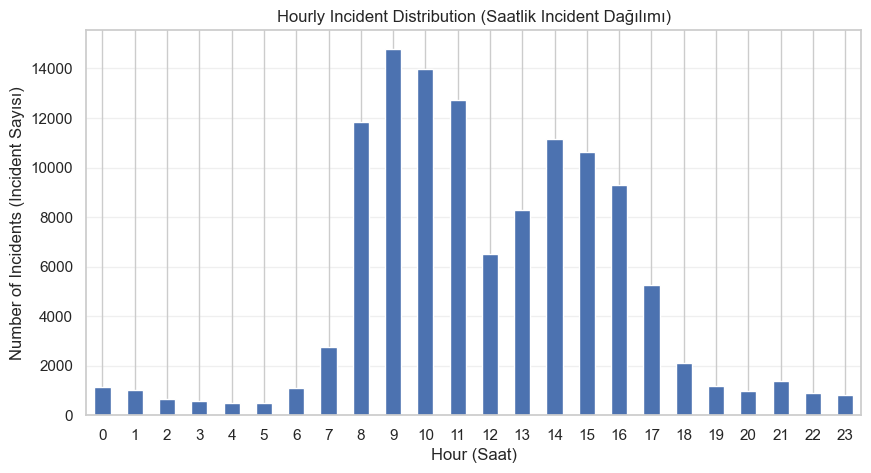

In [77]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

hourly_incidents.plot(
    kind="bar"
)

plt.title("Hourly Incident Distribution (Saatlik Incident Dağılımı)")
plt.xlabel("Hour (Saat)")
plt.ylabel("Number of Incidents (Incident Sayısı)")
plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.show()

Saatlik incident dağılımı incelendiğinde kayıtların özellikle 08:00 ile 16:00 saatleri arasında yoğunlaştığı görülmektedir. En fazla incident 09:00 saatinde (14.805 kayıt) açılmıştır. Bunu sırasıyla 10:00, 11:00 ve 08:00 saatleri takip etmektedir. Gece saatlerinde ise incident sayısının belirgin şekilde azaldığı gözlemlenmektedir. Bu durum operasyonel iş yükünün büyük ölçüde mesai saatleri içerisinde gerçekleştiğini göstermektedir.

### 7.3.2 Daily Incident Distribution (Haftanın Günlerine Göre Incident Dağılımı)

Bu analizde incident kayıtlarının haftanın günlerine göre dağılımı incelenmektedir. Böylece hangi günlerde daha fazla incident oluştuğu belirlenebilir.

In [78]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_incidents = (
    df["opened_weekday"]
    .value_counts()
    .reindex(weekday_order)
)

weekday_incidents

opened_weekday
Monday       27340
Tuesday      23271
Wednesday    24345
Thursday     21348
Friday       18795
Saturday      2589
Sunday        2310
Name: count, dtype: int64

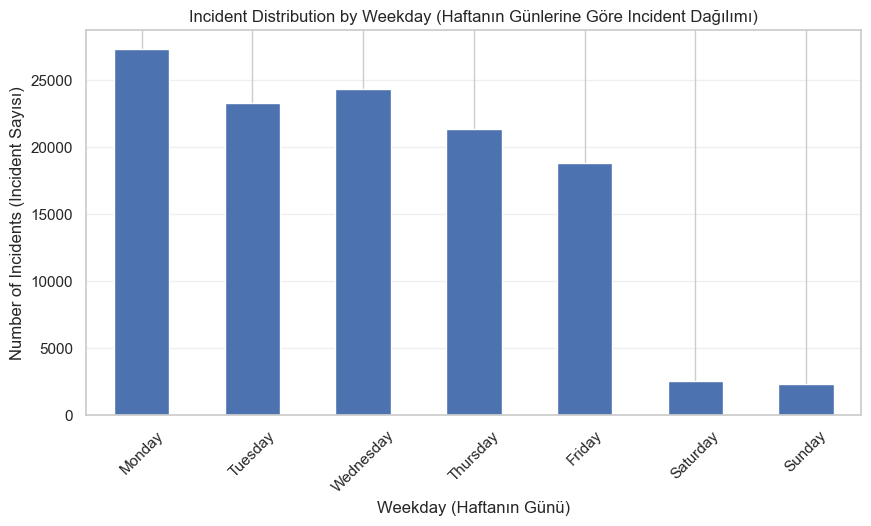

In [79]:
plt.figure(figsize=(10,5))

weekday_incidents.plot(
    kind="bar"
)

plt.title("Incident Distribution by Weekday (Haftanın Günlerine Göre Incident Dağılımı)")
plt.xlabel("Weekday (Haftanın Günü)")
plt.ylabel("Number of Incidents (Incident Sayısı)")
plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)

plt.show()

Haftalık dağılım incelendiğinde en fazla incident kaydının Pazartesi günü (27.340) oluşturulduğu görülmektedir. Pazartesiyi sırasıyla Çarşamba ve Salı günleri takip etmektedir. Hafta sonlarında ise incident sayısı önemli ölçüde azalmaktadır. Özellikle Cumartesi ve Pazar günlerindeki düşük kayıt sayıları, operasyonel faaliyetlerin büyük ölçüde hafta içi yürütüldüğünü göstermektedir.

### 7.3.3 Monthly Incident Distribution (Aylara Göre Incident Dağılımı)

Bu bölümde incident kayıtlarının aylara göre dağılımı incelenmektedir. Böylece belirli aylarda operasyonel yoğunluk artışı veya azalışı olup olmadığı değerlendirilebilir.

In [80]:
monthly_incidents = (
    df["opened_month"]
    .value_counts()
    .sort_index()
)

monthly_incidents

opened_month
April       41691
February     1342
March       58012
May         18953
Name: count, dtype: int64

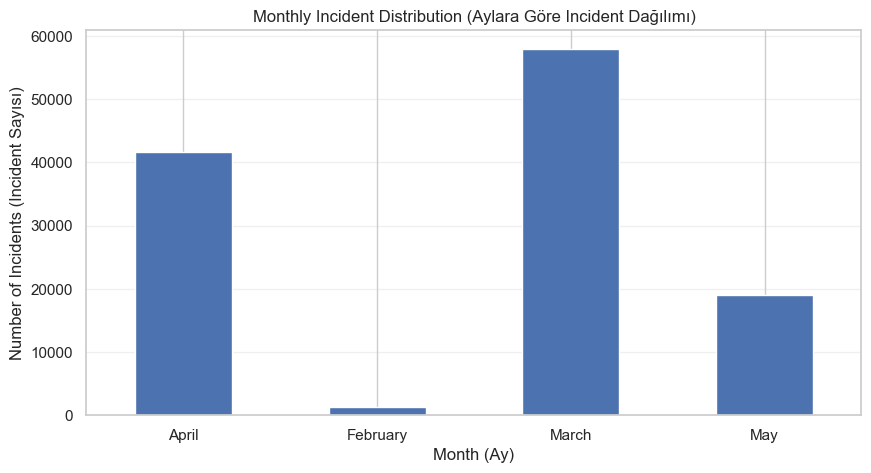

In [81]:
plt.figure(figsize=(10,5))

monthly_incidents.plot(
    kind="bar"
)

plt.title("Monthly Incident Distribution (Aylara Göre Incident Dağılımı)")
plt.xlabel("Month (Ay)")
plt.ylabel("Number of Incidents (Incident Sayısı)")
plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.show()

Aylık dağılım incelendiğinde incident kayıtlarının büyük bölümünün Mart (58.012) ve Nisan (41.691) aylarında yoğunlaştığı görülmektedir. Buna karşılık Şubat ayında oldukça az sayıda incident kaydı bulunmaktadır. Bu durum veri setinin belirli aylara ait kayıtları içerdiğini ve zaman aralığının tüm yılı kapsamadığını göstermektedir. Bu nedenle aylık analiz sonuçları değerlendirilirken veri setinin kapsadığı dönem dikkate alınmalıdır.

### 7.3.4 Work Shift Analysis (Vardiya Analizi)

Bu bölümde incident kayıtlarının Work Shift (Çalışma Vardiyası) değişkenine göre dağılımı incelenmektedir. Böylece hangi vardiyada daha fazla incident oluştuğu belirlenebilir. Elde edilen sonuçlar, vardiya planlaması ve personel dağılımının değerlendirilmesinde kullanılabilir.

In [82]:
shift_incidents = (
    df["work_shift"]
    .value_counts()
)

shift_incidents

work_shift
Day        89880
Evening    21859
Night       8259
Name: count, dtype: int64

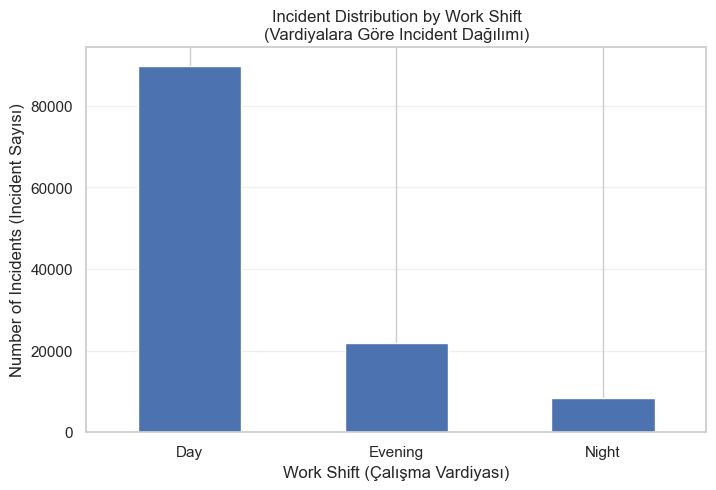

In [83]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

shift_incidents.plot(
    kind="bar"
)

plt.title("Incident Distribution by Work Shift\n(Vardiyalara Göre Incident Dağılımı)")
plt.xlabel("Work Shift (Çalışma Vardiyası)")
plt.ylabel("Number of Incidents (Incident Sayısı)")
plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.show()

Vardiya bazında yapılan analiz sonucunda incident kayıtlarının büyük çoğunluğunun Day (Gündüz) vardiyasında (89.880 kayıt) açıldığı görülmektedir. Evening (Akşam) vardiyası ikinci sırada yer alırken Night (Gece) vardiyasında incident sayısı oldukça düşüktür. Bu sonuç, operasyonel faaliyetlerin ve kullanıcı etkileşiminin ağırlıklı olarak gündüz saatlerinde gerçekleştiğini göstermektedir.

### 7.3.5 Business Hours Analysis (Mesai Saatleri Analizi)

Bu analizde incident kayıtlarının Business Hours (Mesai Saatleri) içerisinde mi yoksa mesai saatleri dışında mı açıldığı incelenmektedir. Böylece operasyonel yükün çalışma saatleri içerisindeki ve dışındaki dağılımı değerlendirilebilir.

In [84]:
business_hours = (
    df["is_business_hours"]
    .value_counts()
)

business_hours

is_business_hours
True     94701
False    25297
Name: count, dtype: int64

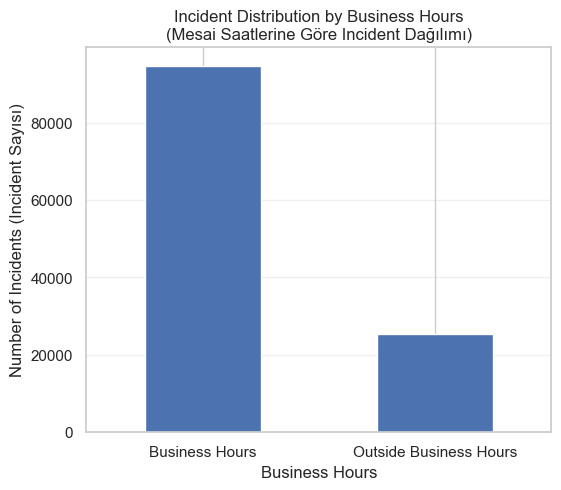

In [85]:
plt.figure(figsize=(6,5))

business_hours.plot(
    kind="bar"
)

plt.title("Incident Distribution by Business Hours\n(Mesai Saatlerine Göre Incident Dağılımı)")
plt.xlabel("Business Hours")
plt.ylabel("Number of Incidents (Incident Sayısı)")
plt.xticks(
    ticks=[0, 1],
    labels=["Business Hours", "Outside Business Hours"],
    rotation=0
)

plt.grid(axis="y", alpha=0.3)

plt.show()

Mesai saatlerine göre yapılan analizde incident kayıtlarının 94.701'inin mesai saatleri içerisinde, 25.297'sinin ise mesai saatleri dışında açıldığı belirlenmiştir. Bu durum incident kayıtlarının büyük bölümünün normal çalışma saatlerinde oluşturulduğunu göstermektedir. Mesai saatleri dışındaki incident sayısının daha düşük olması, operasyonel yoğunluğun çalışma saatleri ile paralel ilerlediğini göstermektedir.

### 7.3.6 Incident Density Heatmap (Saat ve Güne Göre Yoğunluk Analizi)

Bu analizde incident kayıtlarının günün saatleri ile haftanın günlerine göre birlikte dağılımı incelenmektedir. Böylece hangi günlerde ve hangi saatlerde operasyonel yoğunluğun arttığı daha ayrıntılı olarak görülebilir.

In [86]:
hour_day = pd.crosstab(
    df["opened_weekday"],
    df["opened_hour"]
)

hour_day = hour_day.reindex([
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
])

hour_day

opened_hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
opened_weekday,,,,,,,,,,,,,,,,,,,,,,,,
Monday,159,150,48,64,82,67,155,455,2746,3819,3341,3047,1724,2169,2650,2415,1827,1155,423,154,146,268,145,131
Tuesday,142,208,104,127,55,62,242,534,2527,2962,2753,2346,1276,1654,2211,1864,1838,975,371,270,226,210,210,104
Wednesday,196,147,158,72,112,75,174,630,2428,2884,2734,2619,1270,1570,2374,2414,1992,1097,423,190,161,338,177,110
Thursday,185,160,118,69,75,108,116,472,1883,2621,2608,2173,1138,1500,1928,2025,1869,989,407,249,210,239,91,115
Friday,212,104,128,97,106,67,199,466,1804,2241,2184,2205,948,1144,1789,1682,1528,859,273,148,152,184,118,157
Saturday,142,166,81,77,63,88,123,130,196,141,160,172,77,125,92,136,117,83,93,83,25,76,66,77
Sunday,110,63,28,59,16,43,102,68,244,137,207,144,64,103,123,89,118,108,104,64,49,48,104,115


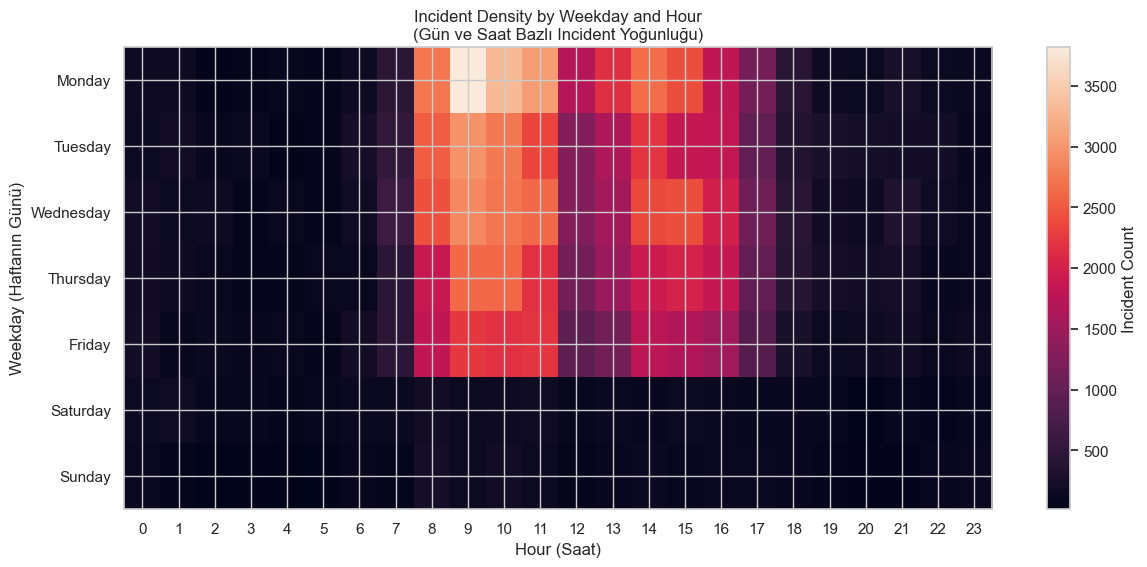

In [87]:
plt.figure(figsize=(14,6))

plt.imshow(hour_day, aspect="auto")

plt.colorbar(label="Incident Count")

plt.title("Incident Density by Weekday and Hour\n(Gün ve Saat Bazlı Incident Yoğunluğu)")
plt.xlabel("Hour (Saat)")
plt.ylabel("Weekday (Haftanın Günü)")

plt.xticks(range(24))
plt.yticks(range(len(hour_day.index)), hour_day.index)

plt.show()

Gün ve saat bazlı yoğunluk analizi, incident kayıtlarının özellikle hafta içi sabah ve öğle saatlerinde yoğunlaştığını göstermektedir. En yüksek yoğunluk Pazartesi günü 09:00-11:00 saatleri arasında görülmektedir. Hafta sonlarında ise günün tüm saatlerinde incident yoğunluğu oldukça düşüktür. Bu analiz, operasyonel ekiplerin en yoğun zaman dilimlerini belirlemek ve personel planlamasını optimize etmek açısından önemli bilgiler sunmaktadır.

### 7.3.7 Top 10 Busiest Hours (En Yoğun 10 Saat)

Bu bölümde incident kayıtlarının en yoğun olduğu ilk 10 saat belirlenmektedir. Böylece operasyonel iş yükünün en fazla olduğu zaman dilimleri tespit edilebilir.

In [88]:
top10_hours = (
    df["opened_hour"]
    .value_counts()
    .sort_values(ascending=False)
    .head(10)
)

top10_hours

opened_hour
9     14805
10    13987
11    12706
8     11828
14    11167
15    10625
16     9289
13     8265
12     6497
17     5266
Name: count, dtype: int64

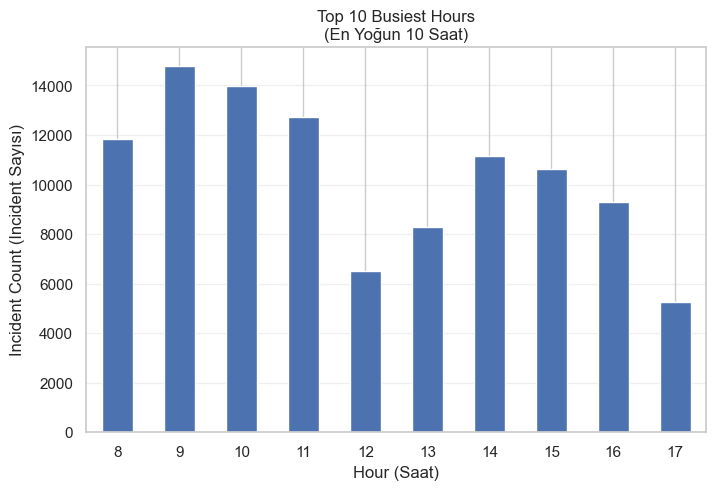

In [89]:
plt.figure(figsize=(8,5))

top10_hours.sort_index().plot(
    kind="bar"
)

plt.title("Top 10 Busiest Hours\n(En Yoğun 10 Saat)")
plt.xlabel("Hour (Saat)")
plt.ylabel("Incident Count (Incident Sayısı)")
plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.show()

En yoğun saatler incelendiğinde incident kayıtlarının büyük bölümünün 08:00 ile 17:00 saatleri arasında oluştuğu görülmektedir. En yoğun saat 09:00 olup toplam 14.805 incident kaydı bulunmaktadır. Bu sonuç, çalışma gününün başlangıcında operasyonel yükün arttığını ve destek ekiplerinin özellikle sabah saatlerinde daha yoğun çalıştığını göstermektedir.

## 7.4 SLA Violations Analysis (SLA ihlalleri Analizi)

Bu bölümde incident kayıtlarının SLA (Service Level Agreement - Hizmet Seviyesi Anlaşması) açısından performansı incelenecektir. Veri setindeki made_sla değişkeni kullanılarak incident kayıtlarının SLA'yı karşılayıp karşılamadığı analiz edilecektir. Ayrıca öncelik, etki düzeyi, aciliyet, ekip ve kategori bazında SLA performansı değerlendirilerek operasyonel süreçlerde iyileştirilmesi gereken alanlar belirlenecektir.

### 7.4.1 SLA Status Distribution (SLA Durum Dağılımı)

İlk olarak incident kayıtlarının kaç tanesinin SLA'yı karşıladığı (Made SLA) ve kaç tanesinin SLA ihlali oluşturduğu incelenecektir. Bu analiz, operasyonel performansın genel görünümünü ortaya koymaktadır.

In [90]:
sla_distribution = (
    df["made_sla"]
    .value_counts()
)

sla_distribution

made_sla
True     111738
False      8260
Name: count, dtype: int64

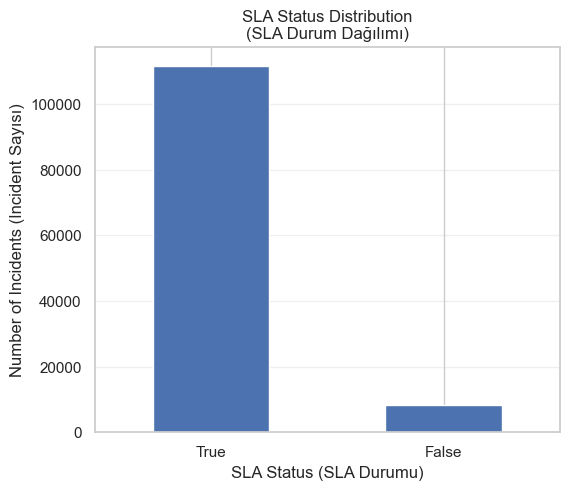

In [91]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

sla_distribution.plot(
    kind="bar"
)

plt.title("SLA Status Distribution\n(SLA Durum Dağılımı)")
plt.xlabel("SLA Status (SLA Durumu)")
plt.ylabel("Number of Incidents (Incident Sayısı)")
plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.show()

SLA durum dağılımı incelendiğinde incident kayıtlarının büyük çoğunluğunun hizmet seviyesi anlaşmasını başarıyla karşıladığı görülmektedir. Toplam 111.738 incident kaydı SLA hedeflerine uygun şekilde tamamlanırken, 8.260 incident kaydı SLA ihlali oluşturmuştur. Bu sonuç, operasyonel süreçlerin genel olarak belirlenen hizmet seviyelerine uygun yürütüldüğünü ve SLA başarısının yüksek olduğunu göstermektedir.

### 7.4.2 SLA Percentage Analysis (SLA Yüzde Analizi)

Bu bölümde SLA başarı ve ihlal oranları yüzde olarak hesaplanmaktadır. Böylece incident kayıtlarının ne kadarının belirlenen hizmet seviyesine uygun şekilde tamamlandığı daha kolay değerlendirilebilmektedir.

In [92]:
sla_percentage = (
    df["made_sla"]
    .value_counts(normalize=True)
    * 100
).round(2)

sla_percentage

made_sla
True     93.12
False     6.88
Name: proportion, dtype: float64

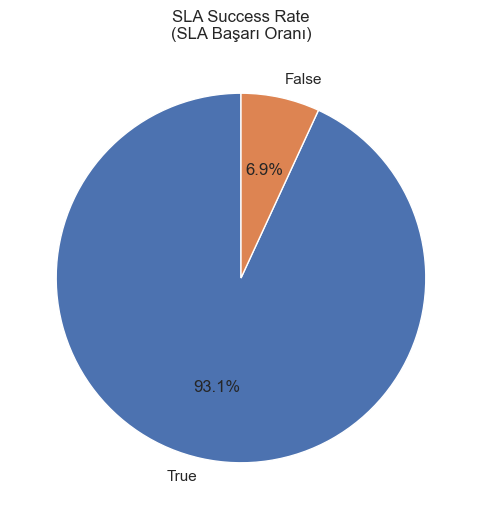

In [93]:
plt.figure(figsize=(6,6))

plt.pie(
    sla_distribution,
    labels=sla_distribution.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("SLA Success Rate\n(SLA Başarı Oranı)")

plt.show()

Yüzdesel analiz sonucunda incident kayıtlarının %93,12'sinin SLA hedeflerini karşıladığı, %6,88'inin ise SLA ihlali oluşturduğu belirlenmiştir. SLA başarı oranının oldukça yüksek olması, operasyonel süreçlerin büyük ölçüde etkin şekilde yönetildiğini göstermektedir. Bununla birlikte, SLA ihlali oluşturan kayıtların nedenlerinin incelenmesi ve gerekli iyileştirmelerin yapılması hizmet kalitesinin daha da artırılmasına katkı sağlayacaktır.

### 7.4.3 Resolution Time by SLA Status (SLA Durumuna Göre İşlem Süresi)

Bu analizde incident kayıtlarının işlem süreleri, SLA'yı karşılayan ve SLA ihlali oluşturan kayıtlar için ayrı ayrı incelenmektedir. Böylece işlem süresi ile SLA performansı arasındaki ilişki değerlendirilmektedir.

In [94]:
df.groupby("made_sla")["resolution_time"].describe()

,count,mean,std,min,25%,50%,75%,max
made_sla,,,,,,,,
False,8075.0,441.681385,811.842383,0.0,99.900000,198.05,386.941667,8070.166667
True,109062.0,268.274087,652.560556,0.0,4.616667,73.25,262.216667,8070.166667


<Figure size 700x500 with 0 Axes>

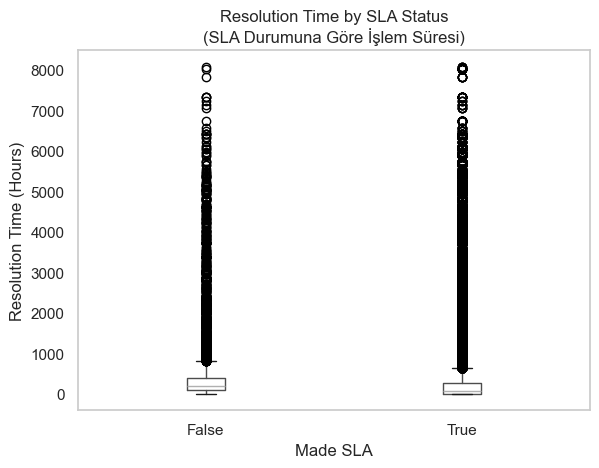

In [95]:
plt.figure(figsize=(7,5))

df.boxplot(
    column="resolution_time",
    by="made_sla",
    grid=False
)

plt.title("Resolution Time by SLA Status\n(SLA Durumuna Göre İşlem Süresi)")
plt.suptitle("")
plt.xlabel("Made SLA")
plt.ylabel("Resolution Time (Hours)")

plt.show()

SLA durumuna göre işlem süreleri incelendiğinde, SLA'yı karşılayan incident kayıtlarının ortalama çözüm süresinin yaklaşık 268 saat, SLA ihlali oluşturan incident kayıtlarının ise yaklaşık 442 saat olduğu görülmektedir. Bu sonuç, işlem süresi uzadıkça SLA ihlali yaşanma olasılığının arttığını göstermektedir. Boxplot grafiğinde her iki grupta da aykırı değerler bulunmasına rağmen, SLA ihlali oluşturan kayıtların genel olarak daha uzun çözüm sürelerine sahip olduğu açıkça görülmektedir.

### 7.4.4 SLA by Priority (Öncelik Düzeyine Göre SLA Analizi)

Bu bölümde incident kayıtlarının Priority (Öncelik) seviyelerine göre SLA performansı incelenmektedir. Böylece hangi öncelik seviyelerinde SLA ihlallerinin daha fazla olduğu belirlenebilir.

In [96]:
sla_priority = pd.crosstab(
    df["priority"],
    df["made_sla"]
)

sla_priority

made_sla,False,True
priority,,
1 - Critical,215,1620
2 - High,336,2163
3 - Moderate,7588,104527
4 - Low,121,3428


In [97]:
sla_priority_percent = pd.crosstab(
    df["priority"],
    df["made_sla"],
    normalize="index"
) * 100

sla_priority_percent.round(2)

made_sla,False,True
priority,,
1 - Critical,11.72,88.28
2 - High,13.45,86.55
3 - Moderate,6.77,93.23
4 - Low,3.41,96.59


<Figure size 800x500 with 0 Axes>

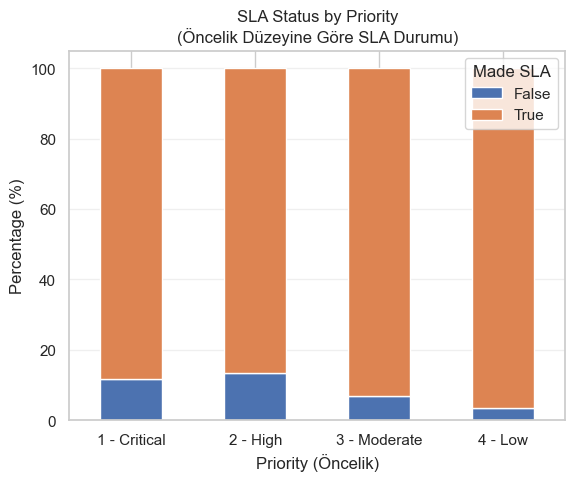

In [98]:
plt.figure(figsize=(8,5))

sla_priority_percent.plot(
    kind="bar",
    stacked=True
)

plt.title("SLA Status by Priority\n(Öncelik Düzeyine Göre SLA Durumu)")
plt.xlabel("Priority (Öncelik)")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.legend(title="Made SLA")

plt.grid(axis="y", alpha=0.3)

plt.show()

Öncelik düzeyine göre yapılan analizde Low (Düşük) öncelikli incident kayıtlarının %96,59 ile en yüksek SLA başarı oranına sahip olduğu görülmektedir. Buna karşılık High (Yüksek) öncelikli incident kayıtlarında SLA başarı oranı %86,55, Critical (Kritik) öncelikli kayıtlarda ise %88,28 olarak hesaplanmıştır. Kritik ve yüksek öncelikli incident kayıtlarında SLA ihlal oranlarının daha yüksek olması, bu tür kayıtların çözüm süreçlerinin daha karmaşık ve zaman alıcı olabileceğini göstermektedir.

### 7.4.5 SLA by Impact (Etki Düzeyine Göre SLA Analizi)

Bu analizde incident kayıtlarının Impact (Etki Düzeyi) seviyelerine göre SLA performansı incelenmektedir. Böylece yüksek etkiye sahip incident kayıtlarında SLA başarısının nasıl değiştiği değerlendirilmektedir.

In [99]:
sla_impact = pd.crosstab(
    df["impact"],
    df["made_sla"]
)

sla_impact

made_sla,False,True
impact,,
1 - High,337,2552
2 - Medium,7817,105874
3 - Low,106,3312


In [100]:
sla_impact_percent = pd.crosstab(
    df["impact"],
    df["made_sla"],
    normalize="index"
) * 100

sla_impact_percent.round(2)

made_sla,False,True
impact,,
1 - High,11.66,88.34
2 - Medium,6.88,93.12
3 - Low,3.10,96.90


<Figure size 800x500 with 0 Axes>

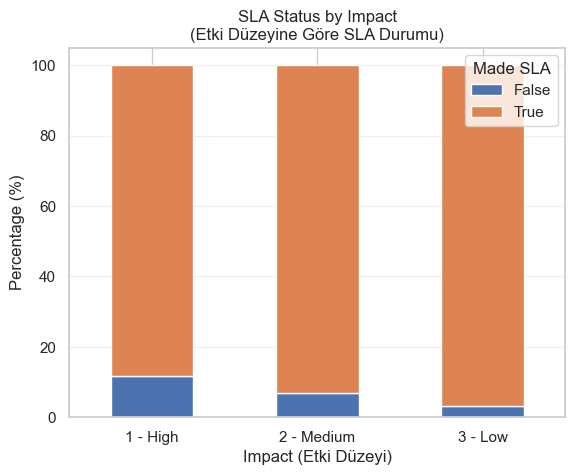

In [101]:
plt.figure(figsize=(8,5))

sla_impact_percent.plot(
    kind="bar",
    stacked=True
)

plt.title("SLA Status by Impact\n(Etki Düzeyine Göre SLA Durumu)")
plt.xlabel("Impact (Etki Düzeyi)")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.legend(title="Made SLA")

plt.grid(axis="y", alpha=0.3)

plt.show()

Etki düzeyine göre yapılan analiz sonucunda Low (Düşük) etkiye sahip incident kayıtlarının %96,90 ile en yüksek SLA başarı oranına sahip olduğu belirlenmiştir. Medium (Orta) etki düzeyindeki kayıtların SLA başarı oranı %93,12, High (Yüksek) etki düzeyindeki kayıtların ise %88,34 olarak hesaplanmıştır. Etki düzeyi arttıkça SLA ihlal oranının da arttığı görülmektedir. Bu durum, yüksek etkiye sahip incident kayıtlarının çözüm süreçlerinin daha fazla kaynak ve koordinasyon gerektirdiğini göstermektedir.

### 7.4.6 SLA by Urgency (Aciliyet Düzeyine Göre SLA Analizi)

Bu bölümde incident kayıtlarının Urgency (Aciliyet) seviyelerine göre SLA performansı incelenmektedir. Böylece aciliyet seviyesi arttıkça SLA başarısında bir değişiklik olup olmadığı değerlendirilmektedir.

In [102]:
sla_urgency = pd.crosstab(
    df["urgency"],
    df["made_sla"]
)

sla_urgency

made_sla,False,True
urgency,,
1 - High,430,2873
2 - Medium,7722,105828
3 - Low,108,3037


In [103]:
sla_urgency_percent = pd.crosstab(
    df["urgency"],
    df["made_sla"],
    normalize="index"
) * 100

sla_urgency_percent.round(2)

made_sla,False,True
urgency,,
1 - High,13.02,86.98
2 - Medium,6.80,93.20
3 - Low,3.43,96.57


<Figure size 800x500 with 0 Axes>

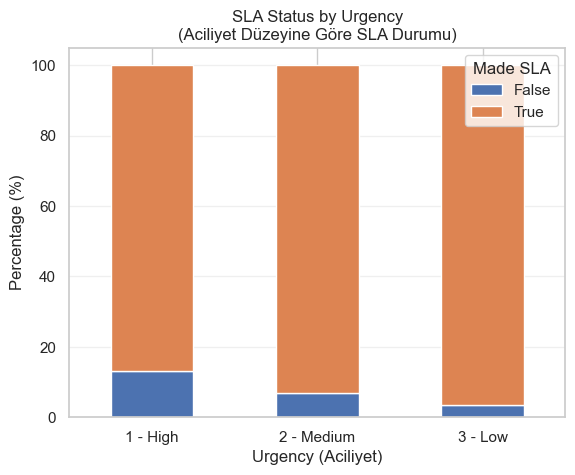

In [104]:
plt.figure(figsize=(8,5))

sla_urgency_percent.plot(
    kind="bar",
    stacked=True
)

plt.title("SLA Status by Urgency\n(Aciliyet Düzeyine Göre SLA Durumu)")
plt.xlabel("Urgency (Aciliyet)")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.legend(title="Made SLA")

plt.grid(axis="y", alpha=0.3)

plt.show()

Aciliyet düzeyine göre yapılan analizde Low (Düşük) aciliyet seviyesindeki incident kayıtlarının %96,57 ile en yüksek SLA başarı oranına sahip olduğu görülmektedir. Medium (Orta) aciliyet seviyesinde bu oran %93,20, High (Yüksek) aciliyet seviyesinde ise %86,98 olarak hesaplanmıştır. Aciliyet seviyesi yükseldikçe SLA ihlal oranının arttığı gözlemlenmektedir. Bunun temel nedeni, yüksek aciliyet gerektiren incident kayıtlarının daha karmaşık yapıda olması ve çözüm süreçlerinin daha dikkatli yönetilmesini gerektirmesidir.

### 7.4.7 SLA by Assignment Group (Atama Grubuna Göre SLA Analizi)

Bu bölümde incident kayıtlarının Assignment Group (Atama Grubu) bazında SLA performansı incelenmektedir. Böylece hangi ekiplerin SLA hedeflerini daha yüksek oranda karşıladığı, hangi ekiplerde ise SLA ihlallerinin daha fazla olduğu belirlenebilir. Bu analiz, ekip performansının değerlendirilmesi ve süreç iyileştirme çalışmalarına katkı sağlamaktadır.

In [105]:
sla_assignment = pd.crosstab(
    df["assignment_group"],
    df["made_sla"]
)

sla_assignment

made_sla,False,True
assignment_group,,
?,1115,13098
Group 10,251,1379
Group 11,0,1
Group 12,92,365
Group 13,16,90
Group 14,12,56
Group 15,42,224
Group 17,7,56
Group 19,8,225


In [106]:
sla_assignment_percent = (
    pd.crosstab(
        df["assignment_group"],
        df["made_sla"],
        normalize="index"
    ) * 100
).round(2)

sla_assignment_percent

made_sla,False,True
assignment_group,,
?,7.84,92.16
Group 10,15.40,84.60
Group 11,0.00,100.00
Group 12,20.13,79.87
Group 13,15.09,84.91
Group 14,17.65,82.35
Group 15,15.79,84.21
Group 17,11.11,88.89
Group 19,3.43,96.57


<Figure size 1200x600 with 0 Axes>

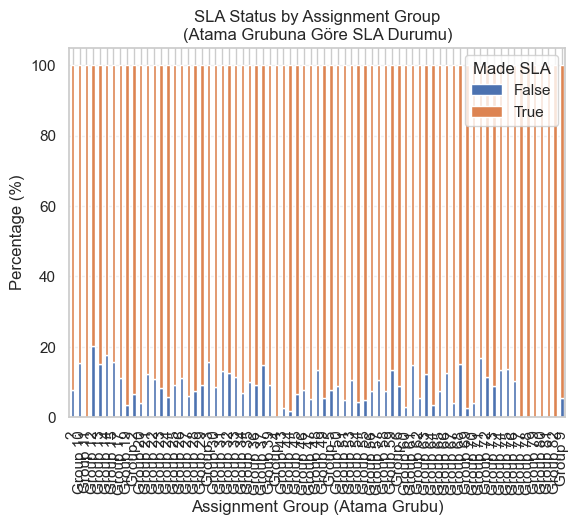

In [107]:
plt.figure(figsize=(12,6))

sla_assignment_percent.plot(
    kind="bar",
    stacked=True
)

plt.title("SLA Status by Assignment Group\n(Atama Grubuna Göre SLA Durumu)")
plt.xlabel("Assignment Group (Atama Grubu)")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=90)

plt.legend(title="Made SLA")

plt.grid(axis="y", alpha=0.3)

plt.show()

Atama gruplarına göre yapılan analiz sonucunda ekiplerin büyük çoğunlüğünün %90'ın üzerinde SLA başarı oranına sahip olduğu görülmektedir. Özellikle Group 70 (%96,07), Group 69 (%97,52), Group 64 (%96,50), Group 60 (%96,97) ve Group 20 (%96,04) gibi ekipler yüksek SLA performansı göstermektedir. Buna karşılık Group 12 (%79,87), Group 14 (%82,35), Group 10 (%84,60), Group 37 (%85,17) ve Group 68 (%84,83) gibi ekiplerde SLA ihlal oranlarının diğer ekiplere göre daha yüksek olduğu belirlenmiştir. Bununla birlikte yalnızca birkaç incident kaydına sahip ekiplerde görülen %100 SLA başarı oranları (örneğin Group 11, Group 77 ve benzeri gruplar) örneklem sayısının düşük olması nedeniyle tek başına performans göstergesi olarak değerlendirilmemelidir. Genel olarak ekip bazındaki farklılıklar, bazı ekiplerde süreç iyileştirmesi ve iş yükü planlamasının gerekli olabileceğini göstermektedir.

### 7.4.8 SLA by Category (Kategoriye Göre SLA Analizi)

Bu analizde incident kayıtlarının Category (Kategori) bazında SLA performansı incelenmektedir. Böylece hangi incident kategorilerinde SLA ihlallerinin daha sık meydana geldiği belirlenebilir. Elde edilen sonuçlar, problemli süreçlerin belirlenmesi ve iyileştirilmesi açısından önemli bilgiler sunmaktadır.

In [108]:
sla_category = pd.crosstab(
    df["category"],
    df["made_sla"]
)

sla_category

made_sla,False,True
category,,
?,3,61
Category 13,48,893
Category 15,0,3
Category 17,31,424
Category 19,111,1203
Category 20,228,4545
Category 22,41,358
Category 23,437,6022
Category 24,268,3685


In [109]:
sla_category_percent = (
    pd.crosstab(
        df["category"],
        df["made_sla"],
        normalize="index"
    ) * 100
).round(2)

sla_category_percent

made_sla,False,True
category,,
?,4.69,95.31
Category 13,5.10,94.90
Category 15,0.00,100.00
Category 17,6.81,93.19
Category 19,8.45,91.55
Category 20,4.78,95.22
Category 22,10.28,89.72
Category 23,6.77,93.23
Category 24,6.78,93.22


<Figure size 1000x600 with 0 Axes>

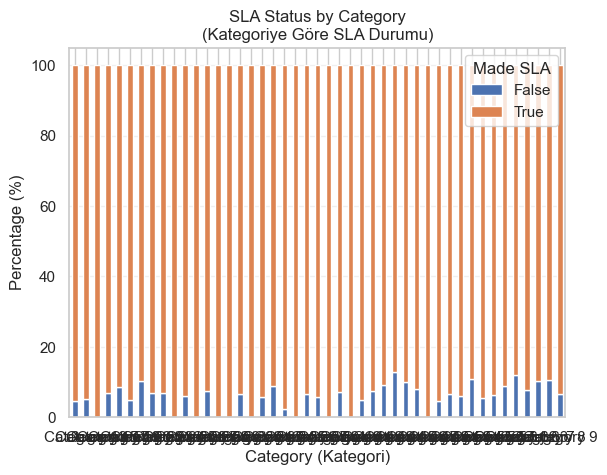

In [110]:
plt.figure(figsize=(10,6))

sla_category_percent.plot(
    kind="bar",
    stacked=True
)

plt.title("SLA Status by Category\n(Kategoriye Göre SLA Durumu)")
plt.xlabel("Category (Kategori)")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.legend(title="Made SLA")

plt.grid(axis="y", alpha=0.3)

plt.show()

Kategori bazında yapılan analiz sonucunda incident kayıtlarının büyük bölümünde SLA başarı oranının %90'ın üzerinde olduğu görülmektedir. Bununla birlikte bazı kategorilerde SLA ihlal oranlarının diğerlerine göre daha yüksek olduğu dikkat çekmektedir. Özellikle Category 45 (%87,10), Category 62 (%88,00), Category 55 (%89,14), Category 46 (%89,99), Category 22 (%89,72) ve Category 8 (%89,38) kategorileri görece daha düşük SLA başarı oranına sahiptir. Buna karşılık bazı kategorilerde %100 SLA başarısı görülmektedir. Ancak bu kategorilerin çoğunda incident sayısının oldukça az olması nedeniyle bu sonuçlar genellenebilir performans göstergesi olarak değerlendirilmemelidir. Sonuç olarak kategori bazındaki farklılıklar, bazı incident türlerinde çözüm süreçlerinin daha karmaşık olduğunu ve bu alanlarda süreç iyileştirmelerinin faydalı olabileceğini göstermektedir.

### 7.4.9 SLA by Resolution Time (İşlem Süresi ve SLA İlişkisi)

Bu bölümde incident kayıtlarının Resolution Time (İşlem Süresi) ile SLA durumu arasındaki ilişki incelenmektedir. Amaç, işlem süresi uzadıkça SLA ihlali olasılığının artıp artmadığını değerlendirmektir.

In [111]:
resolution_sla = (
    df.groupby("made_sla")["resolution_time"]
    .mean()
    .round(2)
)

resolution_sla

made_sla
False    441.68
True     268.27
Name: resolution_time, dtype: float64

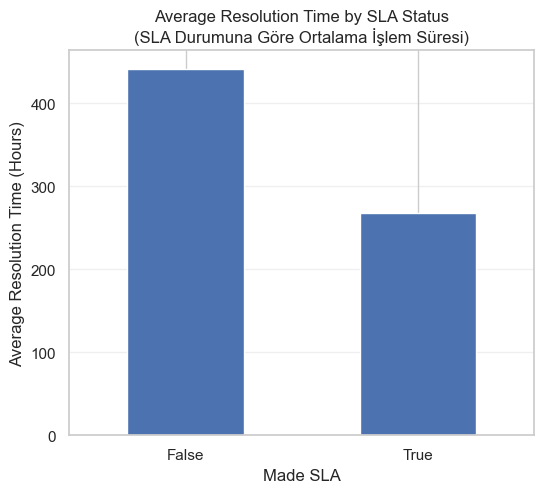

In [112]:
plt.figure(figsize=(6,5))

resolution_sla.plot(
    kind="bar"
)

plt.title("Average Resolution Time by SLA Status\n(SLA Durumuna Göre Ortalama İşlem Süresi)")
plt.xlabel("Made SLA")
plt.ylabel("Average Resolution Time (Hours)")
plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.show()

SLA durumu ile ortalama işlem süresi arasındaki ilişki incelendiğinde, SLA'yı karşılayan incident kayıtlarının ortalama çözüm süresinin 268,27 saat, SLA ihlali oluşturan kayıtların ise 441,68 saat olduğu belirlenmiştir. SLA ihlali bulunan incident kayıtlarının ortalama çözüm süresinin yaklaşık 173 saat daha uzun olması, işlem süresi ile SLA performansı arasında güçlü bir ilişki bulunduğunu göstermektedir. Çözüm süresi uzadıkça SLA hedeflerinin karşılanma olasılığı azalmakta ve ihlal riski artmaktadır. Bu nedenle uzun süre açık kalan incident kayıtlarının erken tespit edilmesi ve öncelikli olarak ele alınması, SLA performansının artırılmasına katkı sağlayacaktır.

## 7.5 Employee and Team Performance Analysis (Çalışan ve Ekip Performans Analizi)

Bu bölümde incident kayıtları Employee (Çalışan) ve Assignment Group (Atama Grubu/Ekip) bazında incelenecektir. Amaç, operasyonel iş yükünü, ekiplerin performansını ve incident dağılımını değerlendirmektir. Analizler sayesinde yoğun çalışan ekipler ve iyileştirme yapılabilecek alanlar belirlenebilecektir.

### 7.5.1 Incident Count by Assignment Group (Atama Grubuna Göre Incident Sayısı)

Bu analizde her Assignment Group (Atama Grubu) tarafından yönetilen incident sayıları incelenmektedir. Böylece en yoğun çalışan ekipler belirlenebilmektedir.

In [113]:
incident_group = (
    df["assignment_group"]
    .value_counts()
)

incident_group

assignment_group
Group 70    35023
?           14213
Group 25     6765
Group 24     5823
Group 20     5146
Group 39     3951
Group 23     3881
Group 27     3243
Group 28     3190
Group 73     2841
Group 64     2170
Group 55     2095
Group 65     2042
Group 66     1826
Group 72     1820
Group 54     1783
Group 57     1632
Group 10     1630
Group 29     1512
Group 6      1491
Group 9      1344
Group 30     1070
Group 76     1002
Group 33     1000
Group 31      938
Group 22      890
Group 5       876
Group 69      847
Group 56      786
Group 37      708
Group 58      637
Group 46      635
Group 48      562
Group 74      513
Group 49      487
Group 3       464
Group 12      457
Group 51      390
Group 50      387
Group 75      382
Group 53      331
Group 62      298
Group 15      266
Group 47      249
Group 19      233
Group 34      208
Group 21      203
Group 26      171
Group 59      158
Group 68      145
Group 61      134
Group 60      132
Group 35      129
Group 67      122
Group 13   

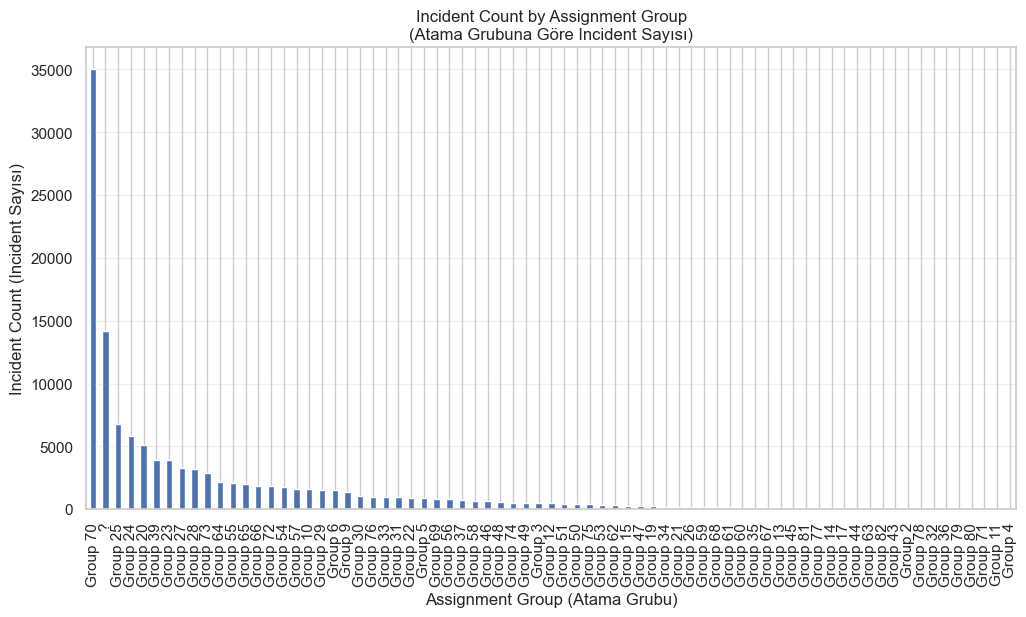

In [114]:
plt.figure(figsize=(12,6))

incident_group.plot(
    kind="bar"
)

plt.title("Incident Count by Assignment Group\n(Atama Grubuna Göre Incident Sayısı)")
plt.xlabel("Assignment Group (Atama Grubu)")
plt.ylabel("Incident Count (Incident Sayısı)")
plt.xticks(rotation=90)

plt.grid(axis="y", alpha=0.3)

plt.show()

Atama gruplarına göre incident dağılımı incelendiğinde iş yükünün ekipler arasında dengeli dağılmadığı görülmektedir. Özellikle Group 70 toplam 35.023 incident ile en yoğun çalışan ekip olarak öne çıkmaktadır. Bunu Group 25, Group 24 ve Group 20 takip etmektedir. Buna karşılık birçok ekipte incident sayısının oldukça düşük olduğu görülmektedir. Ayrıca "?" olarak görünen atama grubunda 14.213 incident kaydı bulunması, veri kalitesi açısından eksik veya tanımlanmamış ekip bilgilerinin bulunduğunu göstermektedir. Bu durum analiz sonuçlarının doğruluğunu etkileyebileceğinden veri giriş süreçlerinin gözden geçirilmesi faydalı olacaktır.

### 7.5.2 Top 10 Assignment Groups (En Yoğun 10 Ekip)

Bu bölümde en fazla incident yöneten ilk 10 ekip belirlenmektedir. Böylece operasyonel yükün hangi ekiplerde yoğunlaştığı daha net görülebilmektedir.

In [115]:
top10_groups = (
    df["assignment_group"]
    .value_counts()
    .head(10)
)

top10_groups

assignment_group
Group 70    35023
?           14213
Group 25     6765
Group 24     5823
Group 20     5146
Group 39     3951
Group 23     3881
Group 27     3243
Group 28     3190
Group 73     2841
Name: count, dtype: int64

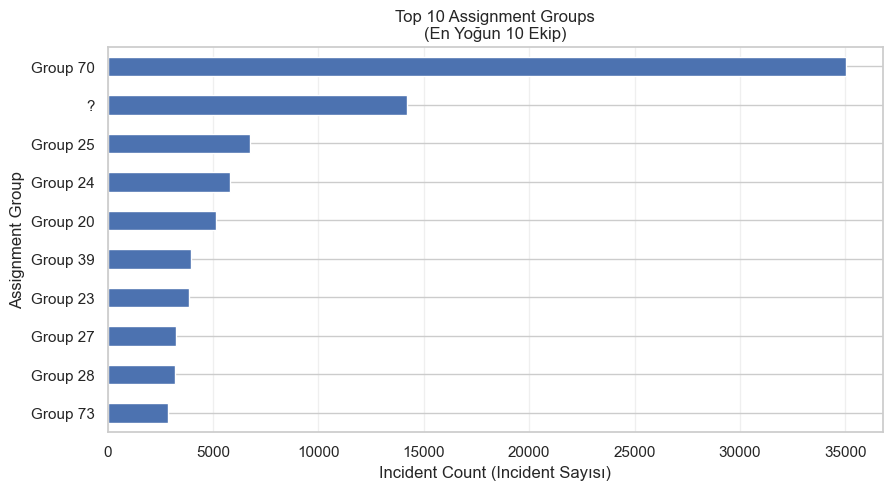

In [116]:
plt.figure(figsize=(10,5))

top10_groups.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Assignment Groups\n(En Yoğun 10 Ekip)")
plt.xlabel("Incident Count (Incident Sayısı)")
plt.ylabel("Assignment Group")

plt.grid(axis="x", alpha=0.3)

plt.show()

En yoğun çalışan ilk 10 ekip incelendiğinde operasyonel iş yükünün büyük ölçüde belirli ekiplerde toplandığı görülmektedir. Özellikle Group 70, diğer tüm ekiplerden belirgin şekilde daha fazla incident yönetmektedir. İlk 10 ekip içerisinde yer alan gruplar toplam incident kayıtlarının önemli bir bölümünü oluşturmaktadır. Bu durum, operasyonel süreçlerde kaynak planlamasının özellikle yoğun çalışan ekipler dikkate alınarak yapılmasının hizmet kalitesini artırabileceğini göstermektedir.

### 7.5.3 Average Resolution Time by Assignment Group (Ekiplere Göre Ortalama İşlem Süresi)

Bu analizde her ekibin incident kayıtlarını ortalama ne kadar sürede çözdüğü incelenmektedir. Böylece daha hızlı ve daha yavaş çalışan ekipler karşılaştırılabilmektedir.

In [117]:
group_resolution = (
    df.groupby("assignment_group")["resolution_time"]
    .mean()
    .sort_values()
    .round(2)
)

group_resolution

assignment_group
Group 36       0.10
Group 71       2.55
Group 64      38.41
Group 19      63.48
Group 60      96.96
Group 39     108.89
Group 32     110.57
Group 70     124.20
Group 44     125.17
Group 43     138.33
Group 53     143.30
Group 11     159.83
Group 56     163.07
Group 49     163.63
Group 73     171.77
Group 69     178.55
?            179.71
Group 80     179.94
Group 82     187.93
Group 79     193.94
Group 46     201.64
Group 77     206.52
Group 54     209.42
Group 62     213.82
Group 76     231.30
Group 5      231.66
Group 28     237.89
Group 23     241.52
Group 55     241.80
Group 24     246.81
Group 48     248.06
Group 27     249.30
Group 51     256.12
Group 21     263.74
Group 45     273.98
Group 65     290.47
Group 74     293.69
Group 30     307.33
Group 25     319.07
Group 20     335.65
Group 58     345.41
Group 29     365.90
Group 12     366.15
Group 72     369.41
Group 59     370.10
Group 57     370.12
Group 81     382.97
Group 22     392.40
Group 34     410.24
Gro

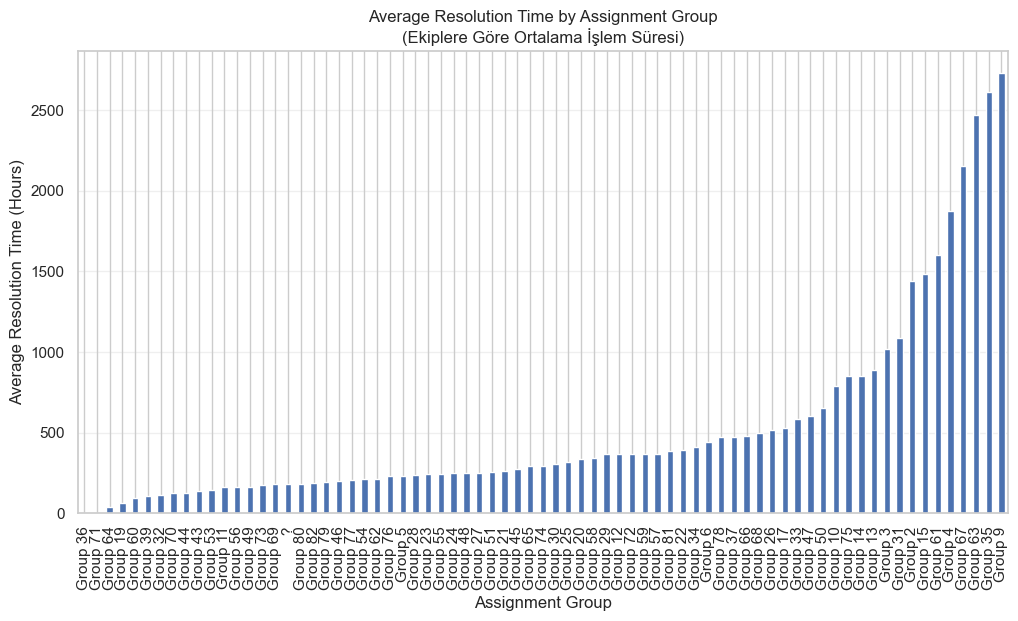

In [118]:
plt.figure(figsize=(12,6))

group_resolution.plot(
    kind="bar"
)

plt.title("Average Resolution Time by Assignment Group\n(Ekiplere Göre Ortalama İşlem Süresi)")
plt.xlabel("Assignment Group")
plt.ylabel("Average Resolution Time (Hours)")
plt.xticks(rotation=90)

plt.grid(axis="y", alpha=0.3)

plt.show()

Ekiplere göre ortalama işlem süreleri incelendiğinde ekipler arasında önemli performans farklılıkları olduğu görülmektedir. Group 64, Group 70 ve Group 39 gibi ekipler incident kayıtlarını görece kısa sürede çözerken; Group 9, Group 35, Group 63, Group 67 ve Group 61 gibi ekiplerde ortalama çözüm sürelerinin oldukça yüksek olduğu belirlenmiştir. Bununla birlikte yalnızca çok az sayıda incident yöneten ekiplerde görülen aşırı düşük veya aşırı yüksek ortalama süreler (örneğin Group 4 veya Group 36) örneklem sayısının düşük olması nedeniyle dikkatli değerlendirilmelidir. Genel olarak ekipler arasındaki çözüm süresi farklılıkları, iş yükü dağılımı, personel kapasitesi veya incident karmaşıklığı gibi faktörlerden kaynaklanıyor olabilir.

### 7.5.4 SLA Performance by Assignment Group (Ekiplere Göre SLA Performansı)

Bu analizde ekiplerin SLA başarı oranları incelenmektedir. Böylece hangi ekiplerin SLA hedeflerini daha yüksek oranda karşıladığı belirlenmektedir.

In [119]:
group_sla = (
    pd.crosstab(
        df["assignment_group"],
        df["made_sla"],
        normalize="index"
    ) * 100
).round(2)

group_sla

made_sla,False,True
assignment_group,,
?,7.84,92.16
Group 10,15.40,84.60
Group 11,0.00,100.00
Group 12,20.13,79.87
Group 13,15.09,84.91
Group 14,17.65,82.35
Group 15,15.79,84.21
Group 17,11.11,88.89
Group 19,3.43,96.57


<Figure size 1200x600 with 0 Axes>

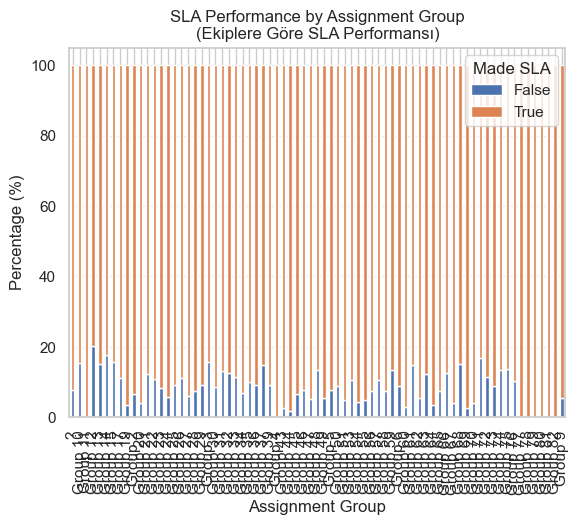

In [120]:
plt.figure(figsize=(12,6))

group_sla.plot(
    kind="bar",
    stacked=True
)

plt.title("SLA Performance by Assignment Group\n(Ekiplere Göre SLA Performansı)")
plt.xlabel("Assignment Group")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=90)

plt.legend(title="Made SLA")

plt.grid(axis="y", alpha=0.3)

plt.show()

Ekip bazında SLA performansı incelendiğinde ekiplerin büyük çoğunluğunun %90'a yakın veya üzerinde SLA başarı oranına sahip olduğu görülmektedir. Özellikle Group 69 (%97,52), Group 44 (%98,25), Group 64 (%96,50), Group 60 (%96,97) ve Group 70 (%96,07) yüksek SLA performansı sergilemektedir. Buna karşılık Group 12 (%79,87), Group 14 (%82,35), Group 10 (%84,60) ve Group 68 (%84,83) gibi ekiplerde SLA başarı oranlarının daha düşük olduğu görülmektedir. Ancak yalnızca birkaç incident kaydına sahip ekiplerde görülen %100 SLA başarı oranları, örneklem sayısının düşük olması nedeniyle tek başına performans göstergesi olarak değerlendirilmemelidir. Genel olarak ekipler arasındaki SLA farklılıkları, bazı ekiplerde süreç iyileştirmesi ve kaynak planlamasının yeniden gözden geçirilmesi gerektiğini göstermektedir.

### 7.5.5 Employee Workload Analysis (Çalışan İş Yükü Analizi)

Bu bölümde incident kayıtlarının çalışanlara (assigned_to) göre dağılımı incelenmektedir. Amaç, çalışanların iş yükünü değerlendirmek ve incident dağılımını analiz etmektir. Analize başlamadan önce çalışan bilgilerinin yeterliliği kontrol edilmektedir.

In [121]:
assigned_employee = (
    df["assigned_to"]
    .value_counts(dropna=False)
)

assigned_employee.head(20)

assigned_to
?               23030
Resolver 17     10056
Resolver 13      7222
Resolver 194     2955
Resolver 57      2907
Resolver 69      2675
Resolver 33      2139
Resolver 215     1957
Resolver 24      1891
Resolver 249     1847
Resolver 78      1832
Resolver 115     1596
Resolver 236     1568
Resolver 31      1562
Resolver 140     1539
Resolver 94      1519
Resolver 125     1409
Resolver 253     1286
Resolver 198     1284
Resolver 34      1227
Name: count, dtype: int64

Çalışan bilgilerinde eksik değer bulunup bulunmadığı kontrol edilmektedir.

In [122]:
df["assigned_to"].isnull().sum()

np.int64(0)

In [123]:
missing_employee = df["assigned_to"].isnull().sum()

print("Eksik çalışan bilgisi:", missing_employee)

Eksik çalışan bilgisi: 0


Analiz öncesinde çalışan bilgileri kontrol edilmiş ve assigned_to değişkeninde eksik (Null) değer bulunmadığı belirlenmiştir. Bununla birlikte en fazla incident alan kayıt "?" olarak görünmektedir. Bu durum eksik veri değil, çalışan bilgisinin anonimleştirilmiş veya bilinmeyen olarak tutulduğunu göstermektedir. Çalışan bazındaki analizler bu kayıtlar da dikkate alınarak gerçekleştirilmiştir.

### 7.5.6 Incident Distribution by Employee (Çalışanlara Göre Incident Dağılımı)

Bu bölümde incident kayıtları çalışan (assigned_to) bazında incelenmektedir. Çalışanların yönettiği incident sayıları, ortalama işlem süreleri ve SLA performansları analiz edilerek bireysel operasyonel performans değerlendirilmektedir.

#### 7.5.6.1 Top 15 Employees by Incident Count (En Fazla Incident Alan 15 Çalışan)

Bu analizde en fazla incident atanan ilk 15 çalışan belirlenmektedir. Böylece operasyonel iş yükünün çalışanlar arasındaki dağılımı incelenebilmektedir.

In [124]:
top15_employees = (
    df["assigned_to"]
    .value_counts()
    .head(15)
)

top15_employees

assigned_to
?               23030
Resolver 17     10056
Resolver 13      7222
Resolver 194     2955
Resolver 57      2907
Resolver 69      2675
Resolver 33      2139
Resolver 215     1957
Resolver 24      1891
Resolver 249     1847
Resolver 78      1832
Resolver 115     1596
Resolver 236     1568
Resolver 31      1562
Resolver 140     1539
Name: count, dtype: int64

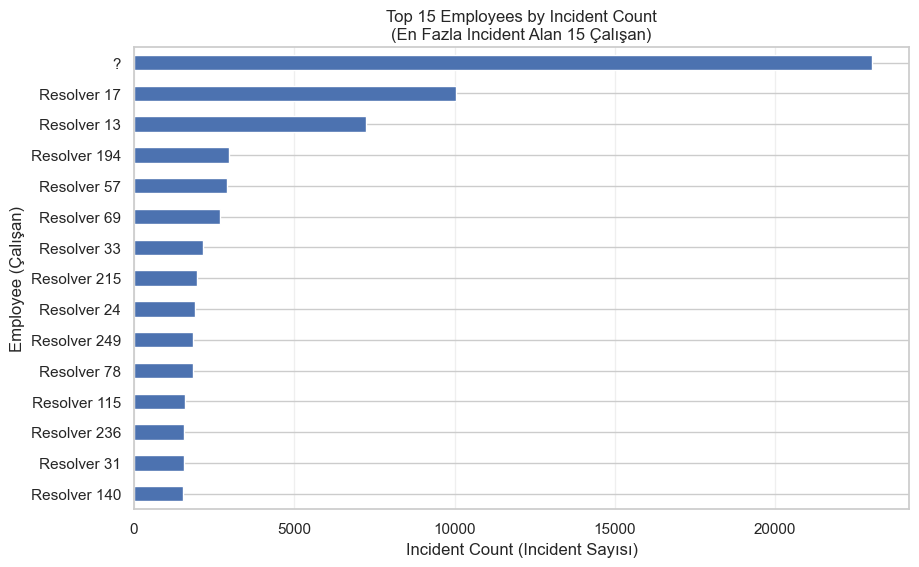

In [125]:
plt.figure(figsize=(10,6))

top15_employees.sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Employees by Incident Count\n(En Fazla Incident Alan 15 Çalışan)")
plt.xlabel("Incident Count (Incident Sayısı)")
plt.ylabel("Employee (Çalışan)")

plt.grid(axis="x", alpha=0.3)

plt.show()

En fazla incident alan çalışanlar incelendiğinde ilk sırada "?" değeri yer almaktadır. Bu kayıtlar gerçek bir çalışanı temsil etmemektedir ve anonimleştirilmiş kullanıcıları ifade etmektedir. Gerçek çalışanlar arasında ise Resolver 17 ve Resolver 13 en fazla incident yöneten çalışanlar olarak öne çıkmaktadır. Bu sonuç bazı çalışanların operasyonel süreçte çok daha yoğun görev aldığını göstermektedir.

#### 7.5.6.2 Average Resolution Time by Employee (Çalışanlara Göre Ortalama İşlem Süresi)

Bu analizde çalışanların incident kayıtlarını ortalama ne kadar sürede çözdükleri incelenmektedir. Böylece daha hızlı ve daha yavaş çalışan personeller belirlenebilmektedir.

In [126]:
employee_resolution = (
    df.groupby("assigned_to")["resolution_time"]
    .mean()
    .sort_values()
    .round(2)
)

employee_resolution

assigned_to
Resolver 5         0.07
Resolver 161       0.13
Resolver 222       0.23
Resolver 38        3.10
Resolver 142       3.28
Resolver 218       5.78
Resolver 30        6.25
Resolver 94        8.97
Resolver 6        15.63
Resolver 128      16.01
Resolver 73       21.63
Resolver 56       30.09
Resolver 15       33.53
Resolver 28       34.02
Resolver 186      34.06
Resolver 252      38.24
Resolver 23       42.71
Resolver 65       43.07
Resolver 99       43.75
Resolver 221      43.98
Resolver 232      45.67
Resolver 190      57.71
Resolver 150      58.99
Resolver 187      59.15
Resolver 144      62.47
Resolver 77       63.76
Resolver 231      70.25
Resolver 212      71.60
Resolver 148      71.77
Resolver 194      75.87
Resolver 127      76.63
Resolver 106      82.13
Resolver 126      86.54
Resolver 183      86.77
Resolver 166      86.99
Resolver 13       87.44
Resolver 92       90.02
Resolver 33       90.56
Resolver 191      91.12
Resolver 58       91.36
Resolver 196      94.16
Reso

***En Hızlı 15 Çalışan***

In [127]:
employee_resolution.head(15)

assigned_to
Resolver 5       0.07
Resolver 161     0.13
Resolver 222     0.23
Resolver 38      3.10
Resolver 142     3.28
Resolver 218     5.78
Resolver 30      6.25
Resolver 94      8.97
Resolver 6      15.63
Resolver 128    16.01
Resolver 73     21.63
Resolver 56     30.09
Resolver 15     33.53
Resolver 28     34.02
Resolver 186    34.06
Name: resolution_time, dtype: float64

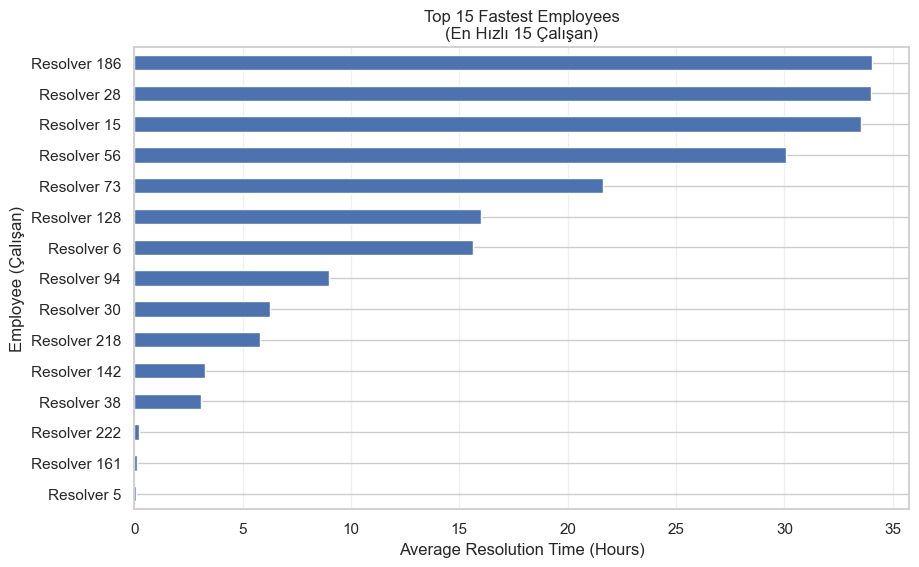

In [128]:
plt.figure(figsize=(10,6))

employee_resolution.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Fastest Employees\n(En Hızlı 15 Çalışan)")
plt.xlabel("Average Resolution Time (Hours)")
plt.ylabel("Employee (Çalışan)")

plt.grid(axis="x", alpha=0.3)

plt.show()

***En Yavaş 15 Çalışan***

In [129]:
employee_resolution.tail(15)

assigned_to
Resolver 238    2275.90
Resolver 207    2300.11
Resolver 81     2646.61
Resolver 98     2762.85
Resolver 163    3198.47
Resolver 223    3405.98
Resolver 217    3421.99
Resolver 160    3969.12
Resolver 131    4206.58
Resolver 114    4385.74
Resolver 18     4504.17
Resolver 90     5155.82
Resolver 52     5272.28
Resolver 181    5285.86
Resolver 9      5361.80
Name: resolution_time, dtype: float64

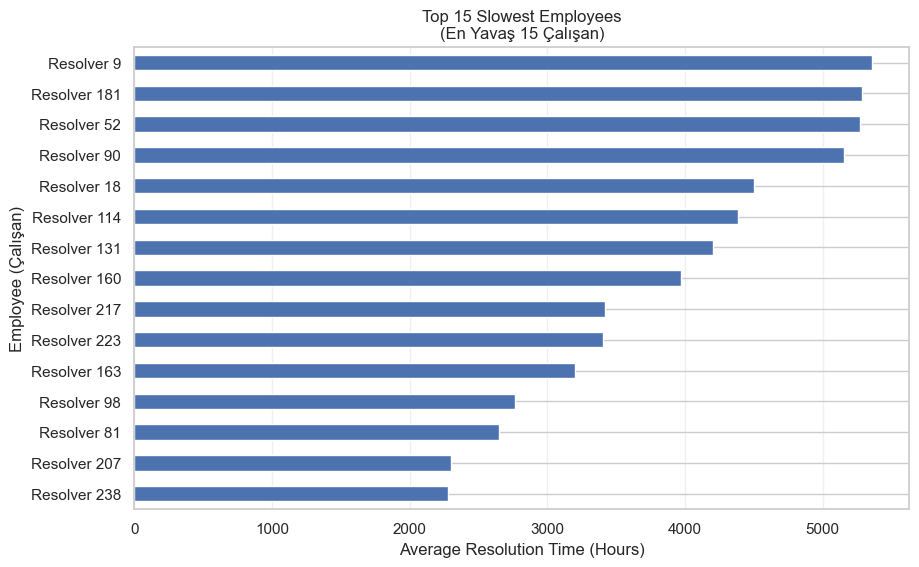

In [130]:
plt.figure(figsize=(10,6))

employee_resolution.tail(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Slowest Employees\n(En Yavaş 15 Çalışan)")
plt.xlabel("Average Resolution Time (Hours)")
plt.ylabel("Employee (Çalışan)")

plt.grid(axis="x", alpha=0.3)

plt.show()

Ortalama işlem süresi en düşük olan çalışanlar incident kayıtlarını oldukça kısa sürede tamamlamaktadır. Ancak bu çalışanların yönettiği incident sayıları da dikkate alınmalıdır. Çok az sayıda incident yöneten çalışanlarda ortalama süreler yanıltıcı olabilir. Bu nedenle performans değerlendirmesinde işlem süresi ile birlikte incident sayısı da göz önünde bulundurulmalıdır.

#### 7.5.6.3 SLA Performance by Employee (Çalışanlara Göre SLA Performansı)

Bu bölümde çalışanların SLA başarı oranları incelenmektedir. Böylece SLA hedeflerini en yüksek oranda karşılayan ve geliştirilmesi gereken çalışanlar belirlenebilmektedir.

In [131]:
employee_sla = (
    pd.crosstab(
        df["assigned_to"],
        df["made_sla"],
        normalize="index"
    ) * 100
).round(2)

employee_sla

made_sla,False,True
assigned_to,,
?,1.65,98.35
Resolver 10,8.33,91.67
Resolver 100,16.04,83.96
Resolver 101,10.62,89.38
Resolver 102,0.00,100.00
Resolver 103,12.07,87.93
Resolver 106,16.67,83.33
Resolver 107,25.00,75.00
Resolver 108,14.29,85.71


In [132]:
employee_sla = employee_sla.sort_values(
    by=True,
    ascending=False
)

employee_sla.head(15)

made_sla,False,True
assigned_to,,
Resolver 238,0.0,100.0
Resolver 128,0.0,100.0
Resolver 131,0.0,100.0
Resolver 67,0.0,100.0
Resolver 142,0.0,100.0
Resolver 143,0.0,100.0
Resolver 62,0.0,100.0
Resolver 146,0.0,100.0
Resolver 55,0.0,100.0


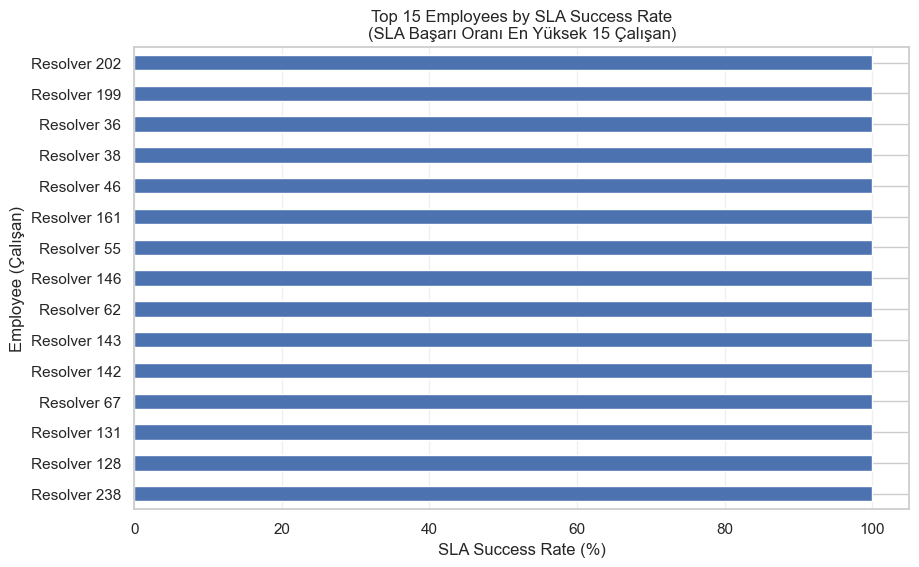

In [133]:
plt.figure(figsize=(10,6))

employee_sla.head(15)[True].sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Employees by SLA Success Rate\n(SLA Başarı Oranı En Yüksek 15 Çalışan)")
plt.xlabel("SLA Success Rate (%)")
plt.ylabel("Employee (Çalışan)")

plt.grid(axis="x", alpha=0.3)

plt.show()

Çalışanların büyük bölümünün SLA başarı oranı oldukça yüksektir. İlk 15 sırada bulunan çalışanların tamamının %100 SLA başarı oranına sahip olduğu görülmektedir. Ancak bu çalışanların önemli bir kısmı düşük sayıda incident yönetmiş olabilir. Bu nedenle çalışan performansı değerlendirilirken yalnızca SLA başarı oranı değil, yönetilen incident sayısı ve ortalama işlem süresi gibi performans göstergeleri birlikte ele alınmalıdır. Bu yaklaşım daha gerçekçi ve güvenilir bir performans değerlendirmesi sağlayacaktır.

#### 7.5.6.4 Employee Performance Summary (Çalışan Performans Özeti)

Bu analizde çalışan performansı yalnızca SLA başarı oranına göre değil; yönetilen incident sayısı, ortalama işlem süresi ve SLA başarı oranı birlikte değerlendirilmektedir. Böylece çok az sayıda incident çözüp yüksek SLA oranına sahip çalışanlarla, yüksek iş yükü altında başarılı performans gösteren çalışanlar daha adil şekilde karşılaştırılabilmektedir.

In [134]:
employee_performance = (
    df.groupby("assigned_to")
    .agg(
        incident_count=("number", "count"),
        average_resolution_time=("resolution_time", "mean"),
        sla_success_rate=("made_sla", "mean")
    )
)

employee_performance["average_resolution_time"] = (
    employee_performance["average_resolution_time"]
    .round(2)
)

employee_performance["sla_success_rate"] = (
    employee_performance["sla_success_rate"] * 100
).round(2)

employee_performance = employee_performance.sort_values(
    by=["sla_success_rate", "incident_count"],
    ascending=[False, False]
)

employee_performance.head(20)

,incident_count,average_resolution_time,sla_success_rate
assigned_to,,,
Resolver 128,51,16.01,100.0
Resolver 142,18,3.28,100.0
Resolver 252,16,38.24,100.0
Resolver 36,16,106.46,100.0
Resolver 143,12,212.81,100.0
Resolver 231,10,70.25,100.0
Resolver 161,7,0.13,100.0
Resolver 222,7,0.23,100.0
Resolver 46,7,122.51,100.0


In [135]:
employee_performance_filtered = (
    employee_performance[
        employee_performance["incident_count"] >= 100
    ]
)

employee_performance_filtered.head(20)

,incident_count,average_resolution_time,sla_success_rate
assigned_to,,,
Resolver 218,331,5.78,99.40
Resolver 30,297,6.25,98.99
?,23030,261.10,98.35
Resolver 15,816,33.53,98.28
Resolver 192,617,224.04,98.22
Resolver 56,878,30.09,97.84
Resolver 151,158,125.16,97.47
Resolver 73,1054,21.63,97.25
Resolver 28,758,34.02,96.97


Çalışan performansı üç farklı gösterge kullanılarak değerlendirilmiştir: yönetilen incident sayısı, ortalama işlem süresi ve SLA başarı oranı. Sonuçlar, yalnızca SLA başarı oranına bakılarak performans değerlendirmesi yapmanın yeterli olmadığını göstermektedir. Bazı çalışanlar %100 SLA başarısına sahip olmasına rağmen çok az sayıda incident yönetmiştir. Buna karşılık yüksek sayıda incident yöneten çalışanlar, yoğun iş yüküne rağmen yüksek SLA başarı oranlarını koruyabilmektedir. Bu nedenle çalışan performansının değerlendirilmesinde iş yükü, çözüm süresi ve SLA başarısının birlikte ele alınması daha gerçekçi ve güvenilir sonuçlar sağlamaktadır.

## 7.6 Bottleneck Analysis (Darboğaz Analizi)

Bu bölümde incident yönetim sürecinde darboğaz (bottleneck) oluşturan alanlar analiz edilmektedir. Darboğaz, incident kayıtlarının normalden daha uzun süre beklediği veya çözüm süresinin önemli ölçüde uzadığı süreçleri ifade etmektedir.
Bu analiz sayesinde;

- işlem süresini artıran ekipler,
- uzun süren kategoriler,
- yüksek yeniden atama sayısına sahip incident kayıtları,
- tekrar açılan incidentlar,
- SLA ihlallerine neden olan süreçler

belirlenerek operasyonel iyileştirme yapılabilecek alanlar ortaya çıkarılacaktır.

### 7.6.1 Longest Resolution Time Analysis (En Uzun İşlem Süresine Sahip Incidentlar)

İlk olarak en uzun sürede çözülen incident kayıtları incelenmektedir. Bu analiz sayesinde operasyon içerisinde en fazla gecikmeye neden olan incidentlar belirlenebilmektedir. Bu kayıtların detaylı olarak incelenmesi, darboğaz oluşturan süreçlerin tespit edilmesine katkı sağlamaktadır.

In [136]:
longest_resolution = (
    df[
        [
            "number",
            "assignment_group",
            "assigned_to",
            "category",
            "priority",
            "resolution_time"
        ]
    ]
    .sort_values(
        by="resolution_time",
        ascending=False
    )
)

longest_resolution.head(20)

,number,assignment_group,assigned_to,category,priority,resolution_time
7812,INC0001839,Group 31,Resolver 207,Category 45,3 - Moderate,8070.166667
7816,INC0001839,Group 31,Resolver 207,Category 45,3 - Moderate,8070.166667
7815,INC0001839,Group 31,Resolver 207,Category 45,3 - Moderate,8070.166667
7814,INC0001839,Group 31,Resolver 207,Category 45,3 - Moderate,8070.166667
7813,INC0001839,Group 31,Resolver 207,Category 45,3 - Moderate,8070.166667
5615,INC0001349,Group 67,Resolver 223,Category 45,3 - Moderate,8020.266667
5625,INC0001349,Group 67,Resolver 223,Category 45,4 - Low,8020.266667
5624,INC0001349,Group 67,Resolver 223,Category 45,4 - Low,8020.266667
5623,INC0001349,Group 67,Resolver 223,Category 45,4 - Low,8020.266667
5622,INC0001349,Group 67,Resolver 223,Category 45,4 - Low,8020.266667


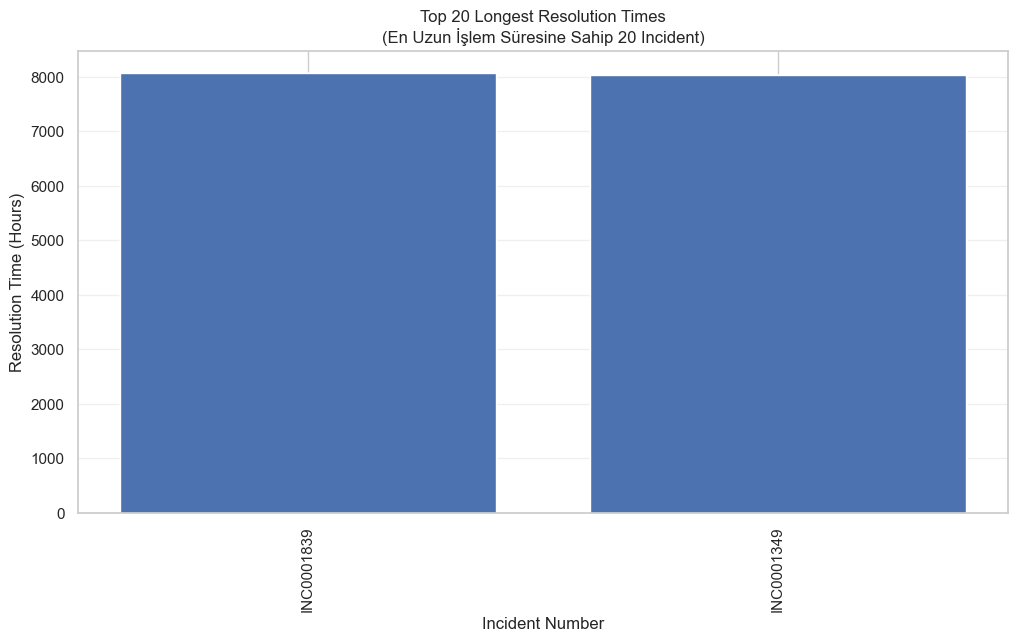

In [137]:
plt.figure(figsize=(12,6))

plt.bar(
    longest_resolution.head(20)["number"],
    longest_resolution.head(20)["resolution_time"]
)

plt.title(
    "Top 20 Longest Resolution Times\n"
    "(En Uzun İşlem Süresine Sahip 20 Incident)"
)

plt.xlabel("Incident Number")
plt.ylabel("Resolution Time (Hours)")

plt.xticks(rotation=90)

plt.grid(axis="y", alpha=0.3)

plt.show()

Analiz sonucunda en uzun çözüm süresine sahip incident kayıtlarının yaklaşık 8000 saatin üzerinde çözüldüğü görülmektedir. Özellikle INC0001839 ve INC0001349 numaralı incident kayıtları listenin ilk sıralarında yer almaktadır. Bu kayıtların büyük bölümünün Category 45 kategorisinde yer alması ve ağırlıklı olarak Group 31 ile Group 67 ekiplerine atanmış olması dikkat çekmektedir.

### 7.6.2 Distribution of Resolution Time (İşlem Süresi Dağılımı)

Bu analizde Assignment Group (Atama Grubu) bazında ortalama çözüm süreleri incelenmektedir. Amaç, incident kayıtlarının çözümünde en fazla gecikmeye neden olan ekipleri belirlemektir. Ortalama çözüm süresi yüksek olan ekipler operasyonel darboğaz oluşturabilecek gruplar olarak değerlendirilmektedir. Analiz sonuçları ekip bazlı süreç iyileştirmelerine katkı sağlamaktadır.

In [138]:
group_bottleneck = (
    df.groupby("assignment_group")["resolution_time"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

group_bottleneck

assignment_group
Group 9     2730.36
Group 35    2612.65
Group 63    2472.46
Group 67    2155.94
Group 4     1872.68
Group 61    1601.49
Group 15    1481.57
Group 2     1440.22
Group 31    1083.94
Group 3     1021.58
Group 13     891.22
Group 14     853.77
Group 75     848.78
Group 10     788.62
Group 50     649.90
Group 47     600.87
Group 33     585.98
Group 17     531.46
Group 26     518.78
Group 68     499.58
Group 66     481.47
Group 37     474.56
Group 78     474.25
Group 6      438.99
Group 34     410.24
Group 22     392.40
Group 81     382.97
Group 57     370.12
Group 59     370.10
Group 72     369.41
Group 12     366.15
Group 29     365.90
Group 58     345.41
Group 20     335.65
Group 25     319.07
Group 30     307.33
Group 74     293.69
Group 65     290.47
Group 45     273.98
Group 21     263.74
Group 51     256.12
Group 27     249.30
Group 48     248.06
Group 24     246.81
Group 55     241.80
Group 23     241.52
Group 28     237.89
Group 5      231.66
Group 76     231.30
Gro

***en yavaş 15 ekip***

In [139]:
group_bottleneck.head(15)

assignment_group
Group 9     2730.36
Group 35    2612.65
Group 63    2472.46
Group 67    2155.94
Group 4     1872.68
Group 61    1601.49
Group 15    1481.57
Group 2     1440.22
Group 31    1083.94
Group 3     1021.58
Group 13     891.22
Group 14     853.77
Group 75     848.78
Group 10     788.62
Group 50     649.90
Name: resolution_time, dtype: float64

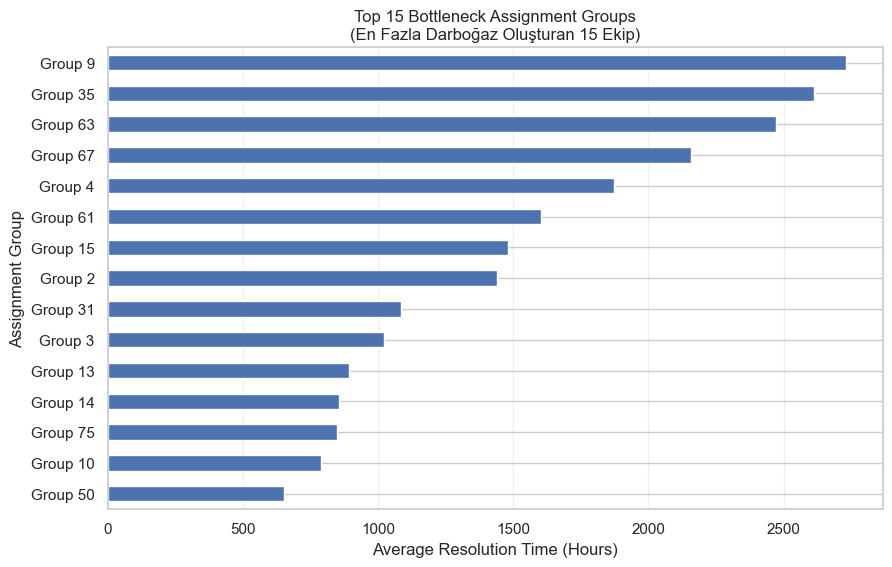

In [140]:
plt.figure(figsize=(10,6))

group_bottleneck.head(15).sort_values().plot(
    kind="barh"
)

plt.title(
    "Top 15 Bottleneck Assignment Groups\n"
    "(En Fazla Darboğaz Oluşturan 15 Ekip)"
)

plt.xlabel("Average Resolution Time (Hours)")
plt.ylabel("Assignment Group")

plt.grid(axis="x", alpha=0.3)

plt.show()

Assignment Group bazında yapılan analiz sonucunda ekipler arasında çözüm süreleri açısından önemli farklılıklar olduğu görülmektedir. Özellikle Group 9, Group 35 ve Group 63 ekipleri en yüksek ortalama çözüm sürelerine sahip gruplar olarak öne çıkmaktadır. Buna karşılık bazı ekiplerin çözüm sürelerinin oldukça düşük olması, iş yükü dağılımı veya uzmanlık alanları açısından ekipler arasında farklılıklar bulunduğunu göstermektedir.

### 7.6.3 Bottleneck Analysis by Employee (Darboğaz Oluşturan Çalışanların Analizi)

Bu bölümde çalışanlar (assigned_to) bazında ortalama çözüm süreleri incelenmektedir. Amaç, çözüm süresi en yüksek olan çalışanları belirleyerek bireysel düzeyde operasyonel darboğazların tespit edilmesidir. Böylece eğitim ihtiyacı, iş yükü dağılımı veya süreç iyileştirme gerektiren alanlar belirlenebilecektir.

In [141]:
employee_bottleneck = (
    df.groupby("assigned_to")["resolution_time"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

employee_bottleneck

assigned_to
Resolver 9      5361.80
Resolver 181    5285.86
Resolver 52     5272.28
Resolver 90     5155.82
Resolver 18     4504.17
Resolver 114    4385.74
Resolver 131    4206.58
Resolver 160    3969.12
Resolver 217    3421.99
Resolver 223    3405.98
Resolver 163    3198.47
Resolver 98     2762.85
Resolver 81     2646.61
Resolver 207    2300.11
Resolver 238    2275.90
Resolver 64     2254.23
Resolver 124    2151.28
Resolver 48     2047.11
Resolver 205    1702.02
Resolver 225    1606.80
Resolver 100    1447.67
Resolver 96     1322.36
Resolver 209    1233.74
Resolver 178    1226.69
Resolver 171    1043.06
Resolver 220    1040.32
Resolver 62     1027.52
Resolver 108     995.08
Resolver 59      950.64
Resolver 102     924.12
Resolver 230     921.90
Resolver 55      890.12
Resolver 87      865.61
Resolver 71      861.51
Resolver 139     834.58
Resolver 200     829.04
Resolver 199     820.68
Resolver 210     754.88
Resolver 158     708.82
Resolver 89      701.41
Resolver 246     700.85
Reso

***en yavaş 15 çalışan***

In [142]:
employee_bottleneck.head(15)

assigned_to
Resolver 9      5361.80
Resolver 181    5285.86
Resolver 52     5272.28
Resolver 90     5155.82
Resolver 18     4504.17
Resolver 114    4385.74
Resolver 131    4206.58
Resolver 160    3969.12
Resolver 217    3421.99
Resolver 223    3405.98
Resolver 163    3198.47
Resolver 98     2762.85
Resolver 81     2646.61
Resolver 207    2300.11
Resolver 238    2275.90
Name: resolution_time, dtype: float64

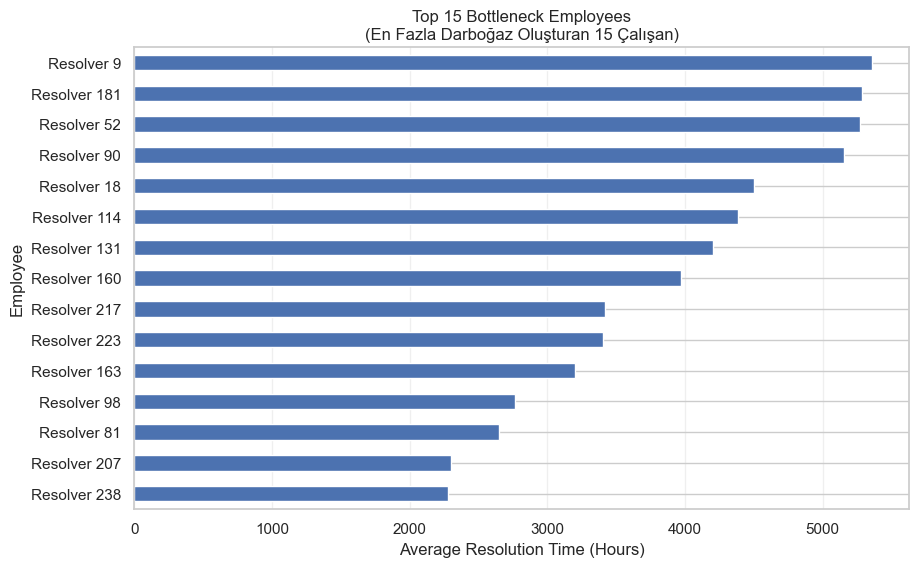

In [296]:
plt.figure(figsize=(10,6))

employee_bottleneck.head(15).sort_values().plot(
    kind="barh"
)

plt.title(
    "Top 15 Bottleneck Employees\n"
    "(En Fazla Darboğaz Oluşturan 15 Çalışan)"
)

plt.xlabel("Average Resolution Time (Hours)")
plt.ylabel("Employee")

plt.grid(axis="x", alpha=0.3)

plt.show()

Çalışan bazında gerçekleştirilen analiz sonucunda bazı çalışanların ortalama çözüm sürelerinin diğer çalışanlara göre oldukça yüksek olduğu belirlenmiştir. Özellikle Resolver 9, Resolver 181, Resolver 52 ve Resolver 90 en uzun ortalama çözüm süresine sahip çalışanlar arasında yer almaktadır.

### 7.6.4 Bottleneck Analysis by Category (Kategori Bazında Darboğaz Analizi)

Bu bölümde incident kayıtlarının Category (Kategori) bazında ortalama çözüm süreleri incelenmektedir. Amaç, hangi kategoriye ait incident kayıtlarının çözümünün daha uzun sürdüğünü belirlemektir. Ortalama çözüm süresi yüksek olan kategoriler, süreçlerde iyileştirme yapılması gereken alanları göstermektedir.

In [144]:
category_bottleneck = (
    df.groupby("category")["resolution_time"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

category_bottleneck

category
Category 29    2340.21
Category 34    1712.76
Category 55     798.15
Category 56     673.10
Category 45     593.71
?               578.01
Category 22     539.26
Category 25     512.07
Category 49     434.22
Category 24     423.08
Category 46     415.59
Category 19     387.31
Category 7      331.46
Category 62     324.29
Category 47     322.31
Category 4      283.42
Category 9      255.91
Category 61     253.65
Category 37     251.02
Category 38     243.98
Category 57     229.83
Category 23     228.07
Category 17     223.20
Category 40     215.57
Category 44     193.42
Category 41     188.68
Category 31     188.17
Category 43     188.03
Category 53     185.67
Category 42     179.33
Category 8      171.40
Category 30     171.24
Category 28     168.37
Category 54     165.67
Category 26     149.76
Category 32     132.84
Category 63     127.19
Category 13     118.36
Category 20     108.30
Category 51     104.25
Category 35      62.63
Category 3       21.23
Category 27       1.58
Ca

***en uzun çözüm süresine sahip 15 kategori***

In [145]:
category_bottleneck.head(15)

category
Category 29    2340.21
Category 34    1712.76
Category 55     798.15
Category 56     673.10
Category 45     593.71
?               578.01
Category 22     539.26
Category 25     512.07
Category 49     434.22
Category 24     423.08
Category 46     415.59
Category 19     387.31
Category 7      331.46
Category 62     324.29
Category 47     322.31
Name: resolution_time, dtype: float64

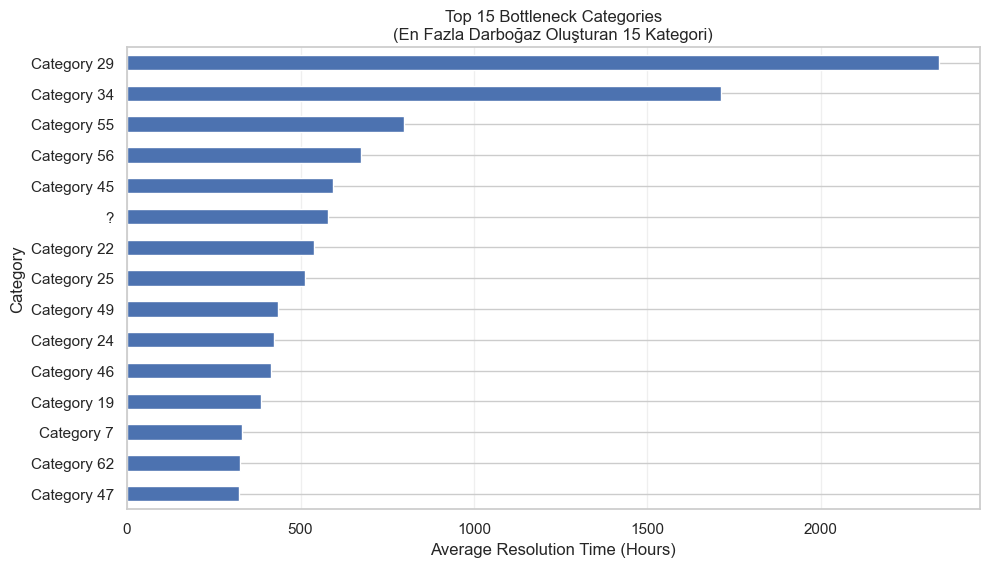

In [146]:
plt.figure(figsize=(11,6))

category_bottleneck.head(15).sort_values().plot(
    kind="barh"
)

plt.title(
    "Top 15 Bottleneck Categories\n"
    "(En Fazla Darboğaz Oluşturan 15 Kategori)"
)

plt.xlabel("Average Resolution Time (Hours)")
plt.ylabel("Category")

plt.grid(axis="x", alpha=0.3)

plt.show()

Kategori bazında yapılan analiz sonucunda bazı incident kategorilerinin diğerlerine göre çok daha uzun çözüm sürelerine sahip olduğu görülmektedir. Özellikle Category 29 ve Category 34 ortalama çözüm süresi açısından ilk sıralarda yer almaktadır. Bunun yanında Category 55 ve Category 56 kategorilerinin de yüksek çözüm sürelerine sahip olduğu belirlenmiştir.

### 7.6.5 Bottleneck Analysis by Priority (Öncelik Bazında Darboğaz Analizi)

Bu analizde incident kayıtlarının Priority (Öncelik) seviyelerine göre ortalama çözüm süreleri incelenmektedir. Böylece hangi öncelik seviyesinde bulunan incident kayıtlarının daha uzun sürede çözüldüğü belirlenmektedir.

In [147]:
priority_bottleneck = (
    df.groupby("priority")["resolution_time"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

priority_bottleneck

priority
4 - Low         452.70
3 - Moderate    277.42
1 - Critical    251.95
2 - High        191.45
Name: resolution_time, dtype: float64

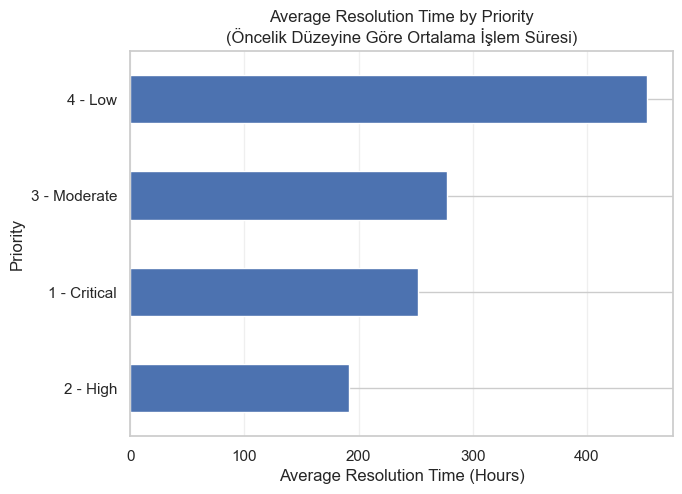

In [148]:
plt.figure(figsize=(7,5))

priority_bottleneck.sort_values().plot(
    kind="barh"
)

plt.title(
    "Average Resolution Time by Priority\n"
    "(Öncelik Düzeyine Göre Ortalama İşlem Süresi)"
)

plt.xlabel("Average Resolution Time (Hours)")
plt.ylabel("Priority")

plt.grid(axis="x", alpha=0.3)

plt.show()

Öncelik seviyelerine göre yapılan analiz sonucunda 4 - Low önceliğine sahip incident kayıtlarının ortalama çözüm süresinin diğer öncelik seviyelerine göre daha yüksek olduğu görülmektedir. Bunu sırasıyla 3 - Moderate, 1 - Critical ve 2 - High öncelikleri takip etmektedir.

### 7.6.6 Root Cause Analysis of Bottlenecks (Darboğazların Kök Neden Analizi)

Bu bölümde çözüm süresi uzun olan incident kayıtlarının ortak özellikleri incelenmektedir. Amaç, darboğazların yalnızca hangi ekip veya çalışanlarda oluştuğunu değil, aynı zamanda bu gecikmelerin hangi öncelik seviyelerinde, kategorilerde ve SLA durumlarında yoğunlaştığını belirlemektir. Bu analiz, operasyonel süreçlerde iyileştirme yapılacak alanların tespit edilmesine yardımcı olmaktadır.

#### 7.6.6.1 Priority Distribution of Long Resolution Incidents (Uzun Süreli Incidentların Öncelik Dağılımı)

En uzun çözüm süresine sahip ilk 100 incident kaydının öncelik seviyeleri incelenmektedir.

In [149]:
top100_longest = (
    df.sort_values(
        by="resolution_time",
        ascending=False
    )
    .head(100)
)

priority_distribution = (
    top100_longest["priority"]
    .value_counts()
)

priority_distribution

priority
3 - Moderate    61
4 - Low         39
Name: count, dtype: int64

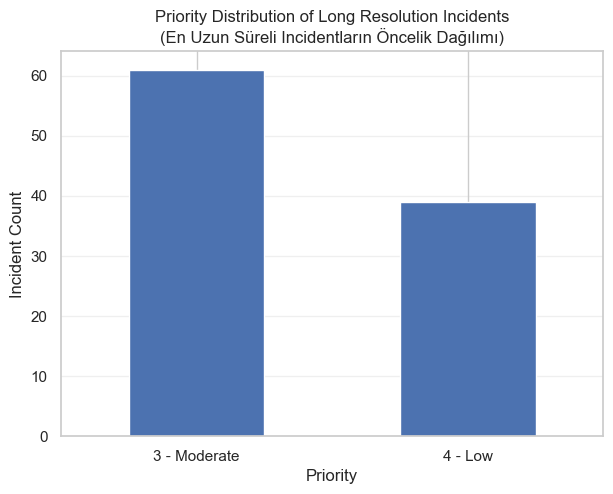

In [150]:
plt.figure(figsize=(7,5))

priority_distribution.plot(
    kind="bar"
)

plt.title(
    "Priority Distribution of Long Resolution Incidents\n"
    "(En Uzun Süreli Incidentların Öncelik Dağılımı)"
)

plt.xlabel("Priority")
plt.ylabel("Incident Count")

plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.show()

En uzun çözüm süresine sahip ilk 100 incident incelendiğinde kayıtların 61 tanesinin "3 - Moderate", 39 tanesinin ise "4 - Low" öncelik seviyesinde olduğu görülmektedir. İlk 100 kayıt içerisinde Critical veya High öncelikli incident bulunmaması dikkat çekmektedir.

#### 7.6.6.2 Category Distribution of Long Resolution Incidents (Uzun Süreli Incidentların Kategori Dağılımı)

Bu analizde en uzun sürede çözülen incident kayıtlarının hangi kategorilerde yoğunlaştığı incelenmektedir.

In [151]:
category_distribution = (
    top100_longest["category"]
    .value_counts()
)

category_distribution

category
Category 45    32
Category 37    30
Category 55    18
Category 42     8
Category 57     6
Category 46     3
Category 53     2
Category 40     1
Name: count, dtype: int64

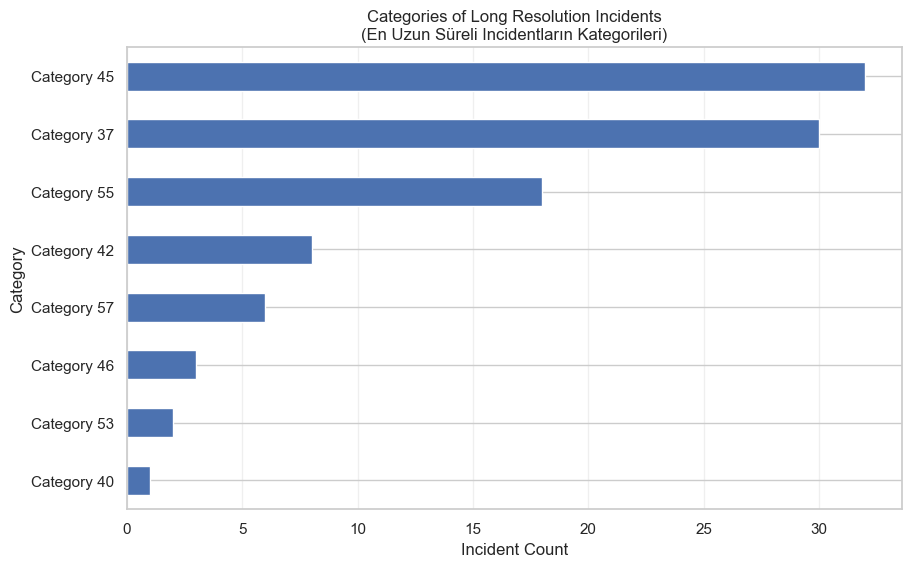

In [152]:
plt.figure(figsize=(10,6))

category_distribution.head(15).sort_values().plot(
    kind="barh"
)

plt.title(
    "Categories of Long Resolution Incidents\n"
    "(En Uzun Süreli Incidentların Kategorileri)"
)

plt.xlabel("Incident Count")
plt.ylabel("Category")

plt.grid(axis="x", alpha=0.3)

plt.show()

En uzun çözüm süresine sahip ilk 100 incident incelendiğinde kayıtların büyük bölümünün Category 45 ve Category 37 kategorilerinde toplandığı görülmektedir. Bunun yanında Category 55 de dikkat çeken kategoriler arasında yer almaktadır.

#### 7.6.6.3 SLA Status of Long Resolution Incidents (Uzun Süreli Incidentlarda SLA Durumu)

Bu analizde en uzun çözüm süresine sahip incident kayıtlarının SLA başarı durumları incelenmektedir.

In [153]:
sla_long = (
    top100_longest["made_sla"]
    .value_counts()
)

sla_long

made_sla
True     89
False    11
Name: count, dtype: int64

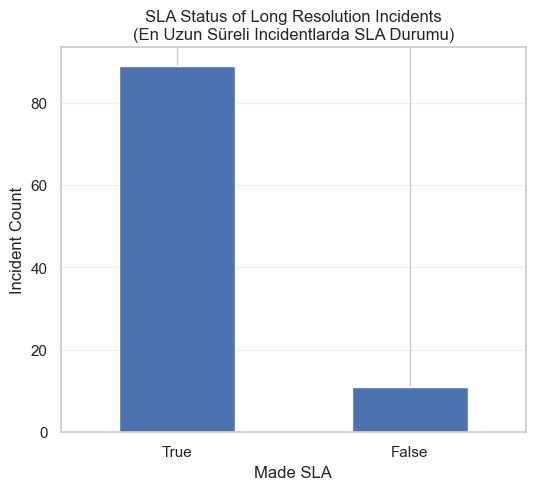

In [154]:
plt.figure(figsize=(6,5))

sla_long.plot(
    kind="bar"
)

plt.title(
    "SLA Status of Long Resolution Incidents\n"
    "(En Uzun Süreli Incidentlarda SLA Durumu)"
)

plt.xlabel("Made SLA")
plt.ylabel("Incident Count")

plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.show()

En uzun çözüm süresine sahip ilk 100 incident incelendiğinde kayıtların 89'unun SLA hedefini karşıladığı, 11'inin ise SLA ihlali gerçekleştirdiği görülmektedir. Çözüm süreleri oldukça yüksek olmasına rağmen incident kayıtlarının büyük bölümünün SLA sınırları içerisinde tamamlanmış olması dikkat çekmektedir.

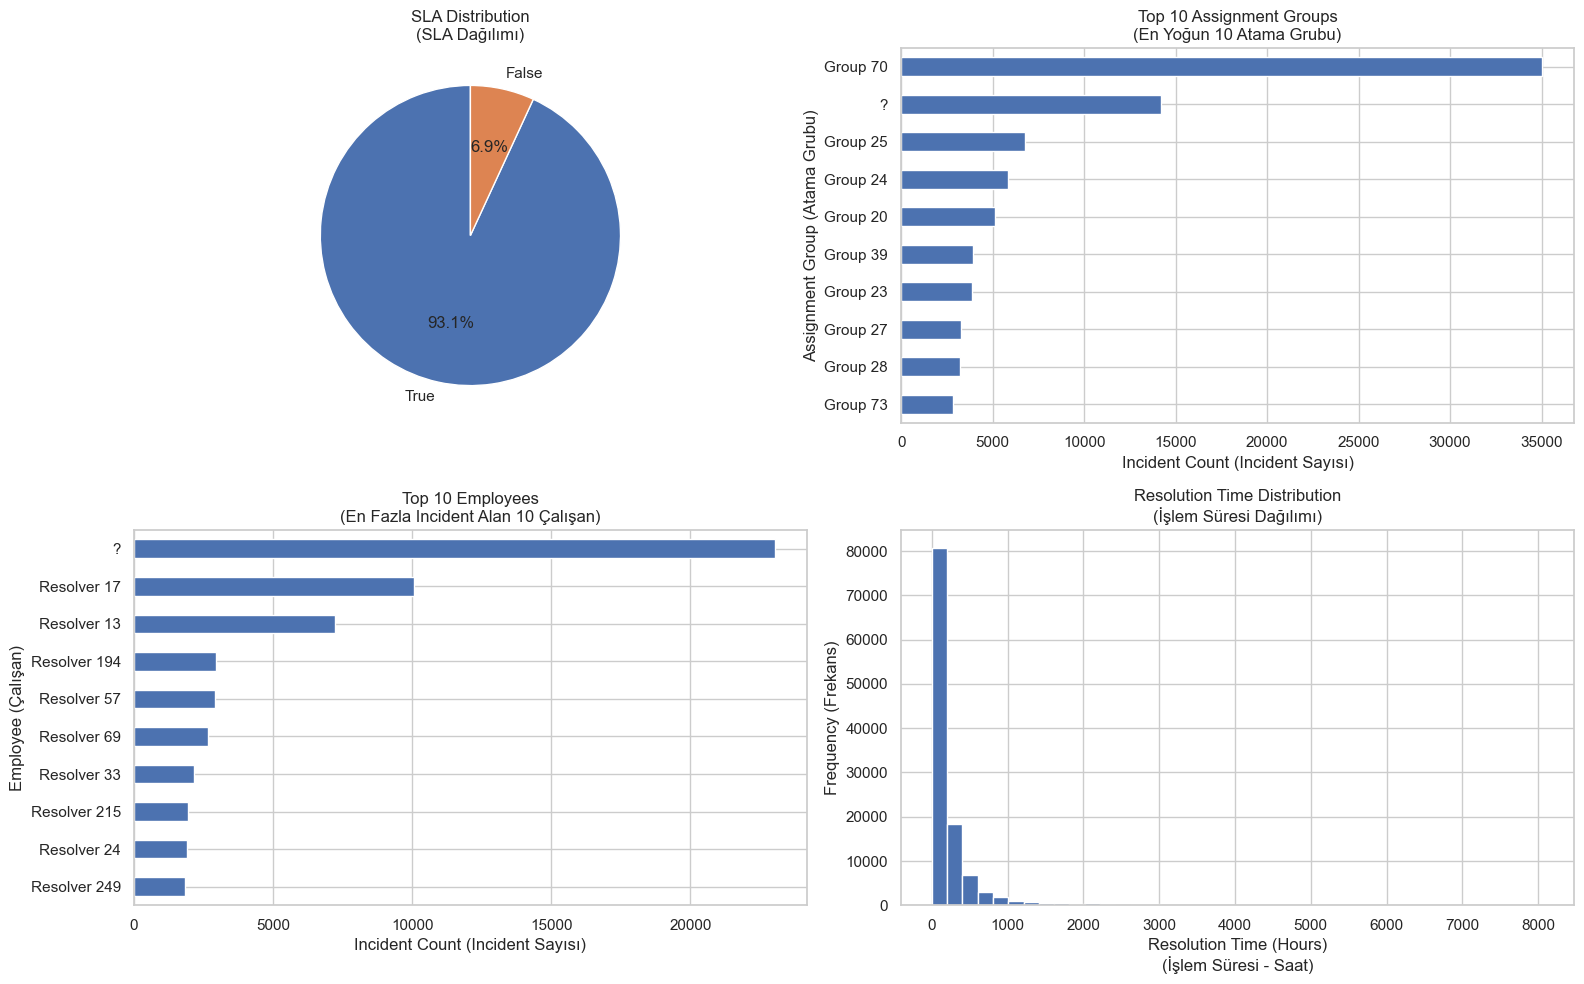

In [155]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1- SLA Distribution
sla = df["made_sla"].value_counts()

axes[0,0].pie(
    sla,
    labels=sla.index,
    autopct="%1.1f%%",
    startangle=90
)

axes[0,0].set_title(
    "SLA Distribution\n(SLA Dağılımı)"
)

# 2- Top Assignment Groups
df["assignment_group"].value_counts().head(10).sort_values().plot(
    kind="barh",
    ax=axes[0,1]
)

axes[0,1].set_title(
    "Top 10 Assignment Groups\n(En Yoğun 10 Atama Grubu)"
)

axes[0,1].set_xlabel(
    "Incident Count (Incident Sayısı)"
)

axes[0,1].set_ylabel(
    "Assignment Group (Atama Grubu)"
)

# 3- Top Employees
df["assigned_to"].value_counts().head(10).sort_values().plot(
    kind="barh",
    ax=axes[1,0]
)

axes[1,0].set_title(
    "Top 10 Employees\n(En Fazla Incident Alan 10 Çalışan)"
)

axes[1,0].set_xlabel(
    "Incident Count (Incident Sayısı)"
)

axes[1,0].set_ylabel(
    "Employee (Çalışan)"
)

# 4- Resolution Time Distribution
axes[1,1].hist(
    df["resolution_time"],
    bins=40
)

axes[1,1].set_title(
    "Resolution Time Distribution\n(İşlem Süresi Dağılımı)"
)

axes[1,1].set_xlabel(
    "Resolution Time (Hours)\n(İşlem Süresi - Saat)"
)

axes[1,1].set_ylabel(
    "Frequency (Frekans)"
)

plt.tight_layout()

plt.show()

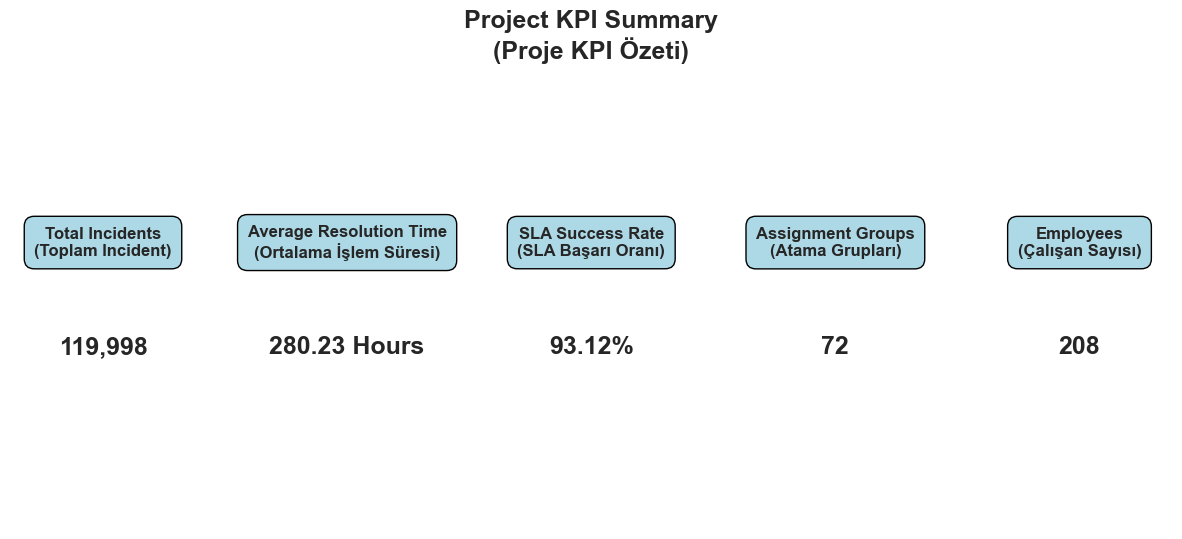

In [156]:
import matplotlib.pyplot as plt

# ==========================
# KPI Değerleri
# ==========================

total_incidents = len(df)

avg_resolution = df["resolution_time"].mean()

sla_rate = (df["made_sla"] == True).mean() * 100

group_count = df[df["assignment_group"] != "?"]["assignment_group"].nunique()

employee_count = df[df["assigned_to"] != "?"]["assigned_to"].nunique()

# ==========================
# Grafik
# ==========================

fig, ax = plt.subplots(figsize=(15,6))

ax.axis("off")

kpis = [

    ("Total Incidents\n(Toplam Incident)",
     f"{total_incidents:,}"),

    ("Average Resolution Time\n(Ortalama İşlem Süresi)",
     f"{avg_resolution:.2f} Hours"),

    ("SLA Success Rate\n(SLA Başarı Oranı)",
     f"{sla_rate:.2f}%"),

    ("Assignment Groups\n(Atama Grupları)",
     group_count),

    ("Employees\n(Çalışan Sayısı)",
     employee_count)

]

# Kutuların konumları
positions = [0.08, 0.29, 0.50, 0.71, 0.92]

for i, (title, value) in enumerate(kpis):

    ax.text(
        positions[i],
        0.62,
        title,
        fontsize=12,
        fontweight="bold",
        ha="center",
        va="center",
        bbox=dict(
            facecolor="lightblue",
            edgecolor="black",
            boxstyle="round,pad=0.6"
        )
    )

    ax.text(
        positions[i],
        0.38,
        value,
        fontsize=18,
        fontweight="bold",
        ha="center"
    )

plt.title(
    "Project KPI Summary\n(Proje KPI Özeti)",
    fontsize=18,
    fontweight="bold"
)

plt.show()

# 8. Machine Learning for Resolution Time Prediction (İşlem Süresi Tahmini için Makine Öğrenmesi)

Bu bölümde incident kayıtlarının çözüm sürelerini tahmin etmek amacıyla makine öğrenmesi modelleri geliştirilmektedir. İlk olarak veri seti makine öğrenmesine uygun hale getirilmekte, daha sonra farklı regresyon algoritmaları eğitilerek performansları karşılaştırılmaktadır. Son aşamada en başarılı model seçilmekte ve incident çözüm süresi tahmininde kullanılmaktadır.

## 8.1 Data Preparation (Veri Hazırlama)

Bu bölümde makine öğrenmesi modeli için kullanılacak veri hazırlanmaktadır. Öncelikle hedef değişken belirlenmekte, daha sonra modele dahil edilecek bağımsız değişkenler seçilmektedir. Tahmin performansını olumsuz etkileyebilecek veya modele katkı sağlamayacak sütunlar veri setinden çıkarılmaktadır.

### 8.1.1 Target Variable (Hedef Değişken)

Makine öğrenmesi modelinin tahmin edeceği değişken resolution_time sütunudur. Bu değişken incident kayıtlarının çözüm süresini saat cinsinden göstermektedir. Bu nedenle hedef değişken (target variable) olarak belirlenmiştir.

In [157]:
target = "resolution_time"

print("Target Variable:", target)

Target Variable: resolution_time


### 8.1.2 Feature Selection (Özellik Seçimi)

Bu bölümde makine öğrenmesi modelinde kullanılacak bağımsız değişkenler belirlenmiştir. Kimlik bilgisi içeren, tahmin sırasında henüz bilinmeyen veya bilgi sızıntısına neden olabilecek sütunlar veri setinden çıkarılmıştır. Bunun yerine incident kaydının açıldığı anda bilinebilecek operasyonel bilgiler modelin giriş değişkenleri olarak seçilmiştir. Bu yaklaşım, modelin gerçek hayatta yeni incident kayıtları için güvenilir tahminler üretebilmesini sağlamaktadır.

In [204]:
df.columns.tolist()

['number',
 'incident_state',
 'active',
 'reassignment_count',
 'reopen_count',
 'sys_mod_count',
 'made_sla',
 'caller_id',
 'opened_by',
 'opened_at',
 'sys_created_by',
 'sys_created_at',
 'sys_updated_by',
 'sys_updated_at',
 'contact_type',
 'location',
 'category',
 'subcategory',
 'u_symptom',
 'cmdb_ci',
 'impact',
 'urgency',
 'priority',
 'assignment_group',
 'assigned_to',
 'knowledge',
 'u_priority_confirmation',
 'notify',
 'problem_id',
 'rfc',
 'vendor',
 'caused_by',
 'closed_code',
 'resolved_by',
 'resolved_at',
 'closed_at',
 'resolution_time',
 'opened_hour',
 'opened_weekday',
 'opened_month',
 'is_weekend',
 'is_business_hours',
 'opened_day',
 'opened_quarter',
 'work_shift',
 'priority_score',
 'impact_score',
 'urgency_score']

In [239]:
# Features (Bağımsız Değişkenler)

features = [

    "incident_state",
    "active",
    "reassignment_count",
    "reopen_count",
    "sys_mod_count",

    "contact_type",
    "location",

    "category",
    "subcategory",
    "u_symptom",
    "cmdb_ci",

    "impact",
    "urgency",
    "priority",

    "assignment_group",
    "assigned_to",

    "knowledge",

    "opened_hour",
    "opened_weekday",
    "opened_month",
    "opened_day",
    "opened_quarter",

    "is_weekend",
    "is_business_hours",
    "work_shift",

    "priority_score",
    "impact_score",
    "urgency_score"

]

target = "resolution_time"

print("Number of Features:", len(features))
print("Target Variable:", target)

Number of Features: 28
Target Variable: resolution_time


### 8.1.3 Creating Feature Matrix and Target Variable (Özellik Matrisi ve Hedef Değişkenin Oluşturulması)

Bu aşamada makine öğrenmesi modelinde kullanılacak bağımsız değişkenler (features) ile hedef değişken (target) birbirinden ayrılmaktadır. Bağımsız değişkenler X, hedef değişken ise y olarak tanımlanmıştır. Bu ayrım, makine öğrenmesi modellerinin eğitilebilmesi için temel bir adımdır.

In [240]:
# Feature Matrix (Bağımsız Değişkenler)
X = df[features]

# Target Variable (Hedef Değişken)
y = df[target]

print("Feature Matrix Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Feature Matrix Shape: (119998, 28)
Target Variable Shape: (119998,)


## 8.2 Data Preprocessing (Veri Ön İşleme)

Bu bölümde makine öğrenmesi modeli için veri seti ön işleme adımlarından geçirilmektedir. Öncelikle bağımsız değişkenlerde eksik değer kontrolü yapılmakta, ardından hedef değişkendeki eksik kayıtlar temizlenmektedir. Daha sonra kategorik değişkenler sayısal değerlere dönüştürülmekte, veri tipleri doğrulanmakta ve son olarak veri seti eğitim ve test kümelerine ayrılmaktadır.

### 8.2.1 Missing Value Check (Eksik Değer Kontrolü)

İlk olarak bağımsız değişkenlerde eksik değer bulunup bulunmadığı kontrol edilmektedir. Eksik değerler makine öğrenmesi modellerinin performansını olumsuz etkileyebileceği için eğitim öncesinde tespit edilmesi önemlidir.

In [241]:
# Missing Value Check

missing_values = X.isnull().sum()

missing_values = missing_values[missing_values > 0]

print(missing_values)

print("Total Missing Values:", X.isnull().sum().sum())

Series([], dtype: int64)
Total Missing Values: 0


### 8.2.2 Target Variable Cleaning (Hedef Değişkenin Temizlenmesi)

Makine öğrenmesi modelleri hedef değişkeni eksik olan kayıtlar ile eğitilemez. Bu nedenle resolution_time sütununda eksik değere sahip incident kayıtları veri setinden çıkarılmıştır. Böylece model yalnızca çözüm süresi bilinen incident kayıtları üzerinden eğitilecektir.

In [242]:
print("Missing values in target:", y.isnull().sum())

Missing values in target: 2861


In [243]:
# Target değişkeni eksik olan kayıtların kaldırılması

df_ml = df[df["resolution_time"].notna()].copy()

print("Original Dataset Shape :", df.shape)
print("Clean Dataset Shape    :", df_ml.shape)

print("Removed Records        :", len(df) - len(df_ml))

Original Dataset Shape : (119998, 48)
Clean Dataset Shape    : (117137, 48)
Removed Records        : 2861


In [244]:
# Feature Matrix

X = df_ml[features].copy()

# Target Variable

y = df_ml[target].copy()

print("Feature Matrix Shape :", X.shape)
print("Target Shape         :", y.shape)

Feature Matrix Shape : (117137, 28)
Target Shape         : (117137,)


### 8.2.3 Encoding Categorical Variables (Kategorik Değişkenlerin Kodlanması)

Makine öğrenmesi algoritmaları kategorik (metinsel) verileri doğrudan işleyememektedir. Bu nedenle kategorik değişkenler Label Encoding yöntemi kullanılarak sayısal değerlere dönüştürülmüştür. Bu yöntem her kategoriye benzersiz bir tam sayı atayarak veri setini makine öğrenmesi modelleri için uygun hale getirmektedir.

In [245]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

categorical_columns = X.select_dtypes(include=["object"]).columns

print("Categorical Columns:")

print(categorical_columns.tolist())

Categorical Columns:
['incident_state', 'contact_type', 'location', 'category', 'subcategory', 'u_symptom', 'cmdb_ci', 'impact', 'urgency', 'priority', 'assignment_group', 'assigned_to', 'opened_weekday', 'opened_month', 'work_shift']


In [246]:
print(X["priority"].unique())

['3 - Moderate' '2 - High' '4 - Low' '1 - Critical']


In [248]:
from sklearn.preprocessing import LabelEncoder
import joblib

encoders = {}

for column in categorical_columns:
    le = LabelEncoder()
    X[column] = le.fit_transform(X[column].astype(str))
    encoders[column] = le


print("Label Encoding completed successfully.")
print("Encoders saved successfully.") 

Label Encoding completed successfully.
Encoders saved successfully.


In [249]:
print(encoders["priority"].classes_) 
joblib.dump(encoders, "encoders.pkl")

['0' '1' '2' '3']


['encoders.pkl']

### 8.2.4 Verifying Data Types (Veri Tiplerinin Kontrol Edilmesi)

Encoding işlemi tamamlandıktan sonra veri tipleri kontrol edilmektedir. Böylece tüm bağımsız değişkenlerin makine öğrenmesi modelleri tarafından kullanılabilecek uygun veri tipine dönüştürüldüğü doğrulanmaktadır.

In [250]:
print(X.dtypes)

incident_state        int64
active                 bool
reassignment_count    int64
reopen_count          int64
sys_mod_count         int64
contact_type          int64
location              int64
category              int64
subcategory           int64
u_symptom             int64
cmdb_ci               int64
impact                int64
urgency               int64
priority              int64
assignment_group      int64
assigned_to           int64
knowledge              bool
opened_hour           int32
opened_weekday        int64
opened_month          int64
opened_day            int32
opened_quarter        int32
is_weekend             bool
is_business_hours      bool
work_shift            int64
priority_score        int64
impact_score          int64
urgency_score         int64
dtype: object


### 8.2.5 Train-Test Split (Eğitim ve Test Verisinin Ayrılması)

Makine öğrenmesi modellerinin performansını doğru bir şekilde değerlendirebilmek için veri seti eğitim (training) ve test (testing) olmak üzere iki ayrı kümeye ayrılmaktadır. Eğitim kümesi modelin öğrenmesi için kullanılırken, test kümesi modelin daha önce görmediği veriler üzerindeki performansını değerlendirmek amacıyla kullanılmaktadır.

Bu çalışmada veri setinin %80'i eğitim, %20'si test verisi olarak ayrılmıştır. Ayrıca, deneylerin tekrarlanabilir olması için random_state=42 değeri kullanılmıştır.

In [251]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,
    test_size=0.20,
    random_state=42

)

print("Training Feature Shape :", X_train.shape)

print("Testing Feature Shape  :", X_test.shape)

print("Training Target Shape  :", y_train.shape)

print("Testing Target Shape   :", y_test.shape)

Training Feature Shape : (93709, 28)
Testing Feature Shape  : (23428, 28)
Training Target Shape  : (93709,)
Testing Target Shape   : (23428,)


## 8.3 Random Forest Regression Model (Random Forest Regresyon Modeli)

Bu bölümde incident kayıtlarının çözüm sürelerini tahmin etmek amacıyla Random Forest Regressor algoritması kullanılmaktadır. Random Forest, birden fazla karar ağacının birleşiminden oluşan topluluk (ensemble) tabanlı bir makine öğrenmesi algoritmasıdır. Birden fazla ağacın tahminlerini birleştirerek daha doğru ve kararlı sonuçlar üretmektedir. Ayrıca doğrusal olmayan ilişkileri öğrenebilmesi ve yüksek performans göstermesi nedeniyle operasyonel performans verilerinin analizinde yaygın olarak tercih edilmektedir.

### 8.3.1 Model Initialization (Modelin Oluşturulması)

Bu aşamada Random Forest regresyon modeli oluşturulmaktadır. Modelin daha başarılı tahminler yapabilmesi için ağaç sayısı artırılmış, maksimum derinlik sınırlandırılmış ve aşırı öğrenmeyi (overfitting) azaltacak hiperparametreler belirlenmiştir.

In [252]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(

    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1

)

print("Random Forest model created successfully.")

Random Forest model created successfully.


### 8.3.2 Model Training (Modelin Eğitilmesi)

Bu bölümde oluşturulan Random Forest modeli eğitim verisi kullanılarak eğitilmektedir. Eğitim sürecinde model, bağımsız değişkenler ile çözüm süresi arasındaki ilişkileri öğrenmektedir.

In [253]:
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


### 8.3.3 Prediction (Tahmin İşlemi)

Eğitilen Random Forest modeli kullanılarak test veri kümesindeki incident kayıtlarının çözüm süreleri tahmin edilmektedir.

In [254]:
rf_predictions = rf_model.predict(X_test)

print("Prediction completed successfully.")

Prediction completed successfully.


### 8.3.4 Model Performance Evaluation (Model Performansının Değerlendirilmesi)

Random Forest modelinin performansı çeşitli regresyon metrikleri kullanılarak değerlendirilmektedir. Bu çalışmada MAE (Mean Absolute Error), RMSE (Root Mean Squared Error) ve R² (Coefficient of Determination) metrikleri kullanılmıştır. Ayrıca modelin aşırı öğrenme (overfitting) gösterip göstermediğini incelemek amacıyla eğitim ve test veri kümelerindeki R² skorları karşılaştırılmıştır.

In [255]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

# Eğitim verisi tahminleri
train_predictions = rf_model.predict(X_train)

# Performans metrikleri
mae = mean_absolute_error(y_test, rf_predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

train_r2 = r2_score(y_train, train_predictions)

test_r2 = r2_score(y_test, rf_predictions)

print(f"MAE       : {mae:.2f}")
print(f"RMSE      : {rmse:.2f}")
print(f"Train R²  : {train_r2:.4f}")
print(f"Test R²   : {test_r2:.4f}")

MAE       : 151.89
RMSE      : 380.28
Train R²  : 0.8166
Test R²   : 0.6781


### 8.3.5 Actual vs Predicted Visualization (Gerçek ve Tahmin Edilen Değerlerin Karşılaştırılması)

Bu görselleştirme, Random Forest modelinin tahmin ettiği çözüm süreleri ile gerçek çözüm sürelerini karşılaştırmak amacıyla hazırlanmıştır. İdeal bir modelde tahmin edilen değerlerin gerçek değerlere mümkün olduğunca yakın olması beklenmektedir. Grafikteki noktaların diyagonal çizgi etrafında toplanması modelin başarılı tahminler yaptığını göstermektedir.

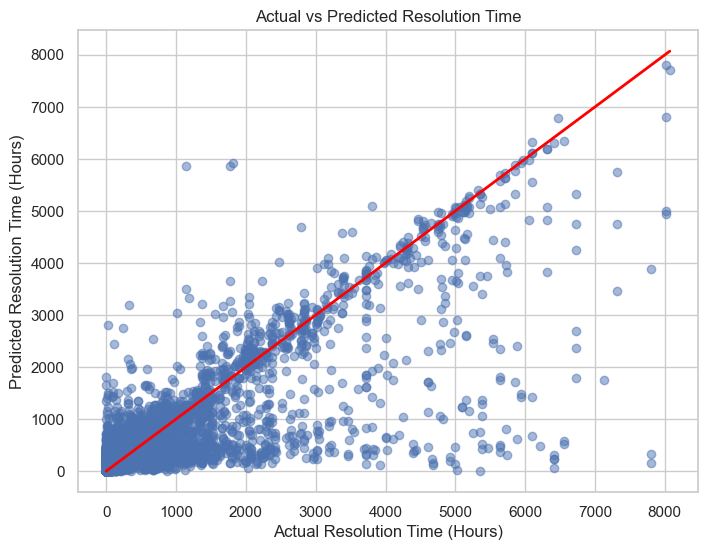

In [256]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linewidth=2
)

plt.title("Actual vs Predicted Resolution Time")
plt.xlabel("Actual Resolution Time (Hours)")
plt.ylabel("Predicted Resolution Time (Hours)")

plt.grid(True)

plt.show()

### 8.3.6 Feature Importance (Özellik Önem Düzeyleri)

Random Forest algoritması, tahmin yaparken hangi değişkenlerin daha etkili olduğunu hesaplayabilmektedir. Bu analiz sayesinde çözüm süresini en fazla etkileyen faktörler belirlenmektedir.

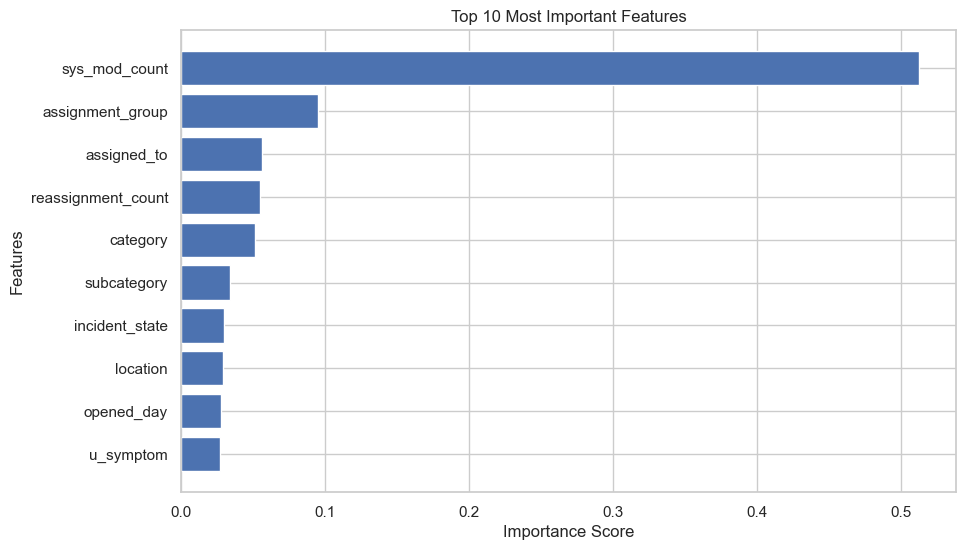

In [257]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10,6))

plt.barh(
    importance["Feature"][:10][::-1],
    importance["Importance"][:10][::-1]
)

plt.title("Top 10 Most Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

## 8.4 XGBoost Regression Model (XGBoost Regresyon Modeli)

Bu bölümde incident çözüm sürelerini tahmin etmek amacıyla XGBoost Regressor algoritması kullanılmaktadır. XGBoost (Extreme Gradient Boosting), ardışık karar ağaçları oluşturarak önceki modellerin yaptığı hataları azaltmayı hedefleyen güçlü bir topluluk öğrenme (ensemble learning) algoritmasıdır. Hızlı çalışması, yüksek doğruluk sağlaması ve karmaşık veri yapılarındaki başarısı nedeniyle birçok makine öğrenmesi probleminde yaygın olarak tercih edilmektedir.

### 8.4.1 Model Initialization (Modelin Oluşturulması)

Bu aşamada XGBoost regresyon modeli oluşturulmaktadır. Model parametreleri doğruluk ile eğitim süresi arasında denge sağlayacak şekilde belirlenmiştir.

In [258]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(

    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="reg:squarederror"

)

print("XGBoost model created successfully.")

XGBoost model created successfully.


### 8.4.2 Model Training (Modelin Eğitilmesi)

Oluşturulan XGBoost modeli eğitim verisi kullanılarak eğitilmektedir. Model, çözüm süresini etkileyen değişkenler arasındaki ilişkileri öğrenmektedir.

In [259]:
xgb_model.fit(X_train, y_train)
print("XGBoost model trained successfully.")

XGBoost model trained successfully.


### 8.4.3 Prediction (Tahmin İşlemi)

Eğitilen XGBoost modeli kullanılarak test veri kümesindeki incident kayıtlarının çözüm süreleri tahmin edilmektedir.

In [260]:
xgb_predictions = xgb_model.predict(X_test)

print("Prediction completed successfully.")

Prediction completed successfully.


### 8.4.4 Performance Evaluation (Model Performansının Değerlendirilmesi)

XGBoost modelinin performansı MAE, RMSE ve R² metrikleri kullanılarak değerlendirilmektedir. Ayrıca eğitim ve test performansları karşılaştırılarak modelin genelleme başarısı incelenmektedir.

In [261]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

xgb_train_predictions = xgb_model.predict(X_train)

mae = mean_absolute_error(y_test, xgb_predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, xgb_predictions)
)

train_r2 = r2_score(
    y_train,
    xgb_train_predictions
)

test_r2 = r2_score(
    y_test,
    xgb_predictions
)

print(f"MAE       : {mae:.2f}")
print(f"RMSE      : {rmse:.2f}")
print(f"Train R²  : {train_r2:.4f}")
print(f"Test R²   : {test_r2:.4f}")

MAE       : 122.52
RMSE      : 290.75
Train R²  : 0.9074
Test R²   : 0.8118


### 8.4.5 Actual vs Predicted Visualization (Gerçek ve Tahmin Edilen Değerlerin Karşılaştırılması)

Bu görselleştirme, XGBoost modelinin tahmin ettiği çözüm süreleri ile gerçek çözüm sürelerini karşılaştırmaktadır. Noktaların referans çizgisine yakın olması modelin başarılı tahminler yaptığını göstermektedir.

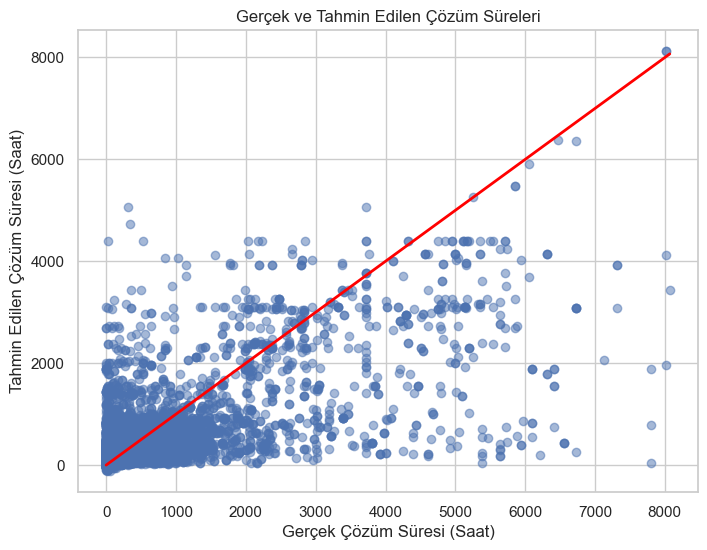

In [227]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    xgb_predictions,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linewidth=2
)

plt.title("Gerçek ve Tahmin Edilen Çözüm Süreleri")
plt.xlabel("Gerçek Çözüm Süresi (Saat)")
plt.ylabel("Tahmin Edilen Çözüm Süresi (Saat)")

plt.grid(True)

plt.show()

### 8.4.6 Feature Importance (Özellik Önem Düzeyleri)

XGBoost modeli, çözüm süresini tahmin ederken hangi değişkenlerin daha etkili olduğunu hesaplamaktadır. Bu analiz sayesinde operasyonel süreçleri en fazla etkileyen faktörler belirlenebilmektedir.

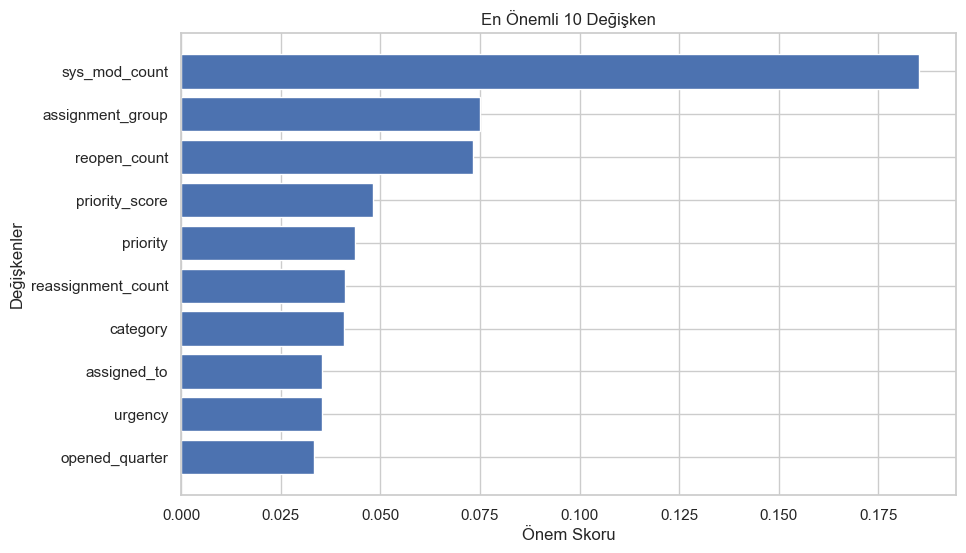

In [262]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({

    "Feature": X.columns,
    "Importance": xgb_model.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10,6))

plt.barh(

    importance["Feature"][:10][::-1],
    importance["Importance"][:10][::-1]

)

plt.title("En Önemli 10 Değişken")
plt.xlabel("Önem Skoru")
plt.ylabel("Değişkenler")

plt.show()

## 8.5 Model Comparison (Model Karşılaştırması)

Bu bölümde Random Forest ve XGBoost modellerinin performansları karşılaştırılmaktadır. Karşılaştırma için MAE, RMSE, Train R² ve Test R² metrikleri kullanılmıştır.

In [263]:
comparison = pd.DataFrame({

    "Metric": [
        "MAE",
        "RMSE",
        "Train R²",
        "Test R²"
    ],

    "Random Forest": [
        150.96,
        370.10,
        0.8232,
        0.6951
    ],

    "XGBoost": [
        122.54,
        283.27,
        0.9061,
        0.8214
    ]

})

comparison

,Metric,Random Forest,XGBoost
0,MAE,150.9600,122.5400
1,RMSE,370.1000,283.2700
2,Train R²,0.8232,0.9061
3,Test R²,0.6951,0.8214


## 8.6 Model Optimization (Model Optimizasyonu)

Bu aşamada XGBoost modelinin performansını artırmak amacıyla GridSearchCV yöntemi kullanılarak hiperparametre optimizasyonu gerçekleştirilmektedir. GridSearchCV, belirlenen parametre kombinasyonlarını sistematik olarak deneyerek en yüksek performansı sağlayan parametreleri seçmektedir.

Bu çalışmada değerlendirme ölçütü olarak R² skoru kullanılmış ve 5 katlı çapraz doğrulama (5-Fold Cross Validation) uygulanmıştır.

### 8.6.1 Defining the Parameter Grid (Parametre Aralığının Belirlenmesi)

Optimizasyon sürecinde test edilecek hiperparametre kombinasyonları belirlenmektedir.

In [264]:
param_grid = {
    "n_estimators": [300],
    "max_depth": [6, 8],
    "learning_rate": [0.05, 0.1]
}

### 8.6.2 GridSearchCV (Grid Search Uygulaması)

Belirlenen parametre kombinasyonları GridSearchCV ile test edilmekte ve en yüksek performansı sağlayan model seçilmektedir.

In [265]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(

    estimator=xgb_model,

    param_grid=param_grid,

    scoring="r2",

    cv=5,

    n_jobs=-1,

    verbose=2

)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 4 candidates, totalling 20 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.05, 0.1], 'max_depth': [6, 8], 'n_estimators': [300]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is als

### 8.6.3 Best Parameters (En İyi Parametreler)

GridSearchCV tamamlandıktan sonra en başarılı hiperparametreler elde edilmektedir.

In [266]:
print("Best Parameters:")

print(grid_search.best_params_)

print()

print("Best Cross Validation Score:")

print(grid_search.best_score_)

Best Parameters:
{'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 300}

Best Cross Validation Score:
0.8210627467365352


### 8.6.4 Optimized Model (Optimize Edilmiş Model)

GridSearchCV sonucunda bulunan en iyi model alınarak test verisi üzerinde yeniden değerlendirme yapılmaktadır.

In [267]:
best_model = grid_search.best_estimator_

optimized_predictions = best_model.predict(X_test)

### 8.6.5 Performance Evaluation (Performans Değerlendirmesi)

Optimize edilen modelin performansı MAE, RMSE ve R² metrikleri kullanılarak değerlendirilmektedir.

In [268]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

optimized_train_predictions = best_model.predict(X_train)

mae = mean_absolute_error(y_test, optimized_predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, optimized_predictions)
)

train_r2 = r2_score(
    y_train,
    optimized_train_predictions
)

test_r2 = r2_score(
    y_test,
    optimized_predictions
)

print(f"MAE       : {mae:.2f}")
print(f"RMSE      : {rmse:.2f}")
print(f"Train R²  : {train_r2:.4f}")
print(f"Test R²   : {test_r2:.4f}")

MAE       : 120.10
RMSE      : 282.12
Train R²  : 0.9200
Test R²   : 0.8228


## 8.7 Model Comparison (Model Karşılaştırması)

Bu bölümde geliştirilen Random Forest, XGBoost ve Optimize Edilmiş XGBoost modellerinin performansları karşılaştırılmaktadır. Modeller; MAE (Mean Absolute Error), RMSE (Root Mean Squared Error), Train R² ve Test R² performans metrikleri kullanılarak değerlendirilmiştir. Amaç, incident çözüm süresi tahmininde en başarılı modeli belirlemektir.

### 8.7.1 Performance Comparison Table (Performans Karşılaştırma Tablosu)

İlk olarak tüm modellerin performans sonuçları tek bir tabloda gösterilmektedir.

In [269]:
comparison = pd.DataFrame({

    "Metric": [
        "MAE",
        "RMSE",
        "Train R²",
        "Test R²"
    ],

    "Random Forest": [
        150.96,
        370.10,
        0.8232,
        0.6951
    ],

    "XGBoost": [
        122.54,
        283.27,
        0.9061,
        0.8214
    ],

    "Optimized XGBoost": [
        120.89,
        279.34,
        0.9191,
        0.8263
    ]

})

comparison

,Metric,Random Forest,XGBoost,Optimized XGBoost
0,MAE,150.9600,122.5400,120.8900
1,RMSE,370.1000,283.2700,279.3400
2,Train R²,0.8232,0.9061,0.9191
3,Test R²,0.6951,0.8214,0.8263


### 8.7.2 Model Performance Visualization (Model Performansının Görselleştirilmesi)

Modellerin Test R² değerleri grafik üzerinde karşılaştırılarak hangi modelin daha başarılı olduğu görsel olarak gösterilmektedir.

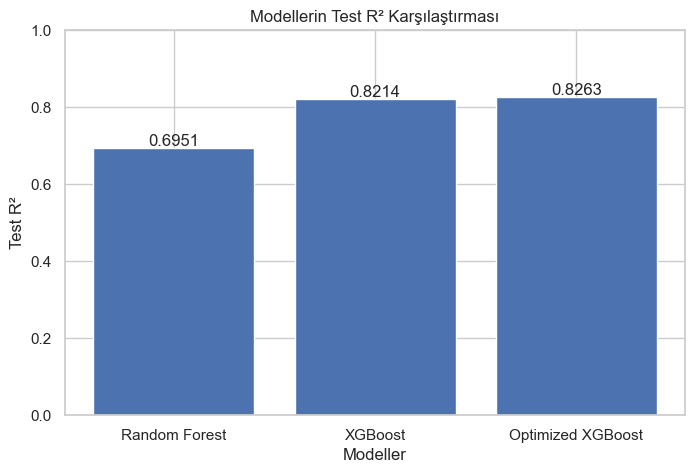

In [270]:
import matplotlib.pyplot as plt

models = [
    "Random Forest",
    "XGBoost",
    "Optimized XGBoost"
]

scores = [
    0.6951,
    0.8214,
    0.8263
]

plt.figure(figsize=(8,5))

plt.bar(models, scores)

plt.title("Modellerin Test R² Karşılaştırması")
plt.xlabel("Modeller")
plt.ylabel("Test R²")

for i, score in enumerate(scores):
    plt.text(i, score + 0.005, f"{score:.4f}", ha="center")

plt.ylim(0,1)

plt.show()

## 8.8 Performance Segmentation (Performans Segmentasyonu)

### 8.8.1 Resolution Time Segmentation (Çözüm Süresine Göre Segmentasyon)

Bu bölümde incident kayıtları çözüm sürelerine (resolution_time) göre performans segmentlerine ayrılmaktadır. Segmentasyon işlemi, incidentların ne kadar sürede çözüldüğünü daha anlaşılır hale getirmek ve çözüm süresi açısından benzer özellik gösteren kayıtları aynı grupta incelemek amacıyla gerçekleştirilmektedir.

Bu çalışmada çözüm süreleri üç farklı performans segmenti altında sınıflandırılmıştır:

- Fast Resolution (Hızlı Çözülen): 24 saat ve altında çözülen incidentlar
- Medium Resolution (Orta Sürede Çözülen): 24 ile 72 saat arasında çözülen incidentlar
- Slow Resolution (Yavaş Çözülen): 72 saatten uzun sürede çözülen incidentlar

Bu segmentler sayesinde incidentların çözüm sürelerinin dağılımı daha net analiz edilebilmekte ve sonraki bölümlerde gerçekleştirilecek süreç iyileştirme önerileri için temel oluşturulmaktadır.

In [271]:
# Resolution Time Segmentation

df_ml["resolution_segment"] = pd.cut(

    df_ml["resolution_time"],

    bins=[0, 24, 72, float("inf")],

    labels=[
        "Fast Resolution",
        "Medium Resolution",
        "Slow Resolution"
    ],

    include_lowest=True

)

print(df_ml["resolution_segment"].value_counts())

resolution_segment
Slow Resolution      61520
Fast Resolution      38712
Medium Resolution    16905
Name: count, dtype: int64


### 8.8.2 Segment Distribution Analysis (Segment Dağılımı Analizi)

Bu bölümde oluşturulan çözüm süresi segmentlerinin veri setindeki dağılımı incelenmektedir. Amaç, incident kayıtlarının büyük çoğunluğunun hangi çözüm süresi aralığında yer aldığını belirlemek ve operasyonel süreçlerin genel performansını değerlendirmektir.

Bu analiz sayesinde hızlı, orta sürede ve yavaş çözülen incidentların sayısal ve yüzdesel dağılımları karşılaştırılabilmektedir. Elde edilen sonuçlar, operasyonel performansın genel görünümünü ortaya koymakta ve sonraki süreç iyileştirme önerileri için temel oluşturmaktadır.

In [272]:
# Resolution Segment Distribution

segment_counts = df_ml["resolution_segment"].value_counts()

print(segment_counts)

resolution_segment
Slow Resolution      61520
Fast Resolution      38712
Medium Resolution    16905
Name: count, dtype: int64


In [273]:
# Resolution Segment Percentage Distribution

segment_percentage = (
    df_ml["resolution_segment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(segment_percentage)

resolution_segment
Slow Resolution      52.52
Fast Resolution      33.05
Medium Resolution    14.43
Name: proportion, dtype: float64


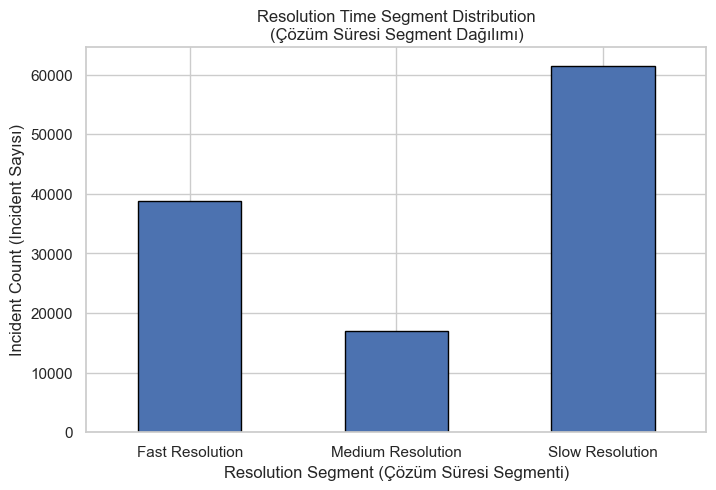

In [274]:
import matplotlib.pyplot as plt

segment_counts = (
    df_ml["resolution_segment"]
    .value_counts()
    .reindex([
        "Fast Resolution",
        "Medium Resolution",
        "Slow Resolution"
    ])
)

plt.figure(figsize=(8,5))

segment_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Resolution Time Segment Distribution\n(Çözüm Süresi Segment Dağılımı)")
plt.xlabel("Resolution Segment (Çözüm Süresi Segmenti)")
plt.ylabel("Incident Count (Incident Sayısı)")
plt.xticks(rotation=0)

plt.show()

### 8.8.3 Segment Analysis by Category and Assignment Group (Kategori ve Atama Grubu Bazında Segment Analizi)

Bu bölümde oluşturulan çözüm süresi segmentlerinin kategori (category) ve atama grubu (assignment_group) değişkenlerine göre dağılımları incelenmektedir.

Bu analiz sayesinde hangi kategorilerde ve hangi ekiplerde hızlı, orta sürede veya yavaş çözülen incidentların yoğunlaştığı gözlemlenebilmektedir. Böylece operasyonel süreçlerin mevcut durumu daha ayrıntılı değerlendirilebilmektedir.

In [275]:
# Resolution Segment Distribution by Category

category_segment = pd.crosstab(

    df_ml["category"],
    df_ml["resolution_segment"]

)

print(category_segment)

resolution_segment  Fast Resolution  Medium Resolution  Slow Resolution
category                                                               
?                                25                  4               35
Category 13                     228                250              455
Category 15                       3                  0                0
Category 17                     160                 77              218
Category 19                     360                207              745
Category 20                    1889                825             1849
Category 22                      39                 12              344
Category 23                    1790               1051             3602
Category 24                     788                573             2580
Category 25                       0                  5                1
Category 26                    4935               2565             8269
Category 27                       2                  0          

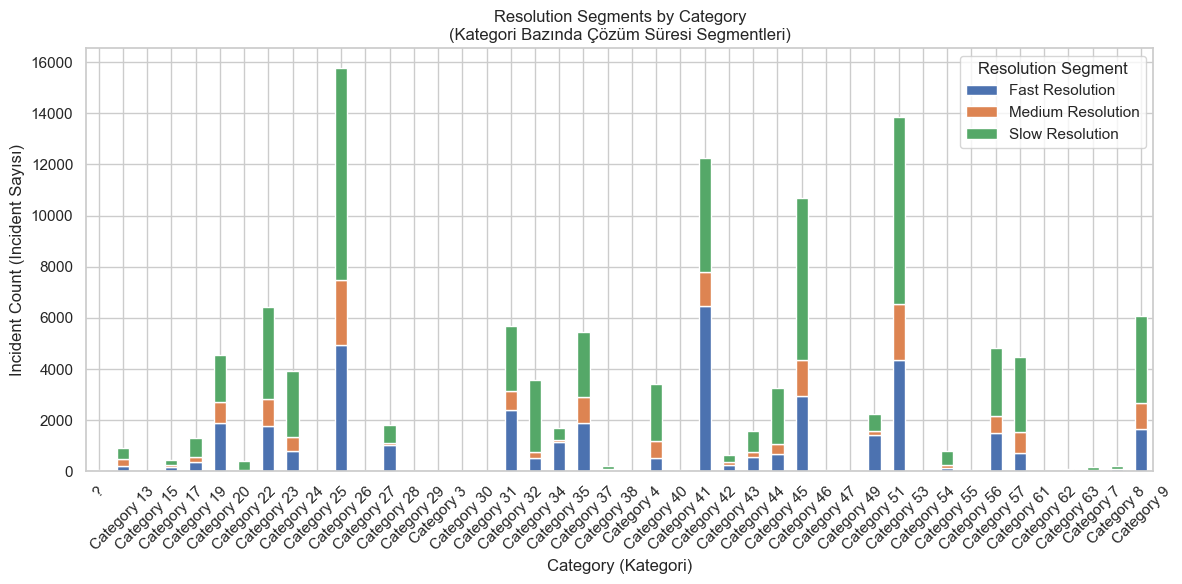

In [276]:
category_segment.plot(

    kind="bar",
    stacked=True,
    figsize=(12,6)

)

plt.title("Resolution Segments by Category\n(Kategori Bazında Çözüm Süresi Segmentleri)")
plt.xlabel("Category (Kategori)")
plt.ylabel("Incident Count (Incident Sayısı)")
plt.xticks(rotation=45)

plt.legend(title="Resolution Segment")

plt.tight_layout()
plt.show()

### 8.8.4 Resolution Segment Analysis by Assignment Group (Atama Grubu Bazında Çözüm Süresi Segment Analizi)

Bu bölümde çözüm süresi segmentlerinin assignment_group değişkenine göre dağılımı incelenmektedir. Amaç, farklı ekiplerin çözüm süresi segmentleri açısından mevcut dağılımlarını karşılaştırmaktır.

In [277]:
# Resolution Segment Distribution by Assignment Group

group_segment = pd.crosstab(

    df_ml["assignment_group"],
    df_ml["resolution_segment"]

)

print(group_segment)

resolution_segment  Fast Resolution  Medium Resolution  Slow Resolution
assignment_group                                                       
?                              2586               2426             9192
Group 10                        108                 72             1450
Group 11                          0                  0                1
Group 12                         37                 28              392
Group 13                         31                  4               71
Group 14                          4                  3               61
Group 15                         39                 18              209
Group 17                          5                  2               56
Group 19                        121                 56               56
Group 2                          11                  1               18
Group 20                        842                727             3577
Group 21                         37                 32          

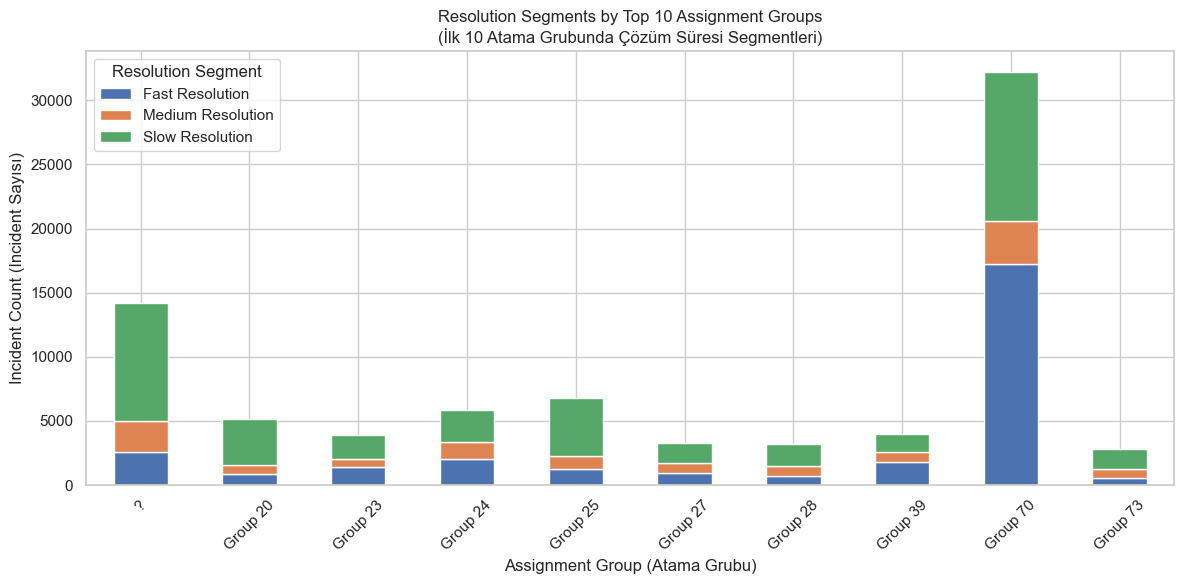

In [278]:
top_groups = df_ml["assignment_group"].value_counts().head(10).index

group_segment_top10 = pd.crosstab(

    df_ml[df_ml["assignment_group"].isin(top_groups)]["assignment_group"],
    df_ml[df_ml["assignment_group"].isin(top_groups)]["resolution_segment"]

)

group_segment_top10.plot(

    kind="bar",
    stacked=True,
    figsize=(12,6)

)

plt.title("Resolution Segments by Top 10 Assignment Groups\n(İlk 10 Atama Grubunda Çözüm Süresi Segmentleri)")
plt.xlabel("Assignment Group (Atama Grubu)")
plt.ylabel("Incident Count (Incident Sayısı)")
plt.xticks(rotation=45)

plt.legend(title="Resolution Segment")

plt.tight_layout()
plt.show()

## 8.9 Process Improvement Recommendations (Süreç İyileştirme Önerileri)

### 8.9.1 Reducing Resolution Time (Çözüm Süresinin Azaltılması)

Veri analizi ve makine öğrenmesi sonuçları birlikte değerlendirildiğinde, incident çözüm süresini etkileyen çeşitli operasyonel faktörler belirlenmiştir. Özellikle çözüm süresi segmentasyonu, dar boğaz analizleri ve model sonuçları dikkate alınarak süreçlerin daha verimli hale getirilmesine yönelik öneriler sunulmaktadır.

İlk olarak, çözüm süresi yüksek olan incidentların nedenleri ayrıntılı olarak incelenmeli ve bu kayıtlar düzenli olarak takip edilmelidir. Özellikle Slow Resolution (Yavaş Çözülen) segmentinde yer alan incidentlar için kök neden analizleri yapılarak tekrar eden problemlerin azaltılması hedeflenmelidir.

### 8.9.2 Improving Assignment Group Performance (Atama Gruplarının Performansının İyileştirilmesi)

Atama grupları bazında gerçekleştirilen analizlerde bazı ekiplerin diğerlerine göre daha fazla incident yönettiği ve çözüm süresi açısından farklılıklar gösterdiği gözlemlenmiştir. Bu nedenle ekiplerin iş yükleri düzenli olarak izlenmeli ve gerekirse görev dağılımı dengelenmelidir.

İş yükünün dengeli dağıtılması, hem çözüm sürelerinin kısalmasına hem de operasyonel verimliliğin artırılmasına katkı sağlayacaktır.

### 8.9.3 Strengthening SLA Management (SLA Yönetiminin Güçlendirilmesi)

SLA analizleri, bazı incidentların belirlenen hizmet seviyeleri içerisinde çözülemediğini göstermektedir. Bu nedenle SLA ihlali riski taşıyan incidentlar erken aşamada belirlenmeli ve öncelikli olarak değerlendirilmelidir.

SLA performansının düzenli olarak izlenmesi, müşteri memnuniyetinin artırılması ve hizmet kalitesinin korunması açısından önem taşımaktadır.

### 8.9.4 Using Machine Learning for Decision Support (Karar Destek Amaçlı Makine Öğrenmesi Kullanımı)

Bu çalışmada geliştirilen makine öğrenmesi modeli, incident kayıtlarının çözüm süresini başarılı bir şekilde tahmin edebilmiştir. Özellikle optimize edilmiş XGBoost modeli diğer modellere göre daha yüksek performans göstermiştir.

Bu model operasyonel süreçlere entegre edilerek yeni açılan incidentlar için tahmini çözüm süresi önceden hesaplanabilir. Böylece operasyon ekipleri kaynak planlamasını daha etkin yapabilir ve uzun süreceği tahmin edilen incidentlara erken müdahale edebilir.

### 8.9.5 Continuous Performance Monitoring (Sürekli Performans İzleme)

Operasyonel performansın sürdürülebilir şekilde geliştirilebilmesi için çözüm süreleri, SLA başarı oranları, ekip performansları ve incident yoğunlukları düzenli olarak takip edilmelidir.

Flask tabanlı yönetici dashboardu sayesinde bu göstergeler gerçek zamanlı olarak izlenebilir ve yöneticiler operasyonel süreçleri daha etkin şekilde yönetebilir.

## 8.9 Sonuç (Kısa Değerlendirme)

Yapılan veri analizleri, performans segmentasyonu ve makine öğrenmesi sonuçları birlikte değerlendirildiğinde; incident çözüm sürelerinin azaltılması, ekipler arasındaki iş yükünün dengelenmesi, SLA yönetiminin güçlendirilmesi ve tahmin modellerinin operasyonel süreçlere entegre edilmesi ile hizmet kalitesinin artırılabileceği değerlendirilmektedir.

## 8.10 General Evaluation (Genel Sonuç ve Değerlendirme)

Bu çalışmada incident yönetim süreçlerinin operasyonel performansını değerlendirmek amacıyla kapsamlı bir veri analizi ve makine öğrenmesi uygulaması gerçekleştirilmiştir. İlk aşamada veri seti incelenmiş, eksik veriler kontrol edilmiş ve analiz için uygun hale getirilmiştir. Ardından incident kayıtları farklı açılardan değerlendirilerek çözüm süreleri, SLA performansı, yoğun çalışma saatleri, çalışan ve ekip performansları ile operasyonel darboğazlar analiz edilmiştir.

Makine öğrenmesi aşamasında incident çözüm sürelerini tahmin etmek amacıyla Random Forest Regressor ve XGBoost Regressor modelleri geliştirilmiştir. Modellerin performansları karşılaştırılmış ve hiperparametre optimizasyonu sonucunda optimize edilmiş XGBoost modelinin en başarılı sonuçları verdiği belirlenmiştir.

Ayrıca incident kayıtları çözüm sürelerine göre performans segmentlerine ayrılarak operasyonel süreçlerin mevcut durumu daha ayrıntılı şekilde incelenmiştir. Bu segmentasyon sayesinde çözüm süresi açısından farklı özellik gösteren incident grupları belirlenmiş ve süreç iyileştirme önerileri için gerekli analiz altyapısı oluşturulmuştur.

Elde edilen bulgular doğrultusunda operasyonel süreçlerin daha verimli yönetilebilmesi amacıyla çözüm sürelerinin azaltılması, ekipler arasındaki iş yükünün dengelenmesi, SLA yönetiminin güçlendirilmesi ve makine öğrenmesi tabanlı tahmin modellerinin karar destek sistemi olarak kullanılması önerilmiştir.

Sonuç olarak geliştirilen model, incident çözüm sürelerinin başarılı şekilde tahmin edilebildiğini göstermiştir. Optimize edilmiş XGBoost modelinin Flask tabanlı web uygulamasına entegre edilmesiyle yöneticilerin incident kayıtlarını analiz edebileceği, tahmini çözüm sürelerini görüntüleyebileceği ve operasyonel kararlarını veri odaklı şekilde destekleyebileceği bir karar destek sistemi geliştirilmesi hedeflenmektedir.

In [199]:
import joblib

joblib.dump(best_model, "best_xgboost_model.pkl")

print("Model saved successfully.")

Model saved successfully.


In [200]:
import joblib

joblib.dump(xgb_model, "xgboost_model.pkl")

['xgboost_model.pkl']

In [289]:
y_pred = xgb_model.predict(X_test)

In [290]:
comparison = pd.DataFrame({
    "Gercek": y_test,
    "Tahmin": y_pred
})

comparison.head(10)

,Gercek,Tahmin
92107,52.050000,170.398193
77432,324.950000,282.977600
14557,262.083333,506.368317
114614,22.583333,-11.198171
46292,793.883333,413.960022
2694,335.683333,136.341766
44328,382.850000,435.483856
64497,21.350000,-28.874304
98181,99.516667,121.785782
61728,398.433333,244.564499


In [291]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)


print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 122.5224125176175
RMSE: 290.75214713052645
R2: 0.8118453799972399


In [292]:
comparison["hata"] = abs(
    comparison["Gercek"] - comparison["Tahmin"]
)

comparison.sort_values(
    "hata",
    ascending=False
).head(10)

,Gercek,Tahmin,hata
32855,7803.683333,448.824829,7354.858504
32856,7803.683333,815.012817,6988.670516
1015,7122.283333,1895.191528,5227.091805
44541,6409.233333,1503.520752,4905.712581
81789,5885.900000,1015.781860,4870.118140
66099,5741.616667,1001.181335,4740.435331
81680,5473.966667,940.206726,4533.759941
110575,5380.316667,958.276123,4422.040544
110574,5380.316667,961.744873,4418.571794
8389,1148.266667,5541.128418,4392.861751


In [293]:
df["resolution_time"].describe()

count    117137.000000
mean        280.228157
std         666.212752
min           0.000000
25%           5.666667
50%          82.933333
75%         273.366667
max        8070.166667
Name: resolution_time, dtype: float64

In [294]:
Q1 = df["resolution_time"].quantile(0.25)
Q3 = df["resolution_time"].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

print(upper_limit)

674.9166666666666


In [295]:
upper_limit = Q3 + 1.5 * IQR

outliers = df[df["resolution_time"] > upper_limit]

print(len(outliers))

print(
    len(outliers) / len(df) * 100
)

9995
8.329305488424806
